In [1]:

from pathlib import Path
import os
import sys

PROJECT = Path("/home/cse-sdpl/Downloads/CMX_Original")
assert PROJECT.exists(), f"Project not found: {PROJECT}"

os.chdir(PROJECT)

print("Project:", Path.cwd())
print("Python:", sys.executable)
print("Python version:", sys.version)


Project: /home/cse-sdpl/Downloads/CMX_Original
Python: /usr/bin/python3
Python version: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation


In [2]:

import sys
import torch
from pathlib import Path

PROJECT = Path("/home/cse-sdpl/Downloads/CMX_Original")

print("Python executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

assert PROJECT.exists(), "CMX project directory not found"

net_utils_path = PROJECT / "models" / "net_utils.py"
source = net_utils_path.read_text()

for class_name in [
    "class FeatureRectifyModule",
    "class FeatureFusionModule"
]:
    start = source.find(class_name)
    print(f"\n{'=' * 65}\n{class_name}")

    if start == -1:
        print("Not found")
    else:
        print(source[start:start + 3000])


Python executable: /home/cse-sdpl/miniconda3/envs/cmx/bin/python
PyTorch: 2.14.1+cu130
CUDA: True
GPU: NVIDIA RTX 2000 Ada Generation

class FeatureRectifyModule
class FeatureRectifyModule(nn.Module):
    def __init__(self, dim, reduction=1, lambda_c=.5, lambda_s=.5):
        super(FeatureRectifyModule, self).__init__()
        self.lambda_c = lambda_c
        self.lambda_s = lambda_s
        self.channel_weights = ChannelWeights(dim=dim, reduction=reduction)
        self.spatial_weights = SpatialWeights(dim=dim, reduction=reduction)
    
    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.LayerNorm):
            nn.init.constant_(m.bias, 0)
            nn.init.constant_(m.weight, 1.0)
        elif isinstance(m, nn.Conv2d):
            fan_out = m.kernel_size[0] * m.kernel_size[1] * m.out

In [3]:
 # Inspect MiT-B2 feature dimensions

In [4]:

from pathlib import Path
import re

source = Path("models/encoders/dual_segformer.py").read_text()

# Find the MiT-B2 encoder configuration
for pattern in [
    r"embed_dims\s*=\s*\[[^\]]+\]",
    r"num_heads\s*=\s*\[[^\]]+\]",
    r"self\.FRMs\s*=\s*nn\.ModuleList",
    r"self\.FFMs\s*=\s*nn\.ModuleList",
]:
    print(f"\nSearching: {pattern}")
    matches = re.findall(pattern, source)
    for match in matches:
        print(match)



Searching: embed_dims\s*=\s*\[[^\]]+\]
embed_dims=[64, 128, 256, 512]
embed_dims=[32, 64, 160, 256]
embed_dims=[64, 128, 320, 512]
embed_dims=[64, 128, 320, 512]
embed_dims=[64, 128, 320, 512]
embed_dims=[64, 128, 320, 512]
embed_dims=[64, 128, 320, 512]

Searching: num_heads\s*=\s*\[[^\]]+\]
num_heads=[1, 2, 4, 8]
num_heads=[1, 2, 5, 8]
num_heads=[1, 2, 5, 8]
num_heads=[1, 2, 5, 8]
num_heads=[1, 2, 5, 8]
num_heads=[1, 2, 5, 8]
num_heads=[1, 2, 5, 8]

Searching: self\.FRMs\s*=\s*nn\.ModuleList
self.FRMs = nn.ModuleList

Searching: self\.FFMs\s*=\s*nn\.ModuleList
self.FFMs = nn.ModuleList


In [5]:
# Test the reliability head independently

In [6]:

import torch
import torch.nn as nn

class ReliabilityHeadPrototype(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.shared = nn.Sequential(
            nn.Conv2d(channels * 2, channels, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels // 2, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

        self.rgb_head = nn.Conv2d(channels // 2, 1, kernel_size=1)
        self.thermal_head = nn.Conv2d(channels // 2, 1, kernel_size=1)

    def forward(self, rgb_features, thermal_features):
        combined = torch.cat(
            [rgb_features, thermal_features], dim=1
        )
        hidden = self.shared(combined)

        rgb_reliability = torch.sigmoid(self.rgb_head(hidden))
        thermal_reliability = torch.sigmoid(self.thermal_head(hidden))

        return rgb_reliability, thermal_reliability


# Test with a representative stage-1 feature map
device = "cuda" if torch.cuda.is_available() else "cpu"

head = ReliabilityHeadPrototype(channels=64).to(device)
rgb = torch.randn(2, 64, 32, 32, device=device)
thermal = torch.randn(2, 64, 32, 32, device=device)

r_rgb, r_thermal = head(rgb, thermal)

print("RGB reliability shape:", r_rgb.shape)
print("Thermal reliability shape:", r_thermal.shape)
print("RGB reliability range:",
      (r_rgb.min().item(), r_rgb.max().item()))
print("Thermal reliability range:",
      (r_thermal.min().item(), r_thermal.max().item()))


RGB reliability shape: torch.Size([2, 1, 32, 32])
Thermal reliability shape: torch.Size([2, 1, 32, 32])
RGB reliability range: (0.4800366163253784, 0.6040343046188354)
Thermal reliability range: (0.4352293610572815, 0.5467004776000977)


In [7]:
 # Inspect the TDD dataset in Jupyter

In [8]:

from pathlib import Path
import numpy as np
from PIL import Image

PROJECT = Path("/home/cse-sdpl/Downloads/CMX_Original")
DATASET = PROJECT / "datasets" / "TDD"

print("Dataset exists:", DATASET.exists())
print("Dataset folders:")
for p in sorted(DATASET.iterdir()):
    print(" ", p.name, "(directory)" if p.is_dir() else "(file)")

# Inspect dataset split sizes
for split in ["train.txt", "val.txt", "test.txt"]:
    p = DATASET / split
    if p.exists():
        lines = [x.strip() for x in p.read_text().splitlines() if x.strip()]
        print(f"{split}: {len(lines)} entries")
    else:
        print(f"{split}: not found at dataset root")

# Inspect one RGB, thermal and label image
for folder in ["RGB", "Thermal", "Label"]:
    directory = DATASET / folder
    if not directory.exists():
        print(f"\n{folder}: folder not found")
        continue

    files = sorted(directory.glob("*.png"))
    print(f"\n{folder}: {len(files)} PNG files")

    if files:
        with Image.open(files[0]) as im:
            arr = np.array(im)
            print("Sample:", files[0].name)
            print("Shape:", arr.shape)
            print("Data type:", arr.dtype)

            if folder == "Label":
                print("Unique label IDs:", np.unique(arr).tolist())


Dataset exists: True
Dataset folders:
  Label (directory)
  RGB (directory)
  Thermal (directory)
  test.txt (file)
  train.txt (file)
  val.txt (file)
train.txt: 1568 entries
val.txt: 392 entries
test.txt: 393 entries

RGB: 2353 PNG files
Sample: 00001D.png
Shape: (480, 640, 3)
Data type: uint8

Thermal: 2353 PNG files
Sample: 00001D.png
Shape: (480, 640)
Data type: uint8

Label: 2353 PNG files
Sample: 00001D.png
Shape: (480, 640)
Data type: uint8
Unique label IDs: [0, 1, 2, 3]


In [9]:
 # Create RGB and thermal corruption functions in Jupyter

In [10]:

import numpy as np
from PIL import Image, ImageFilter, ImageEnhance
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT = Path("/home/cse-sdpl/Downloads/CMX_Original")
DATASET = PROJECT / "datasets" / "TDD"

def corrupt_rgb(image, kind="low_light", severity=1, seed=42):
    """RGB corruption. Input/output: uint8 H x W x 3."""
    x = np.asarray(image.convert("RGB"), dtype=np.uint8).copy()
    rng = np.random.default_rng(seed)
    severity = float(np.clip(severity, 1, 3))

    if kind == "low_light":
        x = (x.astype(np.float32) * (0.55 ** severity)).clip(0, 255)
        return Image.fromarray(x.astype(np.uint8))

    if kind == "gaussian_noise":
        noise = rng.normal(0, 8 * severity, x.shape)
        x = np.clip(x.astype(np.float32) + noise, 0, 255)
        return Image.fromarray(x.astype(np.uint8))

    if kind == "motion_blur":
        # Approximate motion blur using a directional PIL filter.
        return image.convert("RGB").filter(ImageFilter.Kernel(
            size=(3, 3),
            kernel=[0, 0, 0, 1/3, 1/3, 1/3, 0, 0, 0],
            scale=1
        ))

    if kind == "blackout":
        return Image.new("RGB", image.size, (0, 0, 0))

    raise ValueError(f"Unknown RGB corruption: {kind}")


def corrupt_thermal(image, kind="gaussian_noise", severity=1, seed=42):
    """Thermal corruption. Input/output: uint8 H x W."""
    x = np.asarray(image.convert("L"), dtype=np.uint8).copy()
    rng = np.random.default_rng(seed)
    severity = float(np.clip(severity, 1, 3))

    if kind == "gaussian_noise":
        noise = rng.normal(0, 8 * severity, x.shape)
        x = np.clip(x.astype(np.float32) + noise, 0, 255)
        return Image.fromarray(x.astype(np.uint8))

    if kind == "blur":
        radius = 0.7 * severity
        return image.convert("L").filter(
            ImageFilter.GaussianBlur(radius=radius)
        )

    if kind == "contrast_loss":
        return ImageEnhance.Contrast(image.convert("L")).enhance(
            1.0 / (1.0 + 0.6 * severity)
        )

    if kind == "blackout":
        return Image.new("L", image.size, 0)

    raise ValueError(f"Unknown thermal corruption: {kind}")


print("RGB and thermal corruption functions defined.")


RGB and thermal corruption functions defined.


In [11]:
# Visualize and validate the corruptions

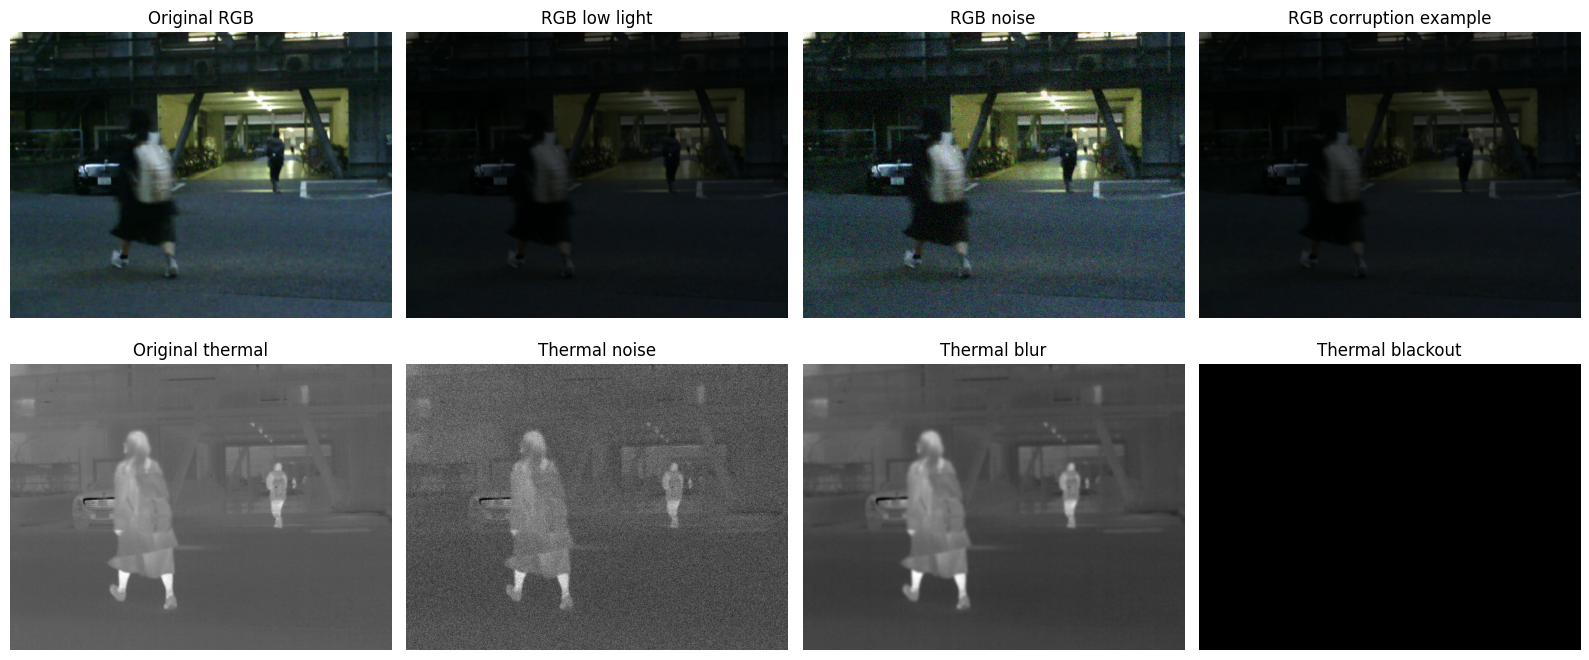

RGB shape: (480, 640, 3)
Thermal shape: (480, 640)
Label shape: (480, 640)
Label IDs: [0, 1, 2, 3]


In [12]:

sample_name = "00001D.png"

rgb_path = DATASET / "RGB" / sample_name
thermal_path = DATASET / "Thermal" / sample_name
label_path = DATASET / "Label" / sample_name

assert all(p.exists() for p in [rgb_path, thermal_path, label_path]), \
    "Sample image or label not found."

rgb = Image.open(rgb_path).convert("RGB")
thermal = Image.open(thermal_path).convert("L")
label = np.array(Image.open(label_path))

rgb_dark = corrupt_rgb(rgb, "low_light", severity=2)
rgb_noisy = corrupt_rgb(rgb, "gaussian_noise", severity=2)
thermal_noisy = corrupt_thermal(thermal, "gaussian_noise", severity=2)
thermal_blur = corrupt_thermal(thermal, "blur", severity=2)
thermal_blackout = corrupt_thermal(thermal, "blackout")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

images = [
    (rgb, "Original RGB"),
    (rgb_dark, "RGB low light"),
    (rgb_noisy, "RGB noise"),
    (rgb_dark, "RGB corruption example"),
    (thermal, "Original thermal"),
    (thermal_noisy, "Thermal noise"),
    (thermal_blur, "Thermal blur"),
    (thermal_blackout, "Thermal blackout"),
]

for ax, (img, title) in zip(axes.flat, images):
    ax.imshow(img, cmap="gray" if img.mode == "L" else None)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("RGB shape:", np.asarray(rgb).shape)
print("Thermal shape:", np.asarray(thermal).shape)
print("Label shape:", label.shape)
print("Label IDs:", np.unique(label).tolist())


In [13]:
# inspect the real CMX data loader

In [20]:

from pathlib import Path
import numpy as np
from PIL import Image
from collections import Counter

PROJECT = Path("/home/cse-sdpl/Downloads/CMX_Original")
DATASET = PROJECT / "datasets" / "TDD"

# 1. Inspect all training label IDs and pixel counts
train_ids = [
    line.strip()
    for line in (DATASET / "train.txt").read_text().splitlines()
    if line.strip()
]

class_pixels = Counter()
for sample_id in train_ids:
    label_path = DATASET / "Label" / sample_id
    if not label_path.exists():
        print("Missing label:", label_path)
        continue

    mask = np.array(Image.open(label_path))
    class_pixels.update(
        {int(k): int(v) for k, v in zip(*np.unique(mask, return_counts=True))}
    )

print("Training samples:", len(train_ids))
print("Training label pixel counts:")
for class_id, count in sorted(class_pixels.items()):
    print(f"  ID {class_id}: {count:,} pixels")

# 2. Locate CMX dataset loader files
print("\nDataset loader candidates:")
for path in sorted((PROJECT / "dataloader").rglob("*.py")):
    print(path.relative_to(PROJECT))

# 3. Inspect the configuration for dataset and normalization settings
config = (PROJECT / "config.py").read_text()
print("\nRelevant config lines:")
for line_no, line in enumerate(config.splitlines(), start=1):
    if any(word in line.lower() for word in
           ["dataset", "tdd", "mean", "std", "ignore_label", "num_classes"]):
        print(f"{line_no}: {line.strip()}")


Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00001D
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00001D_flip
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00002D
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00002D_flip
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00055D
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00055D_flip
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00056D
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00056D_flip
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00057D
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00057D_flip
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00058D
Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00058D_flip
Missing label: /home/c

In [18]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_Original")
label_dir = root / "datasets/TDD/Label"

for name in ["00994N", "00994N_flip"]:
    path_without_extension = label_dir / name
    path_with_extension = label_dir / f"{name}.png"

    print("Name:", name)
    print("Without extension:", path_without_extension.exists())
    print("With .png extension:", path_with_extension.exists())
    print()

Name: 00994N
Without extension: False
With .png extension: True

Name: 00994N_flip
Without extension: False
With .png extension: True



In [15]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

label_dir = root / "Label"
train_file = root / "train.txt"

train_ids = [
    line.strip()
    for line in train_file.read_text().splitlines()
    if line.strip()
]

label_files = {p.name for p in label_dir.iterdir() if p.is_file()}

print("Training IDs:", len(train_ids))
print("Actual label files:", len(label_files))
print("\nFirst 20 training IDs:")
print(train_ids[:20])

print("\nFirst 20 actual labels:")
print(sorted(label_files)[:20])

print("\nFilename checks:")
for name in ["00994N", "00994N_flip", "00001D", "00001D_flip"]:
    print(
        name,
        "PNG exists:", f"{name}.png" in label_files,
        "JPG exists:", f"{name}.jpg" in label_files
    )

print("\nPossible matching files for 00994:")
print([f for f in sorted(label_files) if "00994" in f][:20])

Training IDs: 1568
Actual label files: 2353

First 20 training IDs:
['00001D', '00001D_flip', '00002D', '00002D_flip', '00055D', '00055D_flip', '00056D', '00056D_flip', '00057D', '00057D_flip', '00058D', '00058D_flip', '00081D', '00081D_flip', '00082D', '00082D_flip', '00083D', '00083D_flip', '00084D', '00084D_flip']

First 20 actual labels:
['00001D.png', '00001D_flip.png', '00002D.png', '00002D_flip.png', '00003N.png', '00003N_flip.png', '00004N.png', '00004N_flip.png', '00005N.png', '00005N_flip.png', '00006N.png', '00006N_flip.png', '00007N.png', '00007N_flip.png', '00008N.png', '00008N_flip.png', '00009N.png', '00009N_flip.png', '00010N.png', '00010N_flip.png']

Filename checks:
00994N PNG exists: True JPG exists: False
00994N_flip PNG exists: True JPG exists: False
00001D PNG exists: True JPG exists: False
00001D_flip PNG exists: True JPG exists: False

Possible matching files for 00994:
['00994N.png', '00994N_flip.png']


In [24]:
from pathlib import Path

repo = Path("/home/cse-sdpl/Downloads/CMX_Original")

for path in repo.rglob("*.py"):
    if any(p.startswith(".") or p.startswith("log_")
           for p in path.parts):
        continue

    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    for i, line in enumerate(lines):
        if "Missing label:" in line:
            print(f"\nFile: {path}")
            for j in range(max(0, i-5), min(len(lines), i+6)):
                print(f"{j+1}: {lines[j]}")

In [26]:
from pathlib import Path

repo = Path("/home/sdpl/Downloads/CMX_Original")

# Correct the path automatically if your username directory differs
if not repo.exists():
    repo = Path("/home/cse-sdpl/Downloads/CMX_Original")

keywords = ["Missing label:", "Training label pixel counts:"]

found = False

for pattern in ["*.py", "*.ipynb", "*.sh", "*.txt"]:
    for path in repo.rglob(pattern):
        if any(
            part.startswith(".") or part.startswith("log_")
            for part in path.parts
        ):
            continue

        try:
            content = path.read_text(errors="ignore")
        except Exception:
            continue

        for keyword in keywords:
            if keyword in content:
                found = True
                print(f"\nFound '{keyword}' in:")
                print(path)

                lines = content.splitlines()
                for i, line in enumerate(lines):
                    if keyword in line:
                        start = max(0, i - 4)
                        end = min(len(lines), i + 5)

                        for j in range(start, end):
                            print(f"{j + 1}: {lines[j]}")
                        print("-" * 50)

if not found:
    print("Warning source not found in searched files.")


Found 'Missing label:' in:
/home/cse-sdpl/Downloads/CMX_Original/SCR_CMX_Development.ipynb
644:     {
645:      "name": "stdout",
646:      "output_type": "stream",
647:      "text": [
648:       "Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00001D\n",
649:       "Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00001D_flip\n",
650:       "Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00002D\n",
651:       "Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00002D_flip\n",
652:       "Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00055D\n",
--------------------------------------------------
645:      "name": "stdout",
646:      "output_type": "stream",
647:      "text": [
648:       "Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00001D\n",
649:       "Missing label: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/00001D_flip\n",


In [27]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
label_dir = root / "Label"
train_file = root / "train.txt"

train_ids = [
    line.strip()
    for line in train_file.read_text().splitlines()
    if line.strip()
]

missing_labels = [
    name for name in train_ids
    if not (label_dir / f"{name}.png").is_file()
]

print("Training samples:", len(train_ids))
print("Missing labels:", len(missing_labels))

if missing_labels:
    print("First missing labels:", missing_labels[:20])
else:
    print("SUCCESS: All training IDs have matching PNG labels!")

Training samples: 1568
Missing labels: 0
SUCCESS: All training IDs have matching PNG labels!


In [28]:
from pathlib import Path
from PIL import Image
import numpy as np

root = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
label_dir = root / "Label"

train_ids = [
    x.strip()
    for x in (root / "train.txt").read_text().splitlines()
    if x.strip()
]

pixel_counts = {}
invalid_labels = []

for name in train_ids:
    path = label_dir / f"{name}.png"

    with Image.open(path) as img:
        label = np.array(img.convert("L"))

    values, counts = np.unique(label, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] = (
            pixel_counts.get(int(value), 0) + int(count)
        )

    unexpected = set(values.tolist()) - {0, 1, 2, 3, 4, 8}
    if unexpected:
        invalid_labels.append((name, sorted(unexpected)))

print("Training images:", len(train_ids))
print("Pixel counts by label ID:")

for label_id, count in sorted(pixel_counts.items()):
    print(f"ID {label_id}: {count:,} pixels")

print("\nFiles with unexpected label IDs:", len(invalid_labels))
print("Examples:", invalid_labels[:10])

Training images: 1568
Pixel counts by label ID:
ID 0: 442,504,816 pixels
ID 1: 21,804,852 pixels
ID 2: 6,648,728 pixels
ID 3: 2,055,576 pixels
ID 4: 3,097,628 pixels
ID 5: 2,627,332 pixels
ID 6: 727,236 pixels
ID 7: 844,474 pixels
ID 8: 1,378,958 pixels

Files with unexpected label IDs: 634
Examples: [('00055D', [6]), ('00055D_flip', [6]), ('00056D', [6]), ('00056D_flip', [6]), ('00057D', [6]), ('00057D_flip', [6]), ('00058D', [6]), ('00058D_flip', [6]), ('00081D', [7]), ('00081D_flip', [7])]


In [29]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_Original")

# Find class mapping and label remapping in the project
keywords = [
    "class_names",
    "label_mapping",
    "reduce_zero_label",
    "ignore_index",
    "num_classes",
    "label_mapping",
]

for path in root.rglob("*.py"):
    if any(
        part.startswith(".") or part.startswith("log_")
        for part in path.parts
    ):
        continue

    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    matches = [
        i for i, line in enumerate(lines)
        if any(word in line.lower() for word in keywords)
    ]

    if matches:
        print(f"\n{'=' * 60}\n{path.relative_to(root)}")
        shown = set()

        for i in matches:
            for j in range(max(0, i - 2), min(len(lines), i + 3)):
                if j not in shown:
                    print(f"{j + 1}: {lines[j]}")
                    shown.add(j)


config.py
51: 
52: # Nine classes: IDs 0 through 8
53: C.num_classes = 9
54: C.class_names = [
55:     'unlabeled',
56:     'car',
168:     print('Backbone:', C.backbone)
169:     print('Pretrained weights:', C.pretrained_model)
170:     print('Number of classes:', C.num_classes)
171:     print('Training images:', C.num_train_imgs)
172:     print('Validation images:', C.num_eval_imgs)

eval.py
27:         name = data['fn']
28:         pred = self.sliding_eval_rgbX(img, modal_x, config.eval_crop_size, config.eval_stride_rate, device)
29:         hist_tmp, labeled_tmp, correct_tmp = hist_info(config.num_classes, pred, label)
30:         results_dict = {'hist': hist_tmp, 'labeled': labeled_tmp, 'correct': correct_tmp}
31: 
55: 
56:     def compute_metric(self, results):
57:         hist = np.zeros((config.num_classes, config.num_classes))
58:         correct = 0
59:         labeled = 0
67:         iou, mean_IoU, _, freq_IoU, mean_pixel_acc, pixel_acc = compute_score(hist, correct, labele

In [30]:
from pathlib import Path
import ast

config_path = Path(
    "/home/cse-sdpl/Downloads/CMX_Original/config.py"
)

source = config_path.read_text()
tree = ast.parse(source)

for node in ast.walk(tree):
    if isinstance(node, ast.Assign):
        for target in node.targets:
            if isinstance(target, ast.Attribute) and target.attr in {
                "class_names", "num_classes", "background"
            }:
                print(f"\n{target.attr}:")

                try:
                    print(ast.literal_eval(node.value))
                except Exception:
                    print(ast.unparse(node.value))


num_classes:
9

class_names:
['unlabeled', 'car', 'person', 'bike', 'curve', 'car_stop', 'guardrail', 'color_cone', 'bump']

background:
255


In [31]:
from pathlib import Path
from PIL import Image
import numpy as np

root = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
label_dir = root / "Label"

train_ids = [
    line.strip()
    for line in (root / "train.txt").read_text().splitlines()
    if line.strip()
]

all_values = set()
ignore_pixels = 0
invalid_pixels = 0

for name in train_ids:
    with Image.open(label_dir / f"{name}.png") as img:
        mask = np.array(img)

    values, counts = np.unique(mask, return_counts=True)
    all_values.update(values.tolist())

    for value, count in zip(values, counts):
        if value == 255:
            ignore_pixels += int(count)
        elif value < 0 or value >= 9:
            invalid_pixels += int(count)

print("Observed label IDs:", sorted(all_values))
print("Pixels with ignore ID 255:", ignore_pixels)
print("Pixels outside IDs 0-8 (excluding 255):", invalid_pixels)

Observed label IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Pixels with ignore ID 255: 0
Pixels outside IDs 0-8 (excluding 255): 0


# model architecture

In [32]:
# Verify split integrity and image alignment

In [33]:

from pathlib import Path
from PIL import Image
from collections import Counter

root = Path(
    "/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD"
)

folders = {
    "RGB": root / "RGB",
    "Thermal": root / "Thermal",
    "Label": root / "Label",
}

split_files = {
    "train": root / "train.txt",
    "val": root / "val.txt",
    "test": root / "test.txt",
}

splits = {
    name: [
        line.strip()
        for line in path.read_text().splitlines()
        if line.strip()
    ]
    for name, path in split_files.items()
}

print("=== SPLIT SUMMARY ===")
for name, ids in splits.items():
    print(
        f"{name}: {len(ids)} IDs | "
        f"{len(set(ids))} unique IDs"
    )

# Check for duplicate IDs within each split
for name, ids in splits.items():
    duplicates = [
        item for item, count in Counter(ids).items()
        if count > 1
    ]
    print(f"{name} duplicate IDs:", len(duplicates))

# Check overlap between splits
print("\n=== SPLIT OVERLAP ===")
for first, second in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test"),
]:
    overlap = set(splits[first]) & set(splits[second])
    print(f"{first} vs {second}: {len(overlap)} overlapping IDs")
    if overlap:
        print("Examples:", sorted(overlap)[:10])

# Check file existence and image dimensions
missing = []
dimension_mismatches = []
checked = 0

for split_name, ids in splits.items():
    for item in ids:
        paths = {
            name: folder / f"{item}.png"
            for name, folder in folders.items()
        }

        absent = [
            name for name, path in paths.items()
            if not path.is_file()
        ]

        if absent:
            missing.append((split_name, item, absent))
            continue

        try:
            sizes = {}
            for name, path in paths.items():
                with Image.open(path) as img:
                    sizes[name] = img.size

            checked += 1

            if len(set(sizes.values())) != 1:
                dimension_mismatches.append(
                    (split_name, item, sizes)
                )

        except Exception as exc:
            missing.append(
                (split_name, item, [f"read error: {exc}"])
            )

print("\n=== FILE AND DIMENSION CHECK ===")
print("Complete triplets checked:", checked)
print("Missing files/read errors:", len(missing))
print("Dimension mismatches:", len(dimension_mismatches))

print("\nMissing examples:", missing[:5])
print("Dimension mismatch examples:",
      dimension_mismatches[:5])


=== SPLIT SUMMARY ===
train: 1568 IDs | 1568 unique IDs
val: 392 IDs | 392 unique IDs
test: 393 IDs | 393 unique IDs
train duplicate IDs: 0
val duplicate IDs: 0
test duplicate IDs: 0

=== SPLIT OVERLAP ===
train vs val: 0 overlapping IDs
train vs test: 0 overlapping IDs
val vs test: 0 overlapping IDs

=== FILE AND DIMENSION CHECK ===
Complete triplets checked: 2353
Missing files/read errors: 0
Dimension mismatches: 0

Missing examples: []
Dimension mismatch examples: []


In [34]:

from pathlib import Path
import hashlib

base = Path("/home/cse-sdpl/Downloads")

experiments = {
    "E0": base / "CMX_Original",
    "E1": base / "CMX_E1",
    "E2": base / "CMX_E2",
    "E3": base / "CMX_E3",
}

targets = [
    "models/encoders/dual_segformer.py",
    "models/builder.py",
    "config.py",
    "train.py",
    "eval.py",
]

print("=== SOURCE FILE COMPARISON ===")

for relative_path in targets:
    print(f"\n{'=' * 65}")
    print(relative_path)

    hashes = {}

    for exp, directory in experiments.items():
        path = directory / relative_path

        if not path.is_file():
            print(f"{exp}: FILE NOT FOUND")
            continue

        content = path.read_bytes()
        digest = hashlib.sha256(content).hexdigest()
        hashes[exp] = digest

        print(f"{exp}: {digest[:16]}")

    groups = {}
    for exp, digest in hashes.items():
        groups.setdefault(digest, []).append(exp)

    for group in groups.values():
        if len(group) > 1:
            print("Identical source:", ", ".join(group))

print("\n=== FUSION / RELIABILITY IMPLEMENTATION ===")

keywords = [
    "FRM", "FFM", "fuse", "fusion",
    "modality_logits", "reliability",
]

for exp, directory in experiments.items():
    path = directory / "models/encoders/dual_segformer.py"

    print(f"\n{'=' * 65}")
    print(f"{exp}: {path}")

    if not path.is_file():
        print("Encoder file not found")
        continue

    lines = path.read_text(errors="ignore").splitlines()
    matched = [
        i for i, line in enumerate(lines)
        if any(word.lower() in line.lower() for word in keywords)
    ]

    if not matched:
        print("No matching terms found")
        continue

    shown = set()

    for i in matched:
        for j in range(max(0, i - 2), min(len(lines), i + 3)):
            if j not in shown:
                print(f"{j + 1}: {lines[j]}")
                shown.add(j)

        print("---")


=== SOURCE FILE COMPARISON ===

models/encoders/dual_segformer.py
E0: 6d8994d0044929c9
E1: 6d8994d0044929c9
E2: 6d8994d0044929c9
E3: 6d8994d0044929c9
Identical source: E0, E1, E2, E3

models/builder.py
E0: 25318c02b8f443a7
E1: 0d9ff268decb2c29
E2: 588929a7851e6e0e
E3: c1460457a0e13b21

config.py
E0: ef3b6e1f2a960ee2
E1: 6ca606429e83aa42
E2: 22e4b54be76cad75
E3: ce54996cc926b5c0

train.py
E0: 36d489f85a498ff5
E1: 36d489f85a498ff5
E2: f94865dc2f665c0a
E3: cf1001f79fc17b37
Identical source: E0, E1

eval.py
E0: 3ca489e81dbc8f91
E1: bce4d01b5193c298
E2: bce4d01b5193c298
E3: bce4d01b5193c298
Identical source: E1, E2, E3

=== FUSION / RELIABILITY IMPLEMENTATION ===

E0: /home/cse-sdpl/Downloads/CMX_Original/models/encoders/dual_segformer.py
5: 
6: from timm.models.layers import DropPath, to_2tuple, trunc_normal_
7: from ..net_utils import FeatureFusionModule as FFM
8: from ..net_utils import FeatureRectifyModule as FRM
9: import math
---
10: import time
---
226:     def __init__(self, img_siz

In [35]:

from pathlib import Path
import difflib

base = Path("/home/cse-sdpl/Downloads")

experiments = {
    "E0": base / "CMX_Original",
    "E1": base / "CMX_E1",
    "E2": base / "CMX_E2",
    "E3": base / "CMX_E3",
}

for relative in ["models/builder.py", "config.py"]:
    print("\n" + "=" * 80)
    print("FILE:", relative)

    reference_path = experiments["E0"] / relative
    reference = reference_path.read_text().splitlines()

    for exp in ["E1", "E2", "E3"]:
        other_path = experiments[exp] / relative

        print(f"\n--- E0 vs {exp} ---")

        if not other_path.is_file():
            print("File missing:", other_path)
            continue

        other = other_path.read_text().splitlines()

        diff = list(difflib.unified_diff(
            reference,
            other,
            fromfile=f"E0/{relative}",
            tofile=f"{exp}/{relative}",
            n=3,
        ))

        if diff:
            print("\n".join(diff[:250]))
            if len(diff) > 250:
                print(f"... {len(diff) - 250} additional diff lines")
        else:
            print("No differences.")

print("\n=== FUSION-RELATED LINES IN EACH BUILDER ===")

keywords = [
    "FRM", "FFM", "fusion", "fuse",
    "reliability", "forward", "decode_head",
]

for exp, directory in experiments.items():
    path = directory / "models/builder.py"
    print(f"\n--- {exp} ---")

    if not path.exists():
        print("Builder not found")
        continue

    lines = path.read_text().splitlines()

    for i, line in enumerate(lines):
        if any(k.lower() in line.lower() for k in keywords):
            print(f"{i + 1}: {line}")



FILE: models/builder.py

--- E0 vs E1 ---
--- E0/models/builder.py

+++ E1/models/builder.py

@@ -33,6 +33,10 @@

         elif cfg.backbone == 'mit_b4':
             logger.info('Using backbone: Segformer-B4')
             from .encoders.dual_segformer import mit_b4 as backbone
+            self.backbone = backbone(norm_fuse=norm_layer)
+        elif cfg.backbone == 'mit_b2_e1':
+            logger.info('Using E1: SegFormer-B2 without FRM')
+            from .encoders.dual_segformer_e1 import mit_b2 as backbone
             self.backbone = backbone(norm_fuse=norm_layer)
         elif cfg.backbone == 'mit_b2':
             logger.info('Using backbone: Segformer-B2')

--- E0 vs E2 ---
--- E0/models/builder.py

+++ E2/models/builder.py

@@ -33,6 +33,14 @@

         elif cfg.backbone == 'mit_b4':
             logger.info('Using backbone: Segformer-B4')
             from .encoders.dual_segformer import mit_b4 as backbone
+            self.backbone = backbone(norm_fuse=norm_layer)
+       

In [36]:
# inspect the real E1, E2 and E3 encoder implementations

In [37]:

from pathlib import Path
import hashlib

base = Path("/home/cse-sdpl/Downloads")

encoders = {
    "E0": base / "CMX_Original/models/encoders/dual_segformer.py",
    "E1": base / "CMX_E1/models/encoders/dual_segformer_e1.py",
    "E2": base / "CMX_E2/models/encoders/dual_segformer_e2.py",
    "E3": base / "CMX_E3/models/encoders/dual_segformer_e3.py",
}

keywords = [
    "class RGBXTransformer",
    "self.FRMs",
    "self.FFMs",
    "FRM(",
    "FFM(",
    "def forward",
    "x_rgb, x_e =",
    "x_fused =",
    "reliability",
    "softmax",
    "weight_rgb",
    "weight_thermal",
    "weight_t",
    "weight_x",
]

for exp, path in encoders.items():
    print("\n" + "=" * 75)
    print(f"{exp}: {path}")

    if not path.is_file():
        print("ENCODER FILE NOT FOUND")
        continue

    content = path.read_bytes()
    lines = content.decode(errors="ignore").splitlines()

    print("SHA-256:", hashlib.sha256(content).hexdigest())
    print("Total lines:", len(lines))

    matched = [
        i for i, line in enumerate(lines)
        if any(key.lower() in line.lower() for key in keywords)
    ]

    shown = set()

    for i in matched:
        start = max(0, i - 3)
        end = min(len(lines), i + 5)

        for j in range(start, end):
            if j not in shown:
                print(f"{j + 1}: {lines[j]}")
                shown.add(j)

        print("---")



E0: /home/cse-sdpl/Downloads/CMX_Original/models/encoders/dual_segformer.py
SHA-256: 6d8994d0044929c97d318708223bf6fea48efce4575aa986c72e415ee017e755
Total lines: 517
21:         super(DWConv, self).__init__()
22:         self.dwconv = nn.Conv2d(dim, dim, kernel_size=3, stride=1, padding=1, bias=True, groups=dim)
23: 
24:     def forward(self, x, H, W):
25:         B, N, C = x.shape
26:         x = x.permute(0, 2, 1).reshape(B, C, H, W).contiguous() # B N C -> B C N -> B C H W
27:         x = self.dwconv(x) 
28:         x = x.flatten(2).transpose(1, 2) # B C H W -> B N C
---
61:             if m.bias is not None:
62:                 m.bias.data.zero_()
63: 
64:     def forward(self, x, H, W):
65:         x = self.fc1(x)
66:         x = self.dwconv(x, H, W)
67:         x = self.act(x)
68:         x = self.drop(x)
---
110:             if m.bias is not None:
111:                 m.bias.data.zero_()
112: 
113:     def forward(self, x, H, W):
114:         B, N, C = x.shape
115:         # B

In [38]:
from pathlib import Path
import inspect
import sys

project = Path("/home/cse-sdpl/Downloads/CMX_E3")
sys.path.insert(0, str(project))

from models.net_utils_e3 import ReliabilityGuidedFusionModule

print("=" * 70)
print("E3: RELIABILITY-GUIDED FUSION MODULE")
print("=" * 70)

print("\nMODULE SOURCE:")
print(inspect.getsource(ReliabilityGuidedFusionModule))

print("\n" + "=" * 70)
print("CHECK ORIGINAL CMX FUSION MODULE")
print("=" * 70)

from models.net_utils import FeatureFusionModule

print(inspect.getsource(FeatureFusionModule))

E3: RELIABILITY-GUIDED FUSION MODULE

MODULE SOURCE:
class ReliabilityGuidedFusionModule(FeatureFusionModule):
    """
    E3 prototype:
    Preserve CMX CrossPath and ChannelEmbed, but estimate spatially
    varying RGB/thermal fusion weights after cross-modal interaction.
    """

    def __init__(self, dim, reduction=1, num_heads=None,
                 norm_layer=nn.BatchNorm2d):
        super().__init__(
            dim=dim,
            reduction=reduction,
            num_heads=num_heads,
            norm_layer=norm_layer,
        )

        hidden = max(dim // 8, 8)
        self.reliability_head = nn.Sequential(
            nn.Conv2d(dim * 2, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, 2, kernel_size=1),
        )

    def forward(self, x1, x2):
        B, C, H, W = x1.shape

        # Original CMX cross-modal interaction.
        t1 = x1.flatten(2).transpose(1, 2)
        t2 = x2.flatten(2).transpose(1, 2)
        t1, t2 = self.cross(

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [39]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

files_to_inspect = {
    "E3 reliability fusion": ROOT / "models/net_utils_e3.py",
    "Original FRM and FFM": ROOT / "models/net_utils.py",
    "Training loop and loss": ROOT / "train.py",
    "Experiment configuration": ROOT / "config.py",
    "Encoder and fusion calls": ROOT / "models/encoders/dual_segformer_e3.py",
}

for title, path in files_to_inspect.items():
    print("\n" + "=" * 90)
    print(title)
    print("FILE:", path)
    print("=" * 90)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()
    print("Total lines:", len(lines))

    # Print the relevant source without modifying anything.
    if path.name == "net_utils.py":
        keywords = ("class FeatureRectifyModule", "class FeatureFusionModule",
                    "class FRM", "class FFM", "class CrossPath",
                    "def forward")
    elif path.name == "train.py":
        keywords = ("CrossEntropyLoss", "criterion", "loss =", "loss.backward",
                    "optimizer.step", "model.train", "for i, data",
                    "for i, batch", "def train")
    elif path.name == "config.py":
        keywords = ("backbone", "num_classes", "class_names", "background",
                    "train_source", "eval_source", "test_source",
                    "dataset_path", "image_height", "image_width")
    elif path.name == "dual_segformer_e3.py":
        keywords = ("self.FRMs", "self.FFMs", "forward_features",
                    "ReliabilityGuidedFusionModule", "self.FRMs[",
                    "self.FFMs[", "def forward")
    else:
        keywords = ("class ReliabilityGuidedFusionModule",
                    "class FeatureFusionModule", "def forward",
                    "reliability_head", "torch.softmax", "self.cross")

    selected = set()
    for i, line in enumerate(lines):
        if any(k.lower() in line.lower() for k in keywords):
            selected.update(range(max(0, i - 4), min(len(lines), i + 12)))

    for i in sorted(selected):
        print(f"{i+1:4}: {lines[i]}")



E3 reliability fusion
FILE: /home/cse-sdpl/Downloads/CMX_E3/models/net_utils_e3.py
Total lines: 53
   3: 
   4: from .net_utils import FeatureFusionModule
   5: 
   6: 
   7: class ReliabilityGuidedFusionModule(FeatureFusionModule):
   8:     """
   9:     E3 prototype:
  10:     Preserve CMX CrossPath and ChannelEmbed, but estimate spatially
  11:     varying RGB/thermal fusion weights after cross-modal interaction.
  12:     """
  13: 
  14:     def __init__(self, dim, reduction=1, num_heads=None,
  15:                  norm_layer=nn.BatchNorm2d):
  16:         super().__init__(
  17:             dim=dim,
  18:             reduction=reduction,
  20:             norm_layer=norm_layer,
  21:         )
  22: 
  23:         hidden = max(dim // 8, 8)
  24:         self.reliability_head = nn.Sequential(
  25:             nn.Conv2d(dim * 2, hidden, kernel_size=1),
  26:             nn.ReLU(inplace=True),
  27:             nn.Conv2d(hidden, 2, kernel_size=1),
  28:         )
  29: 
  30:   

In [40]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

print("MODEL FILES")
for p in sorted((ROOT / "models").rglob("*.py")):
    print(p.relative_to(ROOT))

print("\n" + "=" * 80)
print("MODEL FORWARD METHODS AND LOSS CALCULATION")
print("=" * 80)

keywords = (
    "class segmodel",
    "class SegModel",
    "def forward",
    "self.encoder",
    "self.backbone",
    "self.decoder",
    "criterion(",
    "CrossEntropyLoss",
    "return loss",
)

for p in sorted((ROOT / "models").rglob("*.py")):
    lines = p.read_text(errors="replace").splitlines()
    hits = [
        i for i, line in enumerate(lines)
        if any(k.lower() in line.lower() for k in keywords)
    ]

    if not hits:
        continue

    print(f"\n### {p.relative_to(ROOT)}")
    shown = set()

    for i in hits:
        for j in range(max(0, i - 3), min(len(lines), i + 9)):
            if j not in shown:
                print(f"{j + 1:4}: {lines[j]}")
                shown.add(j)


MODEL FILES
models/__init__.py
models/builder.py
models/decoders/MLPDecoder.py
models/decoders/UPernet.py
models/decoders/deeplabv3plus.py
models/decoders/fcnhead.py
models/encoders/dual_segformer.py
models/encoders/dual_segformer_e1.py
models/encoders/dual_segformer_e2.py
models/encoders/dual_segformer_e3.py
models/encoders/dual_swin.py
models/net_utils.py
models/net_utils_e3.py

MODEL FORWARD METHODS AND LOSS CALCULATION

### models/builder.py
  11: logger = get_logger()
  12: 
  13: class EncoderDecoder(nn.Module):
  14:     def __init__(self, cfg=None, criterion=nn.CrossEntropyLoss(reduction='mean', ignore_index=255), norm_layer=nn.BatchNorm2d):
  15:         super(EncoderDecoder, self).__init__()
  16:         self.channels = [64, 128, 320, 512]
  17:         self.norm_layer = norm_layer
  18:         # import backbone and decoder
  19:         if cfg.backbone == 'swin_s':
  20:             logger.info('Using backbone: Swin-Transformer-small')
  21:             from .encoders.dual

In [41]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

sections = {
    "models/encoders/dual_segformer_e3.py": [(350, 435)],
    "models/net_utils_e3.py": [(1, 100)],
    "models/net_utils.py": [(49, 78), (159, 235)],
    "models/builder.py": [(13, 140)],
    "train.py": [(1, 220)],
}

for filename, ranges in sections.items():
    path = ROOT / filename
    print("\n" + "=" * 90)
    print(f"FILE: {filename} | exists={path.exists()}")
    print("=" * 90)

    if not path.exists():
        continue

    lines = path.read_text(errors="replace").splitlines()

    for start, end in ranges:
        print(f"\n--- Lines {start}-{min(end, len(lines))} ---")
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i + 1:4}: {lines[i]}")



FILE: models/encoders/dual_segformer_e3.py | exists=True

--- Lines 350-435 ---
 350:         if isinstance(pretrained, str):
 351:             load_dualpath_model(self, pretrained)
 352:         else:
 353:             raise TypeError('pretrained must be a str or None')
 354: 
 355:     def forward_features(self, x_rgb, x_e):
 356:         """
 357:         x_rgb: B x N x H x W
 358:         """
 359:         B = x_rgb.shape[0]
 360:         outs = []
 361:         outs_fused = []
 362: 
 363:         # stage 1
 364:         x_rgb, H, W = self.patch_embed1(x_rgb)
 365:         # B H*W/16 C
 366:         x_e, _, _ = self.extra_patch_embed1(x_e)
 367:         for i, blk in enumerate(self.block1):
 368:             x_rgb = blk(x_rgb, H, W)
 369:         for i, blk in enumerate(self.extra_block1):
 370:             x_e = blk(x_e, H, W)
 371:         x_rgb = self.norm1(x_rgb)
 372:         x_e = self.extra_norm1(x_e)
 373: 
 374:         x_rgb = x_rgb.reshape(B, H, W, -1).permute(0, 3, 1,

In [42]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E3")

def show_lines(filename, start, end):
    path = ROOT / filename
    print(f"\n{'=' * 75}\n{filename}: lines {start}-{end}\n{'=' * 75}")
    
    if not path.exists():
        print("FILE NOT FOUND")
        return
    
    lines = path.read_text(errors="replace").splitlines()
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")

# How FRM and FFM are constructed for all four stages
show_lines("models/encoders/dual_segformer_e3.py", 250, 355)

# How training performs backward propagation and optimizer updates
show_lines("train.py", 200, 270)

# Confirm our separate E4 directory will not overwrite existing experiments
for name in ["CMX_Original", "CMX_E1", "CMX_E2", "CMX_E3", "CMX_E4"]:
    path = Path("/home/cse-sdpl/Downloads") / name
    print(f"{name}: exists={path.exists()}")



models/encoders/dual_segformer_e3.py: lines 250-355
 250:         self.extra_patch_embed4 = OverlapPatchEmbed(img_size=img_size // 16, patch_size=3, stride=2, in_chans=embed_dims[2],
 251:                                               embed_dim=embed_dims[3])
 252: 
 253:         # transformer encoder
 254:         dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths))]  # stochastic depth decay rule
 255:         cur = 0
 256: 
 257:         self.block1 = nn.ModuleList([Block(
 258:             dim=embed_dims[0], num_heads=num_heads[0], mlp_ratio=mlp_ratios[0], qkv_bias=qkv_bias, qk_scale=qk_scale,
 259:             drop=drop_rate, attn_drop=attn_drop_rate, drop_path=dpr[cur + i], norm_layer=norm_layer,
 260:             sr_ratio=sr_ratios[0])
 261:             for i in range(depths[0])])
 262:         self.norm1 = norm_layer(embed_dims[0])
 263: 
 264:         self.extra_block1 = nn.ModuleList([Block(
 265:             dim=embed_dims[0], num_heads=num_heads[0], mlp_

In [43]:

from pathlib import Path
import shutil

BASE = Path("/home/cse-sdpl/Downloads")
SRC = BASE / "CMX_E3"
DST = BASE / "CMX_E4"

assert SRC.is_dir(), f"Source not found: {SRC}"
assert not DST.exists(), f"E4 already exists: {DST}"

# Avoid copying datasets, checkpoints, logs, and caches.
EXCLUDE_DIRS = {
    ".git", "__pycache__", ".pytest_cache",
    "datasets", "checkpoint", "checkpoints",
    "log", "logs", "runs", "tb"
}

def ignore_items(directory, names):
    ignored = []
    for name in names:
        path = Path(directory) / name

        if name in EXCLUDE_DIRS:
            ignored.append(name)
        elif path.is_file() and (
            path.suffix.lower() in {".pth", ".pt", ".ckpt"}
            or name.endswith(".pyc")
        ):
            ignored.append(name)

    return ignored

shutil.copytree(SRC, DST, ignore=ignore_items)

print("E4 directory created:", DST)
print("E3 still exists:", SRC.is_dir())
print("E4 model file exists:",
      (DST / "models/encoders/dual_segformer_e3.py").exists())
print("E4 fusion file exists:",
      (DST / "models/net_utils_e3.py").exists())
print("\nNext: inspect E4 config and copied files before editing.")


E4 directory created: /home/cse-sdpl/Downloads/CMX_E4
E3 still exists: True
E4 model file exists: True
E4 fusion file exists: True

Next: inspect E4 config and copied files before editing.


In [44]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

print("=" * 70)
print("E4 CONFIGURATION")
print("=" * 70)

# Locate the configuration file
for p in sorted(ROOT.glob("**/config.py")):
    if any(part in {"datasets", ".git", "__pycache__"} for part in p.parts):
        continue
    print(f"\nFILE: {p.relative_to(ROOT)}")
    lines = p.read_text(errors="replace").splitlines()
    for i, line in enumerate(lines, 1):
        if any(key in line.lower() for key in [
            "backbone", "root_dir", "dataset",
            "num_classes", "pretrained_model",
            "nepochs", "batch_size", "lr",
            "checkpoint_dir", "log_dir"
        ]):
            print(f"{i:4}: {line}")

print("\n" + "=" * 70)
print("E4 FUSION INITIALIZATION")
print("=" * 70)

p = ROOT / "models/encoders/dual_segformer_e3.py"
lines = p.read_text(errors="replace").splitlines()

for i, line in enumerate(lines, 1):
    if 1 <= i <= 20 or 315 <= i <= 335:
        print(f"{i:4}: {line}")

print("\n" + "=" * 70)
print("CHECKPOINTS AVAILABLE IN E2 AND E3")
print("=" * 70)

for exp in ["CMX_E2", "CMX_E3"]:
    base = ROOT.parent / exp
    print(f"\n{exp}:")
    matches = list(base.glob("**/checkpoint/epoch-100.pth"))
    if matches:
        for p in matches:
            print(p, f"({p.stat().st_size / (1024**3):.2f} GiB)")
    else:
        print("epoch-100.pth not found; listing other checkpoints:")
        for p in list(base.glob("**/checkpoint/*.pth"))[:5]:
            print(p)


E4 CONFIGURATION

FILE: config.py
  19: C.root_dir = os.path.abspath(os.getcwd())
  23: # DATASET CONFIGURATION: TDD RGB-THERMAL
  25: C.dataset_name = 'TDD'
  26: C.dataset_path = osp.join(C.root_dir, 'datasets', 'TDD')
  29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
  33: C.gt_root_folder = osp.join(C.dataset_path, 'Label')
  38: C.x_root_folder = osp.join(C.dataset_path, 'Thermal')
  42: # Dataset split files
  43: C.train_source = osp.join(C.dataset_path, 'train.txt')
  44: C.eval_source = osp.join(C.dataset_path, 'val.txt')
  45: C.test_source = osp.join(C.dataset_path, 'test.txt')
  48: # Dataset sizes
  53: C.num_classes = 9
  81: C.backbone = 'mit_b2_e3'
  83: C.pretrained_model = osp.join(
  84:     C.root_dir,
  96: C.lr = 6e-5
  97: C.lr_power = 0.9
 103: C.batch_size = 2
 104: C.nepochs = 100
 105: C.niters_per_epoch = C.num_train_imgs // C.batch_size + 1
 137: add_path(C.root_dir)
 142: C.log_dir = osp.abspath(
 143:     'log_' + C.dataset_name + '_' + C.backbone

In [45]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

# 1. Inspect key configuration values
cfg_path = ROOT / "config.py"
cfg_lines = cfg_path.read_text().splitlines()

print("=" * 65)
print("CONFIG: BACKBONE, WEIGHTS, TRAINING")
print("=" * 65)

for start, end in [(75, 90), (90, 110), (135, 150)]:
    print(f"\n--- config.py lines {start}-{end} ---")
    for i in range(start, min(end, len(cfg_lines)) + 1):
        print(f"{i:4}: {cfg_lines[i-1]}")

# 2. Inspect E3 fusion module implementation copied into E4
fusion_path = ROOT / "models/net_utils_e3.py"
fusion_lines = fusion_path.read_text().splitlines()

print("\n" + "=" * 65)
print("FUSION MODULE CLASSES")
print("=" * 65)

for i, line in enumerate(fusion_lines, 1):
    if line.startswith("class ") or line.startswith("    def forward"):
        print(f"{i:4}: {line}")

# Print the relevant class implementations
for i, line in enumerate(fusion_lines, 1):
    if line.startswith("class FeatureFusionModule"):
        start = i
        break
else:
    start = None

if start is not None:
    print("\n--- FeatureFusionModule (first 100 lines) ---")
    for i in range(start, min(start + 100, len(fusion_lines) + 1)):
        print(f"{i:4}: {fusion_lines[i-1]}")

print("\n--- ReliabilityGuidedFusionModule ---")
for i, line in enumerate(fusion_lines, 1):
    if line.startswith("class ReliabilityGuidedFusionModule"):
        for j in range(i, min(i + 70, len(fusion_lines) + 1)):
            print(f"{j:4}: {fusion_lines[j-1]}")
        break

# 3. Inspect builder's backbone selection
builder_path = ROOT / "models/builder.py"
builder_lines = builder_path.read_text().splitlines()

print("\n" + "=" * 65)
print("BUILDER BACKBONE SELECTION")
print("=" * 65)

for i, line in enumerate(builder_lines, 1):
    if "mit_b2_e3" in line or "dual_segformer_e3" in line:
        for j in range(max(1, i-3), min(i+5, len(builder_lines)+1)):
            print(f"{j:4}: {builder_lines[j-1]}")
        print()


CONFIG: BACKBONE, WEIGHTS, TRAINING

--- config.py lines 75-90 ---
  75: C.norm_std = np.array([0.229, 0.224, 0.225])
  76: 
  77: # ============================================================
  78: # NETWORK CONFIGURATION
  79: # ============================================================
  80: # Network Configuration
  81: C.backbone = 'mit_b2_e3'
  82: 
  83: C.pretrained_model = osp.join(
  84:     C.root_dir,
  85:     'pretrained',
  86:     'segformer',
  87:     'mit_b2.pth'
  88: )
  89: 
  90: C.decoder = 'MLPDecoder'

--- config.py lines 90-110 ---
  90: C.decoder = 'MLPDecoder'
  91: C.decoder_embed_dim = 512
  92: C.optimizer = 'AdamW'
  93: # ============================================================
  94: # TRAINING CONFIGURATION
  95: # ============================================================
  96: C.lr = 6e-5
  97: C.lr_power = 0.9
  98: C.momentum = 0.9
  99: C.weight_decay = 0.01
 100: 
 101: # Suitable initial batch size for a 16 GB GPU.
 102: # Reduce to 1 

In [46]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

# 1. Original FRM implementation
p = ROOT / "models/net_utils.py"
lines = p.read_text().splitlines()

print("=" * 70)
print("ORIGINAL FEATURE RECTIFICATION MODULE")
print("=" * 70)

for i, line in enumerate(lines, 1):
    if line.startswith("class FeatureRectifyModule"):
        for j in range(i, min(i + 65, len(lines) + 1)):
            print(f"{j:4}: {lines[j-1]}")
        break

# 2. Training checkpoint loading and model initialization
print("\n" + "=" * 70)
print("TRAINING / CHECKPOINT INITIALIZATION")
print("=" * 70)

for filename in ["train.py", "utils.py"]:
    p = ROOT / filename
    if not p.exists():
        continue

    lines = p.read_text(errors="replace").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if any(key in line.lower() for key in [
            "load_state_dict", "torch.load", "pretrained_model",
            "checkpoint", "strict=False", "missing_keys",
            "optimizer.step"
        ])
    ]

    if matches:
        print(f"\nFILE: {filename}")
        shown = set()
        for i in matches:
            for j in range(max(0, i-3), min(len(lines), i+5)):
                if j not in shown:
                    print(f"{j+1:4}: {lines[j]}")
                    shown.add(j)
            print()

# 3. Builder's complete backbone selection
p = ROOT / "models/builder.py"
lines = p.read_text(errors="replace").splitlines()

print("\n" + "=" * 70)
print("BACKBONE SELECTION")
print("=" * 70)

for i, line in enumerate(lines, 1):
    if "cfg.backbone ==" in line:
        for j in range(max(1, i-1), min(i+4, len(lines)+1)):
            print(f"{j:4}: {lines[j-1]}")
        print()

# 4. Confirm the separate E4 directory and the E3 source checkpoint
checkpoint = (
    ROOT.parent / "CMX_E3" /
    "log_TDD_mit_b2_e3/checkpoint/epoch-100.pth"
)

print("\n" + "=" * 70)
print("SAFETY CHECK")
print("=" * 70)
print("E4 directory exists:", ROOT.is_dir())
print("E4 config exists:", (ROOT / "config.py").exists())
print("E3 checkpoint exists:", checkpoint.exists())

if checkpoint.exists():
    print("E3 checkpoint size (GiB):",
          round(checkpoint.stat().st_size / (1024**3), 3))


ORIGINAL FEATURE RECTIFICATION MODULE
  49: class FeatureRectifyModule(nn.Module):
  50:     def __init__(self, dim, reduction=1, lambda_c=.5, lambda_s=.5):
  51:         super(FeatureRectifyModule, self).__init__()
  52:         self.lambda_c = lambda_c
  53:         self.lambda_s = lambda_s
  54:         self.channel_weights = ChannelWeights(dim=dim, reduction=reduction)
  55:         self.spatial_weights = SpatialWeights(dim=dim, reduction=reduction)
  56:     
  57:     def _init_weights(self, m):
  58:         if isinstance(m, nn.Linear):
  59:             trunc_normal_(m.weight, std=.02)
  60:             if isinstance(m, nn.Linear) and m.bias is not None:
  61:                 nn.init.constant_(m.bias, 0)
  62:         elif isinstance(m, nn.LayerNorm):
  63:             nn.init.constant_(m.bias, 0)
  64:             nn.init.constant_(m.weight, 1.0)
  65:         elif isinstance(m, nn.Conv2d):
  66:             fan_out = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
  67: 

In [47]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
cfg_path = ROOT / "config.py"

text = cfg_path.read_text()

old = "C.backbone = 'mit_b2_e3'"
new = "C.backbone = 'mit_b2_e4'"

if old not in text:
    raise RuntimeError(
        "Expected E3 backbone setting was not found. "
        "No changes made."
    )

if new in text:
    print("E4 backbone setting is already configured.")
else:
    cfg_path.write_text(text.replace(old, new, 1))
    print("Updated E4 config only.")

# Verify the experiment settings
for i, line in enumerate(cfg_path.read_text().splitlines(), 1):
    if any(k in line for k in [
        "C.root_dir", "C.dataset_path", "C.num_classes",
        "C.backbone", "C.pretrained_model", "C.batch_size",
        "C.nepochs", "C.lr"
    ]):
        print(f"{i:4}: {line}")

# Verify E3 was not modified by this operation
e3_cfg = ROOT.parent / "CMX_E3" / "config.py"
print("\nE3 backbone setting preserved:",
      "C.backbone = 'mit_b2_e3'" in e3_cfg.read_text())


Updated E4 config only.
  19: C.root_dir = os.path.abspath(os.getcwd())
  26: C.dataset_path = osp.join(C.root_dir, 'datasets', 'TDD')
  29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
  33: C.gt_root_folder = osp.join(C.dataset_path, 'Label')
  38: C.x_root_folder = osp.join(C.dataset_path, 'Thermal')
  43: C.train_source = osp.join(C.dataset_path, 'train.txt')
  44: C.eval_source = osp.join(C.dataset_path, 'val.txt')
  45: C.test_source = osp.join(C.dataset_path, 'test.txt')
  53: C.num_classes = 9
  81: C.backbone = 'mit_b2_e4'
  83: C.pretrained_model = osp.join(
  84:     C.root_dir,
  96: C.lr = 6e-5
  97: C.lr_power = 0.9
 103: C.batch_size = 2
 104: C.nepochs = 100
 105: C.niters_per_epoch = C.num_train_imgs // C.batch_size + 1
 137: add_path(C.root_dir)
 143:     'log_' + C.dataset_name + '_' + C.backbone
 167:     print('Dataset path:', C.dataset_path)
 168:     print('Backbone:', C.backbone)
 169:     print('Pretrained weights:', C.pretrained_model)
 170:     print('

In [48]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

files_to_inspect = {
    "E3 fusion imports": ROOT / "models/net_utils_e3.py",
    "E3 encoder imports": ROOT / "models/encoders/dual_segformer_e3.py",
    "Encoder forward method": ROOT / "models/encoders/dual_segformer_e3.py",
    "Builder": ROOT / "models/builder.py",
}

for title, path in files_to_inspect.items():
    lines = path.read_text(errors="replace").splitlines()

    print("\n" + "=" * 70)
    print(title, "-", path.relative_to(ROOT))
    print("=" * 70)

    if title == "E3 fusion imports":
        for i, line in enumerate(lines[:15], 1):
            print(f"{i:4}: {line}")

    elif title == "E3 encoder imports":
        for i, line in enumerate(lines[:15], 1):
            print(f"{i:4}: {line}")

    elif title == "Encoder forward method":
        matches = [
            i for i, line in enumerate(lines)
            if "self.FRMs[i]" in line or "self.FFMs[i]" in line
        ]
        for i in matches:
            for j in range(max(0, i-5), min(len(lines), i+5)):
                print(f"{j+1:4}: {lines[j]}")
            print()

    elif title == "Builder":
        for i, line in enumerate(lines[:65], 1):
            print(f"{i:4}: {line}")



E3 fusion imports - models/net_utils_e3.py
   1: import torch
   2: import torch.nn as nn
   3: 
   4: from .net_utils import FeatureFusionModule
   5: 
   6: 
   7: class ReliabilityGuidedFusionModule(FeatureFusionModule):
   8:     """
   9:     E3 prototype:
  10:     Preserve CMX CrossPath and ChannelEmbed, but estimate spatially
  11:     varying RGB/thermal fusion weights after cross-modal interaction.
  12:     """
  13: 
  14:     def __init__(self, dim, reduction=1, num_heads=None,
  15:                  norm_layer=nn.BatchNorm2d):

E3 encoder imports - models/encoders/dual_segformer_e3.py
   1: import torch
   2: import torch.nn as nn
   3: import torch.nn.functional as F
   4: from functools import partial
   5: 
   6: from timm.models.layers import DropPath, to_2tuple, trunc_normal_
   7: from ..net_utils_e3 import ReliabilityGuidedFusionModule as FFM
   8: from ..net_utils import FeatureRectifyModule as FRM
   9: import math
  10: import time
  11: from engine.logger impo

In [49]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
p = ROOT / "models/encoders/dual_segformer_e3.py"
lines = p.read_text().splitlines()

print("=" * 70)
print("ENCODER FORWARD METHODS")
print("=" * 70)

for i, line in enumerate(lines):
    if line.strip().startswith("def forward("):
        # Show the method signature and its first few lines
        print(f"\n--- Line {i+1} ---")
        for j in range(i, min(i + 12, len(lines))):
            print(f"{j+1:4}: {lines[j]}")

print("\n" + "=" * 70)
print("RECTIFICATION AND FUSION CALLS")
print("=" * 70)

for i, line in enumerate(lines):
    if any(term in line for term in ["FRMs[", "FFMs[", "self.FRMs", "self.FFMs"]):
        print(f"{i+1:4}: {line}")


ENCODER FORWARD METHODS

--- Line 24 ---
  24:     def forward(self, x, H, W):
  25:         B, N, C = x.shape
  26:         x = x.permute(0, 2, 1).reshape(B, C, H, W).contiguous() # B N C -> B C N -> B C H W
  27:         x = self.dwconv(x) 
  28:         x = x.flatten(2).transpose(1, 2) # B C H W -> B N C
  29: 
  30:         return x
  31: 
  32: 
  33: class Mlp(nn.Module):
  34:     def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.):
  35:         super().__init__()

--- Line 64 ---
  64:     def forward(self, x, H, W):
  65:         x = self.fc1(x)
  66:         x = self.dwconv(x, H, W)
  67:         x = self.act(x)
  68:         x = self.drop(x)
  69:         x = self.fc2(x)
  70:         x = self.drop(x)
  71:         return x
  72: 
  73: 
  74: class Attention(nn.Module):
  75:     def __init__(self, dim, num_heads=8, qkv_bias=False, qk_scale=None, attn_drop=0., proj_drop=0., sr_ratio=1):

--- Line 113 ---
 113:     def forwar

In [50]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
out = ROOT / "models/net_utils_e4.py"

if out.exists():
    raise FileExistsError(
        f"{out} already exists. Inspect it before replacing anything."
    )

source = '''import torch
import torch.nn as nn

from .net_utils import FeatureFusionModule


class ReliabilityGatedFeatureRectifyModule(nn.Module):
    """
    E4 prototype:
    Estimate per-pixel RGB/thermal reliability and use it to
    gate cross-modal feature corrections.

    This module does not yet implement counterfactual supervision.
    """

    def __init__(self, dim, reduction=1, lambda_c=0.5, lambda_s=0.5):
        super().__init__()

        # Reuse the original CMX channel and spatial weighting mechanisms.
        from .net_utils import ChannelWeights, SpatialWeights

        self.lambda_c = lambda_c
        self.lambda_s = lambda_s

        self.channel_weights = ChannelWeights(
            dim=dim, reduction=reduction
        )
        self.spatial_weights = SpatialWeights(
            dim=dim, reduction=reduction
        )

        hidden = max(dim // 8, 8)
        self.reliability_head = nn.Sequential(
            nn.Conv2d(dim * 2, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, 2, kernel_size=1),
        )

        # Start at equal modality reliability.
        nn.init.zeros_(self.reliability_head[-1].weight)
        nn.init.zeros_(self.reliability_head[-1].bias)

    def forward(self, x_rgb, x_thermal):
        if x_rgb.shape != x_thermal.shape:
            raise ValueError(
                f"Feature shape mismatch: RGB={x_rgb.shape}, "
                f"thermal={x_thermal.shape}"
            )

        logits = self.reliability_head(
            torch.cat([x_rgb, x_thermal], dim=1)
        )
        reliability = torch.softmax(logits, dim=1)

        r_rgb = reliability[:, 0:1]
        r_thermal = reliability[:, 1:2]

        channel_weights = self.channel_weights(x_rgb, x_thermal)
        spatial_weights = self.spatial_weights(x_rgb, x_thermal)

        # RGB correction is gated by thermal reliability.
        rgb_correction = (
            self.lambda_c * channel_weights[1] * x_thermal
            + self.lambda_s * spatial_weights[1] * x_thermal
        )

        # Thermal correction is gated by RGB reliability.
        thermal_correction = (
            self.lambda_c * channel_weights[0] * x_rgb
            + self.lambda_s * spatial_weights[0] * x_rgb
        )

        out_rgb = x_rgb + r_thermal * rgb_correction
        out_thermal = x_thermal + r_rgb * thermal_correction

        return out_rgb, out_thermal
'''

out.write_text(source)
print("Created:", out)
print("File size:", out.stat().st_size, "bytes")
print("E3 files were not edited.")


Created: /home/cse-sdpl/Downloads/CMX_E4/models/net_utils_e4.py
File size: 2408 bytes
E3 files were not edited.


In [51]:

import sys
import torch

ROOT = "/home/cse-sdpl/Downloads/CMX_E4"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from models.net_utils_e4 import ReliabilityGatedFeatureRectifyModule

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Test a representative SegFormer-B2 stage.
dim = 64
module = ReliabilityGatedFeatureRectifyModule(dim=dim).to(device)
module.train()

rgb = torch.randn(2, dim, 32, 32, device=device, requires_grad=True)
thermal = torch.randn(2, dim, 32, 32, device=device, requires_grad=True)

out_rgb, out_thermal = module(rgb, thermal)
loss = out_rgb.square().mean() + out_thermal.square().mean()
loss.backward()

print("Device:", device)
print("RGB output shape:", tuple(out_rgb.shape))
print("Thermal output shape:", tuple(out_thermal.shape))
print("Loss finite:", torch.isfinite(loss).item())
print("RGB input gradient finite:",
      rgb.grad is not None and torch.isfinite(rgb.grad).all().item())
print("Thermal input gradient finite:",
      thermal.grad is not None and torch.isfinite(thermal.grad).all().item())
print("Reliability-head gradient exists:",
      module.reliability_head[-1].weight.grad is not None)
print("Initial reliability weights:",
      torch.softmax(
          module.reliability_head(
              torch.cat([rgb.detach(), thermal.detach()], dim=1)
          ), dim=1
      ).mean(dim=(0, 2, 3)).detach().cpu().tolist())


ModuleNotFoundError: No module named 'models.net_utils_e4'

In [52]:

import sys
import importlib.util
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4").resolve()
module_file = ROOT / "models/net_utils_e4.py"

print("Notebook working directory:", Path.cwd())
print("E4 directory exists:", ROOT.is_dir())
print("E4 module exists:", module_file.is_file())
print("E4 module path:", module_file)

# Put E4 first, not just somewhere in sys.path
sys.path.insert(0, str(ROOT))

print("\nPython search path:")
for p in sys.path[:5]:
    print(" ", p)

print("\nModels package candidates:")
spec = importlib.util.find_spec("models")
print(spec)

print("\nDirect module import test:")
spec = importlib.util.spec_from_file_location(
    "net_utils_e4_standalone", str(module_file)
)
print("File spec:", spec)

# Check the package layout
print("\nmodels/__init__.py exists:",
      (ROOT / "models/__init__.py").exists())
print("models/net_utils.py exists:",
      (ROOT / "models/net_utils.py").exists())


Notebook working directory: /home/cse-sdpl/Downloads/CMX_Original
E4 directory exists: True
E4 module exists: True
E4 module path: /home/cse-sdpl/Downloads/CMX_E4/models/net_utils_e4.py

Python search path:
  /home/cse-sdpl/Downloads/CMX_E4
  /home/cse-sdpl/Downloads/CMX_E4
  /home/cse-sdpl/Downloads/CMX_E3
  /home/cse-sdpl/miniconda3/envs/cmx/lib/python310.zip
  /home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10

Models package candidates:
ModuleSpec(name='models', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7892ee986650>, origin='/home/cse-sdpl/Downloads/CMX_E3/models/__init__.py', submodule_search_locations=['/home/cse-sdpl/Downloads/CMX_E3/models'])

Direct module import test:
File spec: ModuleSpec(name='net_utils_e4_standalone', loader=<_frozen_importlib_external.SourceFileLoader object at 0x78928081dff0>, origin='/home/cse-sdpl/Downloads/CMX_E4/models/net_utils_e4.py')

models/__init__.py exists: True
models/net_utils.py exists: True


In [53]:

import sys
import importlib

ROOT = "/home/cse-sdpl/Downloads/CMX_E4"

# Remove a possibly cached models package from another CMX experiment.
for name in list(sys.modules):
    if name == "models" or name.startswith("models."):
        del sys.modules[name]

sys.path.insert(0, ROOT)

try:
    module = importlib.import_module("models.net_utils_e4")
    print("Import successful!")
    print("Module file:", module.__file__)
    print("Class:", module.ReliabilityGatedFeatureRectifyModule)
except Exception:
    import traceback
    traceback.print_exc()


Import successful!
Module file: /home/cse-sdpl/Downloads/CMX_E4/models/net_utils_e4.py
Class: <class 'models.net_utils_e4.ReliabilityGatedFeatureRectifyModule'>


In [54]:

import sys
import torch
import importlib

ROOT = "/home/cse-sdpl/Downloads/CMX_E4"

# Ensure CMX_E4's models package is used
for name in list(sys.modules):
    if name == "models" or name.startswith("models."):
        del sys.modules[name]

sys.path.insert(0, ROOT)

module = importlib.import_module("models.net_utils_e4")
ReliabilityGatedFeatureRectifyModule = (
    module.ReliabilityGatedFeatureRectifyModule
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dim = 64
frm = ReliabilityGatedFeatureRectifyModule(dim=dim).to(device)
frm.train()

rgb = torch.randn(
    2, dim, 32, 32, device=device, requires_grad=True
)
thermal = torch.randn(
    2, dim, 32, 32, device=device, requires_grad=True
)

out_rgb, out_thermal = frm(rgb, thermal)
loss = out_rgb.square().mean() + out_thermal.square().mean()
loss.backward()

with torch.no_grad():
    reliability = torch.softmax(
        frm.reliability_head(
            torch.cat([rgb.detach(), thermal.detach()], dim=1)
        ),
        dim=1
    ).mean(dim=(0, 2, 3))

print("Module:", module.__file__)
print("Device:", device)
print("RGB output:", tuple(out_rgb.shape))
print("Thermal output:", tuple(out_thermal.shape))
print("Loss finite:", torch.isfinite(loss).item())
print("RGB gradient finite:",
      rgb.grad is not None and torch.isfinite(rgb.grad).all().item())
print("Thermal gradient finite:",
      thermal.grad is not None and torch.isfinite(thermal.grad).all().item())
print("Reliability-head gradient exists:",
      frm.reliability_head[-1].weight.grad is not None)
print("Initial mean reliability:",
      reliability.cpu().tolist())


Module: /home/cse-sdpl/Downloads/CMX_E4/models/net_utils_e4.py
Device: cuda
RGB output: (2, 64, 32, 32)
Thermal output: (2, 64, 32, 32)
Loss finite: True
RGB gradient finite: True
Thermal gradient finite: True
Reliability-head gradient exists: True
Initial mean reliability: [0.5, 0.5]


In [55]:

from pathlib import Path
import shutil

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

source = ROOT / "models/encoders/dual_segformer_e3.py"
target = ROOT / "models/encoders/dual_segformer_e4.py"

if not source.exists():
    raise FileNotFoundError(source)

if target.exists():
    raise FileExistsError(
        f"{target} already exists. Inspect it before replacing anything."
    )

text = source.read_text()

old_import = (
    "from ..net_utils_e3 import ReliabilityGuidedFusionModule as FFM\n"
    "from ..net_utils import FeatureRectifyModule as FRM"
)

new_import = (
    "from ..net_utils_e3 import ReliabilityGuidedFusionModule as FFM\n"
    "from ..net_utils_e4 import "
    "ReliabilityGatedFeatureRectifyModule as FRM"
)

if old_import not in text:
    raise RuntimeError(
        "Expected E3 imports were not found exactly. "
        "No encoder file was created."
    )

text = text.replace(old_import, new_import, 1)
target.write_text(text)

print("Created:", target)
print("E3 encoder preserved:", source.exists())
print("\nNew imports:")
for line in text.splitlines()[:12]:
    print(line)


Created: /home/cse-sdpl/Downloads/CMX_E4/models/encoders/dual_segformer_e4.py
E3 encoder preserved: True

New imports:
import torch
import torch.nn as nn
import torch.nn.functional as F
from functools import partial

from timm.models.layers import DropPath, to_2tuple, trunc_normal_
from ..net_utils_e3 import ReliabilityGuidedFusionModule as FFM
from ..net_utils_e4 import ReliabilityGatedFeatureRectifyModule as FRM
import math
import time
from engine.logger import get_logger



In [56]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
builder_path = ROOT / "models/builder.py"

text = builder_path.read_text()

anchor = """        elif cfg.backbone == 'mit_b2_e3':
            logger.info('Using E3: SegFormer-B2 with reliability-guided fusion')
            from .encoders.dual_segformer_e3 import mit_b2 as backbone
            self.backbone = backbone(norm_fuse=norm_layer)
"""

e4_branch = """        elif cfg.backbone == 'mit_b2_e4':
            logger.info('Using E4: SegFormer-B2 with reliability-gated rectification')
            from .encoders.dual_segformer_e4 import mit_b2 as backbone
            self.backbone = backbone(norm_fuse=norm_layer)
"""

if "cfg.backbone == 'mit_b2_e4'" in text:
    print("E4 builder branch already exists; no change made.")
elif anchor not in text:
    raise RuntimeError(
        "Could not find the expected E3 builder branch. "
        "No changes made."
    )
else:
    builder_path.write_text(text.replace(anchor, anchor + e4_branch, 1))
    print("Added E4 backbone branch.")

# Verify
updated = builder_path.read_text()
assert "cfg.backbone == 'mit_b2_e4'" in updated
assert "dual_segformer_e4 import mit_b2" in updated
assert "dual_segformer_e3 import mit_b2" in updated

print("E4 builder registration: OK")
print("E3 builder branch preserved: OK")


Added E4 backbone branch.
E4 builder registration: OK
E3 builder branch preserved: OK


In [57]:

import sys
import inspect
import importlib
from pathlib import Path

ROOT = "/home/cse-sdpl/Downloads/CMX_E4"

# Avoid using cached modules from E3 or CMX_Original.
for name in list(sys.modules):
    if name == "models" or name.startswith("models."):
        del sys.modules[name]

sys.path.insert(0, ROOT)

encoder_module = importlib.import_module(
    "models.encoders.dual_segformer_e4"
)

print("Encoder loaded from:", encoder_module.__file__)
print("mit_b2 constructor:", inspect.signature(encoder_module.mit_b2))

# Verify the new FRM is actually used by the encoder.
encoder_source = (
    Path(ROOT) / "models/encoders/dual_segformer_e4.py"
).read_text()

assert "ReliabilityGatedFeatureRectifyModule as FRM" in encoder_source
assert "ReliabilityGuidedFusionModule as FFM" in encoder_source

print("E4 reliability-gated FRM import: OK")
print("E3 fusion module retained: OK")
print("Constructor inspection: OK")


Encoder loaded from: /home/cse-sdpl/Downloads/CMX_E4/models/encoders/dual_segformer_e4.py
mit_b2 constructor: (fuse_cfg=None, **kwargs)
E4 reliability-gated FRM import: OK
E3 fusion module retained: OK
Constructor inspection: OK


In [59]:

from pathlib import Path

BASE = Path("/home/cse-sdpl/Downloads")

print("=" * 65)
print("1. FIND PRETRAINED SEGFORMER-B2 WEIGHTS")
print("=" * 65)

weight_candidates = [
    BASE / "CMX_Original/pretrained/segformer/mit_b2.pth",
    BASE / "CMX_E3/pretrained/segformer/mit_b2.pth",
    BASE / "CMX_E2/pretrained/segformer/mit_b2.pth",
    BASE / "CMX_E4/pretrained/segformer/mit_b2.pth",
]

for p in weight_candidates:
    print(f"{p}: {'FOUND' if p.is_file() else 'NOT FOUND'}")

print("\n" + "=" * 65)
print("2. FIND TDD DATASET")
print("=" * 65)

dataset_candidates = [
    BASE / "CMX_Original/datasets/TDD",
    BASE / "CMX_E3/datasets/TDD",
    BASE / "CMX_E2/datasets/TDD",
    BASE / "CMX_E4/datasets/TDD",
]

for p in dataset_candidates:
    valid = (
        (p / "RGB").is_dir()
        and (p / "Thermal").is_dir()
        and (p / "Label").is_dir()
        and (p / "train.txt").is_file()
        and (p / "val.txt").is_file()
        and (p / "test.txt").is_file()
    )
    print(f"{p}: {'VALID TDD DATASET' if valid else 'NOT COMPLETE'}")

print("\n" + "=" * 65)
print("3. CHECKPOINT AVAILABLE FOR INITIALIZATION")
print("=" * 65)

for p in [
    BASE / "CMX_E3/log_TDD_mit_b2_e3/checkpoint/epoch-100.pth",
    BASE / "CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth",
]:
    print(f"{p}: {'FOUND' if p.is_file() else 'NOT FOUND'}")


1. FIND PRETRAINED SEGFORMER-B2 WEIGHTS
/home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth: FOUND
/home/cse-sdpl/Downloads/CMX_E3/pretrained/segformer/mit_b2.pth: FOUND
/home/cse-sdpl/Downloads/CMX_E2/pretrained/segformer/mit_b2.pth: FOUND
/home/cse-sdpl/Downloads/CMX_E4/pretrained/segformer/mit_b2.pth: NOT FOUND

2. FIND TDD DATASET
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD: VALID TDD DATASET
/home/cse-sdpl/Downloads/CMX_E3/datasets/TDD: VALID TDD DATASET
/home/cse-sdpl/Downloads/CMX_E2/datasets/TDD: VALID TDD DATASET
/home/cse-sdpl/Downloads/CMX_E4/datasets/TDD: NOT COMPLETE

3. CHECKPOINT AVAILABLE FOR INITIALIZATION
/home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint/epoch-100.pth: FOUND
/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth: FOUND


In [60]:

from pathlib import Path
import os
import sys
import torch

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
ORIGINAL = Path("/home/cse-sdpl/Downloads/CMX_Original")

# 1. Update only E4's config.py
cfg_path = ROOT / "config.py"
text = cfg_path.read_text()

text = text.replace(
    "C.dataset_path = osp.join(C.root_dir, 'datasets', 'TDD')",
    "C.dataset_path = '/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD'"
)

text = text.replace(
    "C.pretrained_model = osp.join(\n"
    "    C.root_dir,\n"
    "    'pretrained',\n"
    "    'segformer',\n"
    "    'mit_b2.pth'\n"
    ")",
    "C.pretrained_model = "
    "'/home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth'"
)

cfg_path.write_text(text)

# 2. Verify paths before constructing the model
for line in cfg_path.read_text().splitlines():
    if any(k in line for k in [
        "C.dataset_path", "C.pretrained_model", "C.backbone"
    ]):
        print(line)

assert (ORIGINAL / "datasets/TDD/RGB").is_dir()
assert (ORIGINAL / "datasets/TDD/Thermal").is_dir()
assert (ORIGINAL / "datasets/TDD/Label").is_dir()
assert (ORIGINAL / "pretrained/segformer/mit_b2.pth").is_file()

# 3. Clear cached model/config imports from other CMX experiments
for name in list(sys.modules):
    if name == "models" or name.startswith("models.") \
       or name == "config" or name.startswith("config."):
        del sys.modules[name]

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from config import C as cfg
from models.builder import EncoderDecoder
from models.net_utils_e4 import ReliabilityGatedFeatureRectifyModule

print("\nBuilding E4 model...")
model = EncoderDecoder(cfg=cfg)

frms = model.backbone.FRMs

print("Backbone:", cfg.backbone)
print("Dataset:", cfg.dataset_path)
print("Pretrained weights:", cfg.pretrained_model)
print("Number of FRM stages:", len(frms))
print("All four FRMs are E4 modules:",
      all(isinstance(x, ReliabilityGatedFeatureRectifyModule)
          for x in frms))
print("Model parameters:",
      f"{sum(p.numel() for p in model.parameters()):,}")

assert cfg.backbone == "mit_b2_e4"
assert len(frms) == 4
assert all(isinstance(x, ReliabilityGatedFeatureRectifyModule)
           for x in frms)

print("\nE4 model construction passed.")


15 01:17:46 Using E4: SegFormer-B2 with reliability-gated rectification


C.dataset_path = '/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD'
C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
C.gt_root_folder = osp.join(C.dataset_path, 'Label')
C.x_root_folder = osp.join(C.dataset_path, 'Thermal')
C.train_source = osp.join(C.dataset_path, 'train.txt')
C.eval_source = osp.join(C.dataset_path, 'val.txt')
C.test_source = osp.join(C.dataset_path, 'test.txt')
C.backbone = 'mit_b2_e4'
C.pretrained_model = '/home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth'
    'log_' + C.dataset_name + '_' + C.backbone
    print('Dataset path:', C.dataset_path)
    print('Backbone:', C.backbone)
    print('Pretrained weights:', C.pretrained_model)

Building E4 model...


15 01:17:47 Using MLP Decoder
15 01:17:47 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
15 01:17:47 Load model, Time usage:
	IO: 0.08952474594116211, initialize parameters: 0.03054523468017578
15 01:17:47 Initing weights ...


Backbone: mit_b2_e4
Dataset: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD
Pretrained weights: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
Number of FRM stages: 4
All four FRMs are E4 modules: True
Model parameters: 66,758,817

E4 model construction passed.


In [61]:
# load the trained E3 checkpoint into E4

In [62]:

from pathlib import Path
import torch

E3_CHECKPOINT = Path(
    "/home/cse-sdpl/Downloads/CMX_E3/"
    "log_TDD_mit_b2_e3/checkpoint/epoch-100.pth"
)

assert E3_CHECKPOINT.is_file(), f"Checkpoint not found: {E3_CHECKPOINT}"

print("Loading E3 checkpoint on CPU...")
checkpoint = torch.load(
    E3_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

if not isinstance(checkpoint, dict) or "model" not in checkpoint:
    raise RuntimeError(
        "Unexpected checkpoint format. Expected a dictionary "
        "containing the 'model' state."
    )

e3_state = checkpoint["model"]
e4_state = model.state_dict()

# Transfer only matching parameter names and shapes.
compatible_state = {
    key: value
    for key, value in e3_state.items()
    if key in e4_state and e4_state[key].shape == value.shape
}

if not compatible_state:
    raise RuntimeError("No compatible checkpoint parameters found.")

result = model.load_state_dict(compatible_state, strict=False)

print("\nCHECKPOINT TRANSFER AUDIT")
print("E3 checkpoint:", E3_CHECKPOINT)
print("E3 state tensors:", len(e3_state))
print("Compatible tensors loaded:", len(compatible_state))
print("Missing E4 keys:", len(result.missing_keys))
print("Unexpected keys:", len(result.unexpected_keys))

print("\nMissing keys:")
for key in result.missing_keys[:40]:
    print(" ", key)

if len(result.missing_keys) > 40:
    print(" ... additional missing keys omitted")

# Require all unmatched E4 parameters to belong to the new reliability heads.
bad_missing = [
    key for key in result.missing_keys
    if ".reliability_head." not in key
]

if result.unexpected_keys or bad_missing:
    raise RuntimeError(
        "Checkpoint audit failed. Inspect the missing/unexpected keys "
        "before continuing."
    )

# Ensure equal initial reliability weights for each E4 FRM.
for frm in model.backbone.FRMs:
    final_conv = frm.reliability_head[-1]
    torch.nn.init.zeros_(final_conv.weight)
    if final_conv.bias is not None:
        torch.nn.init.zeros_(final_conv.bias)

print("\nCheckpoint compatibility audit passed.")
print("New E4 reliability heads initialized for equal initial weights.")


Loading E3 checkpoint on CPU...

CHECKPOINT TRANSFER AUDIT
E3 checkpoint: /home/cse-sdpl/Downloads/CMX_E3/log_TDD_mit_b2_e3/checkpoint/epoch-100.pth
E3 state tensors: 853
Compatible tensors loaded: 853
Missing E4 keys: 16
Unexpected keys: 0

Missing keys:
  backbone.FRMs.0.reliability_head.0.weight
  backbone.FRMs.0.reliability_head.0.bias
  backbone.FRMs.0.reliability_head.2.weight
  backbone.FRMs.0.reliability_head.2.bias
  backbone.FRMs.1.reliability_head.0.weight
  backbone.FRMs.1.reliability_head.0.bias
  backbone.FRMs.1.reliability_head.2.weight
  backbone.FRMs.1.reliability_head.2.bias
  backbone.FRMs.2.reliability_head.0.weight
  backbone.FRMs.2.reliability_head.0.bias
  backbone.FRMs.2.reliability_head.2.weight
  backbone.FRMs.2.reliability_head.2.bias
  backbone.FRMs.3.reliability_head.0.weight
  backbone.FRMs.3.reliability_head.0.bias
  backbone.FRMs.3.reliability_head.2.weight
  backbone.FRMs.3.reliability_head.2.bias

Checkpoint compatibility audit passed.
New E4 reliabili

In [63]:
 # Test a real TDD batch through the complete E4 model

In [64]:

import sys
import torch
import numpy as np
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
sys.path.insert(0, str(ROOT))

# Import the dataset class from E4's own repository.
from dataloader.dataloader import (
    TrainDataset,
    ValDataset,
    TestDataset
)

print("Available dataset classes imported successfully.")
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

# Inspect the constructors so we use the repository's exact API.
import inspect

for cls in [TrainDataset, ValDataset, TestDataset]:
    print(f"\n{cls.__name__}: {inspect.signature(cls)}")


ImportError: cannot import name 'TrainDataset' from 'dataloader.dataloader' (/home/cse-sdpl/Downloads/CMX_E4/dataloader/dataloader.py)

In [65]:

from pathlib import Path
import ast

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
loader_dir = ROOT / "dataloader"

print("=" * 65)
print("DATALOADER FILES")
print("=" * 65)

for p in sorted(loader_dir.glob("*.py")):
    print(p.name)

print("\n" + "=" * 65)
print("CLASSES AND FUNCTIONS IN DATALOADER FILES")
print("=" * 65)

for p in sorted(loader_dir.glob("*.py")):
    try:
        source = p.read_text()
        tree = ast.parse(source)
    except Exception as exc:
        print(f"Could not parse {p.name}: {exc}")
        continue

    definitions = [
        f"{type(node).__name__}: {node.name}"
        for node in tree.body
        if isinstance(node, (ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef))
    ]

    print(f"\n{p.name}:")
    for definition in definitions:
        print(" ", definition)

print("\n" + "=" * 65)
print("DATASET CONSTRUCTION IN TRAIN / VALIDATION SCRIPTS")
print("=" * 65)

for filename in ["train.py", "val.py", "test.py", "eval.py"]:
    p = ROOT / filename
    if not p.exists():
        continue

    lines = p.read_text(errors="replace").splitlines()
    hits = [
        i for i, line in enumerate(lines)
        if "dataloader" in line.lower()
        or "dataset(" in line.lower()
        or "DataLoader(" in line
    ]

    if hits:
        print(f"\n{filename}:")
        shown = set()
        for i in hits:
            for j in range(max(0, i - 2), min(len(lines), i + 4)):
                if j not in shown:
                    print(f"{j+1:4}: {lines[j]}")
                    shown.add(j)


DATALOADER FILES
RGBXDataset.py
dataloader.py

CLASSES AND FUNCTIONS IN DATALOADER FILES

RGBXDataset.py:
  ClassDef: RGBXDataset

dataloader.py:
  FunctionDef: random_mirror
  FunctionDef: random_scale
  ClassDef: TrainPre
  ClassDef: ValPre
  FunctionDef: get_train_loader

DATASET CONSTRUCTION IN TRAIN / VALIDATION SCRIPTS

train.py:
  13: 
  14: from config import config
  15: from dataloader.dataloader import get_train_loader
  16: from models.builder import EncoderDecoder as segmodel
  17: from dataloader.RGBXDataset import RGBXDataset
  18: from utils.init_func import init_weight, group_weight
  19: from utils.lr_policy import WarmUpPolyLR
  20: from engine.engine import Engine
 184:         model.to(device)
 185: 
 186:     engine.register_state(dataloader=train_loader, model=model,
 187:                           optimizer=optimizer)
 188:     if engine.continue_state_object:
 189:         engine.restore_checkpoint()
 199:         pbar = tqdm(range(config.niters_per_epoch), fil

In [66]:

from pathlib import Path
import ast

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

files = [
    ROOT / "dataloader/RGBXDataset.py",
    ROOT / "dataloader/dataloader.py",
    ROOT / "eval.py",
]

for p in files:
    print("\n" + "=" * 70)
    print("FILE:", p.name)
    print("=" * 70)

    lines = p.read_text(errors="replace").splitlines()

    if p.name == "RGBXDataset.py":
        # Dataset class and methods
        for i, line in enumerate(lines):
            if line.strip().startswith("class RGBXDataset") or (
                line.strip().startswith("def __init__")
                and i > 0
            ):
                start = max(0, i - 1)
                end = min(len(lines), i + 35)
                for j in range(start, end):
                    print(f"{j+1:4}: {lines[j]}")
                print()

    elif p.name == "dataloader.py":
        for i, line in enumerate(lines):
            if line.strip().startswith("class ValPre") or (
                line.strip().startswith("def get_train_loader")
            ):
                end = min(len(lines), i + 45)
                for j in range(i, end):
                    print(f"{j+1:4}: {lines[j]}")
                print()

    else:
        # Show evaluation dataset configuration and construction
        for i, line in enumerate(lines):
            if "data_setting =" in line or "dataset = RGBXDataset" in line:
                for j in range(max(0, i-8), min(len(lines), i+10)):
                    print(f"{j+1:4}: {lines[j]}")
                print()



FILE: RGBXDataset.py
   9: 
  10: class RGBXDataset(data.Dataset):
  11:     def __init__(self, setting, split_name, preprocess=None, file_length=None):
  12:         super(RGBXDataset, self).__init__()
  13:         self._split_name = split_name
  14:         self._rgb_path = setting['rgb_root']
  15:         self._rgb_format = setting['rgb_format']
  16:         self._gt_path = setting['gt_root']
  17:         self._gt_format = setting['gt_format']
  18:         self._transform_gt = setting['transform_gt']
  19:         self._x_path = setting['x_root']
  20:         self._x_format = setting['x_format']
  21:         self._x_single_channel = setting['x_single_channel']
  22:         self._train_source = setting['train_source']
  23:         self._eval_source = setting['eval_source']
  24:         self._test_source = setting['test_source']
  25:         self.class_names = setting['class_names']
  26:         self._file_names = self._get_file_names(split_name)
  27:         self._file_

In [68]:

import torch
import torch.nn.functional as F

device = next(model.parameters()).device

# Dataset gives NHWC; CMX expects NCHW.
imgs = batch["data"].to(device).float().permute(0, 3, 1, 2).contiguous()
modal_xs = batch["modal_x"].to(device).float().permute(0, 3, 1, 2).contiguous()
gts = batch["label"].to(device).long()

# Normalize RGB using the dataset configuration.
mean = torch.as_tensor(
    cfg.norm_mean, device=device, dtype=imgs.dtype
).view(1, 3, 1, 1)

std = torch.as_tensor(
    cfg.norm_std, device=device, dtype=imgs.dtype
).view(1, 3, 1, 1)

imgs = (imgs / 255.0 - mean) / std

# Check the actual E4 thermal patch embedding before deciding
# whether thermal normalization is necessary.
print("RGB shape:", tuple(imgs.shape))
print("Thermal shape:", tuple(modal_xs.shape))
print("Labels shape:", tuple(gts.shape))
print("Thermal input channels:", modal_xs.shape[1])
print("Thermal patch embedding channels:",
      model.backbone.extra_patch_embed1.proj.in_channels)

assert imgs.shape[1] == 3
assert modal_xs.shape[1] == model.backbone.extra_patch_embed1.proj.in_channels

model.train()
model.zero_grad(set_to_none=True)

logits = model(imgs, modal_xs)
print("\nLogits shape:", tuple(logits.shape))

if logits.shape[-2:] != gts.shape[-2:]:
    logits = F.interpolate(
        logits,
        size=gts.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )

loss = F.cross_entropy(logits, gts, ignore_index=255)
print("Loss:", loss.item())
print("Loss finite:", torch.isfinite(loss).item())

loss.backward()

print("\nE4 reliability-head gradients:")
for i, frm in enumerate(model.backbone.FRMs, 1):
    grad = frm.reliability_head[-1].weight.grad
    print(
        f"Stage {i}:",
        "exists =", grad is not None,
        "finite =", grad is not None and torch.isfinite(grad).all().item(),
        "norm =", None if grad is None else grad.norm().item(),
    )


RGB shape: (1, 3, 480, 640)
Thermal shape: (1, 3, 480, 640)
Labels shape: (1, 480, 640)
Thermal input channels: 3
Thermal patch embedding channels: 3

Logits shape: (1, 9, 480, 640)
Loss: 0.556847333908081
Loss finite: True

E4 reliability-head gradients:
Stage 1: exists = True finite = True norm = 0.41091787815093994
Stage 2: exists = True finite = True norm = 1.6700162887573242
Stage 3: exists = True finite = True norm = 0.3134905993938446
Stage 4: exists = True finite = True norm = 0.6420731544494629


In [69]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

checks = [
    ("dataloader/dataloader.py", ["class TrainPre", "class ValPre"]),
    ("dataloader/RGBXDataset.py", ["def __getitem__", "def _open_image"]),
    ("engine/evaluator.py", ["class SegEvaluator", "def func_per_iteration"]),
    ("engine/evaluator.py", ["norm_mean", "norm_std"]),
]

for filename, patterns in checks:
    path = ROOT / filename
    if not path.exists():
        print(f"\nFile not found: {path}")
        continue

    lines = path.read_text(errors="replace").splitlines()
    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    shown = set()
    for pattern in patterns:
        matches = [
            i for i, line in enumerate(lines)
            if pattern in line
        ]
        for i in matches[:2]:
            print(f"\n--- {pattern}, line {i+1} ---")
            for j in range(max(0, i-2), min(len(lines), i+30)):
                if j not in shown:
                    print(f"{j+1:4}: {lines[j]}")
                    shown.add(j)



dataloader/dataloader.py

--- class TrainPre, line 27 ---
  25:     return rgb, gt, modal_x, scale
  26: 
  27: class TrainPre(object):
  28:     def __init__(self, norm_mean, norm_std):
  29:         self.norm_mean = norm_mean
  30:         self.norm_std = norm_std
  31: 
  32:     def __call__(self, rgb, gt, modal_x):
  33:         rgb, gt, modal_x = random_mirror(rgb, gt, modal_x)
  34:         if config.train_scale_array is not None:
  35:             rgb, gt, modal_x, scale = random_scale(rgb, gt, modal_x, config.train_scale_array)
  36: 
  37:         rgb = normalize(rgb, self.norm_mean, self.norm_std)
  38:         modal_x = normalize(modal_x, self.norm_mean, self.norm_std)
  39: 
  40:         crop_size = (config.image_height, config.image_width)
  41:         crop_pos = generate_random_crop_pos(rgb.shape[:2], crop_size)
  42: 
  43:         p_rgb, _ = random_crop_pad_to_shape(rgb, crop_pos, crop_size, 0)
  44:         p_gt, _ = random_crop_pad_to_shape(gt, crop_pos, crop_size

In [70]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
path = ROOT / "engine/evaluator.py"

lines = path.read_text(errors="replace").splitlines()

patterns = [
    "def process_image",
    "def val_func_process",
    "def func_per_iteration",
    "norm_mean",
    "norm_std",
]

for pattern in patterns:
    matches = [
        i for i, line in enumerate(lines)
        if pattern in line
    ]

    for i in matches[:3]:
        print("\n" + "=" * 65)
        print(f"{pattern} — line {i + 1}")
        print("=" * 65)

        start = max(0, i - 3)
        end = min(len(lines), i + 35)

        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")


def process_image — line 282
 279: 
 280:         return score
 281: 
 282:     def process_image(self, img, crop_size=None):
 283:         p_img = img
 284: 
 285:         if img.shape[2] < 3:
 286:             im_b = p_img
 287:             im_g = p_img
 288:             im_r = p_img
 289:             p_img = np.concatenate((im_b, im_g, im_r), axis=2)
 290: 
 291:         p_img = normalize(p_img, self.norm_mean, self.norm_std)
 292: 
 293:         if crop_size is not None:
 294:             p_img, margin = pad_image_to_shape(p_img, crop_size,
 295:                                                cv2.BORDER_CONSTANT, value=0)
 296:             p_img = p_img.transpose(2, 0, 1)
 297: 
 298:             return p_img, margin
 299: 
 300:         p_img = p_img.transpose(2, 0, 1)
 301: 
 302:         return p_img
 303: 
 304:     
 305:     # add new funtion for rgb and modal X segmentation
 306:     def sliding_eval_rgbX(self, img, modal_x, crop_size, stride_rate, device=None):
 307:      

In [71]:
import torch
import torch.nn.functional as F

model = model.to(device)
model.train()
model.zero_grad(set_to_none=True)

# RGB and thermal: NHWC -> NCHW
imgs = batch["data"].to(device).float().permute(0, 3, 1, 2).contiguous()
modal_xs = batch["modal_x"].to(device).float().permute(0, 3, 1, 2).contiguous()
gts = batch["label"].to(device).long()

# Match the original CMX evaluator preprocessing
mean = torch.as_tensor(
    cfg.norm_mean, device=device, dtype=torch.float32
).view(1, 3, 1, 1)

std = torch.as_tensor(
    cfg.norm_std, device=device, dtype=torch.float32
).view(1, 3, 1, 1)

imgs = (imgs / 255.0 - mean) / std
modal_xs = (modal_xs / 255.0 - mean) / std

# Forward pass
logits = model(imgs, modal_xs)

# Loss
loss = F.cross_entropy(logits, gts, ignore_index=255)

print("RGB shape:", imgs.shape)
print("Thermal shape:", modal_xs.shape)
print("Labels shape:", gts.shape)
print("Logits shape:", logits.shape)
print("Loss:", loss.item())
print("Loss finite:", torch.isfinite(loss).item())

# Backward pass
loss.backward()

print("\nE4 reliability-head gradient check:")
for stage, frm in enumerate(model.backbone.FRMs, start=1):
    grad = frm.reliability_head[-1].weight.grad

    print(
        f"Stage {stage}:",
        "gradient exists =", grad is not None,
        "| finite =", grad is not None and torch.isfinite(grad).all().item(),
        "| norm =", None if grad is None else grad.norm().item()
    )

RGB shape: torch.Size([1, 3, 480, 640])
Thermal shape: torch.Size([1, 3, 480, 640])
Labels shape: torch.Size([1, 480, 640])
Logits shape: torch.Size([1, 9, 480, 640])
Loss: 0.8181371092796326
Loss finite: True

E4 reliability-head gradient check:
Stage 1: gradient exists = True | finite = True | norm = 0.17798009514808655
Stage 2: gradient exists = True | finite = True | norm = 1.4373338222503662
Stage 3: gradient exists = True | finite = True | norm = 1.1119931936264038
Stage 4: gradient exists = True | finite = True | norm = 0.41870811581611633


In [72]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

for path in ROOT.rglob("*.py"):
    if path.name in {"utils.py", "dataloader.py"}:
        text = path.read_text(errors="replace")
        if "def normalize(" in text:
            lines = text.splitlines()
            for i, line in enumerate(lines):
                if "def normalize(" in line:
                    print(f"\nFile: {path}")
                    for j in range(i, min(i + 18, len(lines))):
                        print(f"{j + 1}: {lines[j]}")

In [73]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

matches = []
for path in ROOT.rglob("*.py"):
    try:
        lines = path.read_text(errors="replace").splitlines()
    except Exception:
        continue

    for i, line in enumerate(lines):
        if "def normalize(" in line:
            matches.append((path, lines, i))

for path, lines, i in matches:
    print(f"\nFile: {path}")
    for j in range(i, min(i + 15, len(lines))):
        print(f"{j + 1}: {lines[j]}")


File: /home/cse-sdpl/Downloads/CMX_E4/.venv/lib64/python3.14/site-packages/pip/_vendor/rich/measure.py
24:     def normalize(self) -> "Measurement":
25:         """Get measurement that ensures that minimum <= maximum and minimum >= 0
26: 
27:         Returns:
28:             Measurement: A normalized measurement.
29:         """
30:         minimum, maximum = self
31:         minimum = min(max(0, minimum), maximum)
32:         return Measurement(max(0, minimum), max(0, max(minimum, maximum)))
33: 
34:     def with_maximum(self, width: int) -> "Measurement":
35:         """Get a RenderableWith where the widths are <= width.
36: 
37:         Args:
38:             width (int): Maximum desired width.

File: /home/cse-sdpl/Downloads/CMX_E4/.venv/lib64/python3.14/site-packages/pip/_vendor/rich/style.py
385:     def normalize(cls, style: str) -> str:
386:         """Normalize a style definition so that styles with the same effect have the same string
387:         representation.
388: 
389:  

In [74]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
cfg_path = ROOT / "config.py"

print("E4 config exists:", cfg_path.exists())

for i, line in enumerate(
    cfg_path.read_text(errors="replace").splitlines(), start=1
):
    if any(key in line for key in [
        "backbone", "dataset_path", "pretrained_model",
        "batch_size", "nepochs", "lr", "norm_mean",
        "norm_std", "train_source", "eval_source",
        "log_dir", "checkpoint"
    ]):
        print(f"{i}: {line}")

E4 config exists: True
26: C.dataset_path = '/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD'
29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
33: C.gt_root_folder = osp.join(C.dataset_path, 'Label')
38: C.x_root_folder = osp.join(C.dataset_path, 'Thermal')
43: C.train_source = osp.join(C.dataset_path, 'train.txt')
44: C.eval_source = osp.join(C.dataset_path, 'val.txt')
45: C.test_source = osp.join(C.dataset_path, 'test.txt')
74: C.norm_mean = np.array([0.485, 0.456, 0.406])
75: C.norm_std = np.array([0.229, 0.224, 0.225])
81: C.backbone = 'mit_b2_e4'
83: C.pretrained_model = '/home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth'
91: C.lr = 6e-5
92: C.lr_power = 0.9
98: C.batch_size = 2
99: C.nepochs = 100
100: C.niters_per_epoch = C.num_train_imgs // C.batch_size + 1
122: C.checkpoint_start_epoch = 1
123: C.checkpoint_step = 5
137: C.log_dir = osp.abspath(
138:     'log_' + C.dataset_name + '_' + C.backbone
141: C.tb_dir = osp.join(C.log_dir, 'tb')
142: C.lo

In [75]:
from pathlib import Path

E3_CHECKPOINT = Path(
    "/home/cse-sdpl/Downloads/CMX_E3/"
    "log_TDD_mit_b2_e3/checkpoint/epoch-100.pth"
)

print("E3 checkpoint exists:", E3_CHECKPOINT.exists())

if E3_CHECKPOINT.exists():
    print(f"Checkpoint size: {E3_CHECKPOINT.stat().st_size / (1024**3):.3f} GiB")

E3 checkpoint exists: True
Checkpoint size: 0.746 GiB


In [76]:
# Normalization is confirmed

In [79]:
import numpy as np
from PIL import Image
from pathlib import Path

# Find one RGB image from the TDD dataset
DATA = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
rgb_dir = DATA / "RGB"

image_path = next(
    p for p in rgb_dir.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
)

# Open and fully load the image while the file is open
with Image.open(image_path) as pil_img:
    img = np.array(pil_img.convert("RGB"), dtype=np.float64)

print("Image:", image_path.name)
print("Shape:", img.shape)
print("Type:", type(img))
print("Pixel range:", img.min(), "to", img.max())

Image: 01088N.png
Shape: (480, 640, 3)
Type: <class 'numpy.ndarray'>
Pixel range: 0.0 to 255.0


In [80]:
from utils.transforms import normalize

normalized_img = normalize(
    img.copy(),
    cfg.norm_mean,
    cfg.norm_std
)

print("Normalized shape:", normalized_img.shape)
print("Normalized values finite:", np.isfinite(normalized_img).all())
print("Normalized range:",
      normalized_img.min(), "to", normalized_img.max())

Normalized shape: (480, 640, 3)
Normalized values finite: True
Normalized range: -2.1179039301310043 to 2.6399999999999997


In [81]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

# Locate training scripts
for p in ROOT.glob("*.py"):
    print(p.name)

print("\nCheckpoint loading references:")
for p in ROOT.rglob("*.py"):
    if ".venv" in str(p):
        continue

    try:
        lines = p.read_text(errors="replace").splitlines()
    except Exception:
        continue

    matches = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in [
            "pretrained_model", "load_state_dict",
            "checkpoint_dir", "resume"
        ])
    ]

    if matches:
        print(f"\n--- {p.relative_to(ROOT)} ---")
        for i in matches[:8]:
            print(f"{i+1}: {lines[i].strip()}")

config.py
eval.py
train.py

Checkpoint loading references:

--- config.py ---
83: C.pretrained_model = '/home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth'
143: C.checkpoint_dir = osp.join(C.log_dir, 'checkpoint')
164: print('Pretrained weights:', C.pretrained_model)

--- eval.py ---
108: segmentor.run(config.checkpoint_dir, args.epochs, config.val_log_file,

--- train.py ---
80: result = model.load_state_dict(compatible_state, strict=False)
255: engine.save_and_link_checkpoint(config.checkpoint_dir,
259: engine.save_and_link_checkpoint(config.checkpoint_dir,

--- utils/pyt_utils.py ---
145: model.load_state_dict(state_dict, strict=True)
180: model.load_state_dict(state_dict, strict=True)

--- utils/load_utils.py ---
20: def load_state_dict(module, state_dict, strict=False, logger=None):
90: load_state_dict(model, state_dict, strict)

--- engine/engine.py ---
118: def save_and_link_checkpoint(self, checkpoint_dir, log_dir, log_dir_link):
119: ensure_dir(checkpoint_di

In [82]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

files_to_inspect = {
    "train.py": (55, 100),
    "models/builder.py": (75, 115),
    "engine/engine.py": (125, 150),
}

for filename, (start, end) in files_to_inspect.items():
    path = ROOT / filename
    lines = path.read_text(errors="replace").splitlines()

    print(f"\n{'=' * 65}\n{filename}\n{'=' * 65}")

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")


train.py
  55:         BatchNorm2d = nn.SyncBatchNorm
  56:     else:
  57:         BatchNorm2d = nn.BatchNorm2d
  58:     
  59:     model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
  60: 
  61:     # E3: initialize compatible model weights from E2 only.
  62:     # Do not restore E2 optimizer, epoch, or training state.
  63:     if config.backbone == 'mit_b2_e3':
  64:         import torch
  65: 
  66:         e2_checkpoint_path = r"/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
  67:         e2_checkpoint = torch.load(
  68:             e2_checkpoint_path,
  69:             map_location="cpu",
  70:             weights_only=False
  71:         )
  72:         e2_state = e2_checkpoint["model"]
  73:         e3_state = model.state_dict()
  74: 
  75:         compatible_state = {
  76:             key: value for key, value in e2_state.items()
  77:             if key in e3_state and e3_state[key].shape == value.shape
  78:         }


In [83]:
from pathlib import Path
import shutil

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
train_file = ROOT / "train.py"
backup_file = ROOT / "train.py.before_e4_transfer.bak"

if not backup_file.exists():
    shutil.copy2(train_file, backup_file)

print("Training script:", train_file)
print("Backup created:", backup_file.exists())

Training script: /home/cse-sdpl/Downloads/CMX_E4/train.py
Backup created: True


In [84]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
lines = (ROOT / "train.py").read_text().splitlines()

for i in range(55, min(115, len(lines))):
    print(f"{i + 1:4}: {lines[i]}")

  56:     else:
  57:         BatchNorm2d = nn.BatchNorm2d
  58:     
  59:     model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
  60: 
  61:     # E3: initialize compatible model weights from E2 only.
  62:     # Do not restore E2 optimizer, epoch, or training state.
  63:     if config.backbone == 'mit_b2_e3':
  64:         import torch
  65: 
  66:         e2_checkpoint_path = r"/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
  67:         e2_checkpoint = torch.load(
  68:             e2_checkpoint_path,
  69:             map_location="cpu",
  70:             weights_only=False
  71:         )
  72:         e2_state = e2_checkpoint["model"]
  73:         e3_state = model.state_dict()
  74: 
  75:         compatible_state = {
  76:             key: value for key, value in e2_state.items()
  77:             if key in e3_state and e3_state[key].shape == value.shape
  78:         }
  79: 
  80:         result = model.load_state_dict(com

In [85]:
from pathlib import Path
import shutil

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
train_file = ROOT / "train.py"
backup_file = ROOT / "train.py.before_e4_transfer.bak"

if not backup_file.exists():
    shutil.copy2(train_file, backup_file)

source = train_file.read_text()

marker = "    # E4: initialize compatible model weights from E3 only."

if marker in source:
    print("E4 transfer block already exists. No changes made.")
else:
    insertion_point = "    # group weight and config optimizer"

    e4_block = '''
    # E4: initialize compatible model weights from E3 only.
    # Do not restore the E3 optimizer, epoch, or training state.
    if config.backbone == 'mit_b2_e4':
        import torch

        e3_checkpoint_path = (
            "/home/cse-sdpl/Downloads/CMX_E3/"
            "log_TDD_mit_b2_e3/checkpoint/epoch-100.pth"
        )

        e3_checkpoint = torch.load(
            e3_checkpoint_path,
            map_location="cpu",
            weights_only=False
        )
        e3_state = e3_checkpoint["model"]
        e4_state = model.state_dict()

        compatible_state = {
            key: value
            for key, value in e3_state.items()
            if key in e4_state and e4_state[key].shape == value.shape
        }

        result = model.load_state_dict(
            compatible_state,
            strict=False
        )

        # Only the four E4 FRM reliability heads should be new.
        expected_missing = {
            f"backbone.FRMs.{stage}.reliability_head.{layer}.{param}"
            for stage in range(4)
            for layer in (0, 2)
            for param in ("weight", "bias")
        }

        actual_missing = set(result.missing_keys)

        assert not result.unexpected_keys, result.unexpected_keys
        assert actual_missing == expected_missing, (
            "Unexpected E4 missing keys. Check architecture and checkpoint. "
            f"Missing: {sorted(actual_missing)}"
        )

        # Start new reliability heads with equal modality weights.
        for module in model.backbone.FRMs:
            final_conv = module.reliability_head[-1]
            torch.nn.init.zeros_(final_conv.weight)
            torch.nn.init.zeros_(final_conv.bias)

        print(
            f"E4 initialized from E3: {len(compatible_state)} tensors"
        )
        print(
            f"New E4 reliability-head tensors: {len(actual_missing)}"
        )
'''

    if source.count(insertion_point) != 1:
        raise RuntimeError(
            "Could not identify a unique insertion point. "
            "No changes were made."
        )

    source = source.replace(
        insertion_point,
        e4_block + "\n" + insertion_point,
        1
    )
    train_file.write_text(source)
    print("E4 checkpoint-transfer block inserted successfully.")

print("Backup:", backup_file)

E4 checkpoint-transfer block inserted successfully.
Backup: /home/cse-sdpl/Downloads/CMX_E4/train.py.before_e4_transfer.bak


In [86]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
lines = (ROOT / "train.py").read_text().splitlines()

for i, line in enumerate(lines):
    if "# E4: initialize compatible model weights from E3 only." in line:
        for j in range(i, min(i + 65, len(lines))):
            print(f"{j + 1:4}: {lines[j]}")
        break
else:
    print("E4 block not found.")

 102:     # E4: initialize compatible model weights from E3 only.
 103:     # Do not restore the E3 optimizer, epoch, or training state.
 104:     if config.backbone == 'mit_b2_e4':
 105:         import torch
 106: 
 107:         e3_checkpoint_path = (
 108:             "/home/cse-sdpl/Downloads/CMX_E3/"
 109:             "log_TDD_mit_b2_e3/checkpoint/epoch-100.pth"
 110:         )
 111: 
 112:         e3_checkpoint = torch.load(
 113:             e3_checkpoint_path,
 114:             map_location="cpu",
 115:             weights_only=False
 116:         )
 117:         e3_state = e3_checkpoint["model"]
 118:         e4_state = model.state_dict()
 119: 
 120:         compatible_state = {
 121:             key: value
 122:             for key, value in e3_state.items()
 123:             if key in e4_state and e4_state[key].shape == value.shape
 124:         }
 125: 
 126:         result = model.load_state_dict(
 127:             compatible_state,
 128:             strict=False
 129:    

In [87]:
from pathlib import Path
import torch

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
E3_CKPT = Path(
    "/home/cse-sdpl/Downloads/CMX_E3/"
    "log_TDD_mit_b2_e3/checkpoint/epoch-100.pth"
)

print("E4 script exists:", (ROOT / "train.py").exists())
print("E3 checkpoint exists:", E3_CKPT.exists())

checkpoint = torch.load(
    E3_CKPT, map_location="cpu", weights_only=False
)
e3_state = checkpoint["model"]

print("Checkpoint epoch:", checkpoint.get("epoch", "not recorded"))
print("E3 state tensors:", len(e3_state))
print("E3 FRM reliability keys:", sum(
    ".reliability_head." in key for key in e3_state
))

E4 script exists: True
E3 checkpoint exists: True
Checkpoint epoch: 100
E3 state tensors: 853
E3 FRM reliability keys: 16


In [88]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
lines = (ROOT / "train.py").read_text().splitlines()

for i, line in enumerate(lines):
    if "optimizer_param_ids" in line:
        print("\n".join(
            f"{j + 1:4}: {lines[j]}"
            for j in range(max(0, i - 5), min(len(lines), i + 35))
        ))
        break

 165:     params_list = []
 166:     params_list = group_weight(params_list, model, BatchNorm2d, base_lr)
 167: 
 168:     # E2 FIX: include standalone learnable fusion parameters in the optimizer.
 169:     # group_weight() handles module weights/biases but can miss raw nn.Parameters.
 170:     optimizer_param_ids = {
 171:         id(param)
 172:         for group in params_list
 173:         for param in group['params']
 174:     }
 175:     missing_params = [
 176:         param for param in model.parameters()
 177:         if param.requires_grad and id(param) not in optimizer_param_ids
 178:     ]
 179: 
 180:     if missing_params:
 181:         params_list.append({
 182:             'params': missing_params,
 183:             'lr': base_lr,
 184:             'weight_decay': 0.0,
 185:         })
 186:         logger.info(
 187:             f"E2 optimizer fix: added {len(missing_params)} missing trainable "
 188:             "parameter tensors with zero weight decay."
 189:      

In [89]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
lines = (ROOT / "train.py").read_text().splitlines()

for i, line in enumerate(lines):
    if "# E3 runtime optimizer audit" in line:
        start = i
        end = min(len(lines), i + 55)

        print("\n".join(
            f"{j + 1:4}: {lines[j]}"
            for j in range(start, end)
        ))
        break
else:
    print("E3 optimizer audit block not found.")

 199:     # E3 runtime optimizer audit (diagnostic only)
 200:     if config.backbone == 'mit_b2_e3':
 201:         all_trainable = {
 202:             id(p): name for name, p in model.named_parameters()
 203:             if p.requires_grad
 204:         }
 205:         opt_ids = [
 206:             id(p)
 207:             for group in optimizer.param_groups
 208:             for p in group['params']
 209:         ]
 210:         missing = [
 211:             name for pid, name in all_trainable.items()
 212:             if pid not in set(opt_ids)
 213:         ]
 214:         duplicates = len(opt_ids) - len(set(opt_ids))
 215:         reliability = [
 216:             name for name, p in model.named_parameters()
 217:             if p.requires_grad and '.reliability_head.' in name
 218:         ]
 219: 
 220:         print("E3 trainable tensors:", len(all_trainable))
 221:         print("E3 optimizer tensors:", len(opt_ids))
 222:         print("E3 reliability-head tensors:", len(relia

In [90]:
from pathlib import Path
import shutil

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
train_file = ROOT / "train.py"
backup_file = ROOT / "train.py.before_e4_audit.bak"

if not backup_file.exists():
    shutil.copy2(train_file, backup_file)

source = train_file.read_text()

old = '''    # E3 runtime optimizer audit (diagnostic only)
    if config.backbone == 'mit_b2_e3':
        all_trainable = {
            id(p): name for name, p in model.named_parameters()
            if p.requires_grad
        }
        opt_ids = [
            id(p)
            for group in optimizer.param_groups
            for p in group['params']
        ]
        missing = [
            name for pid, name in all_trainable.items()
            if pid not in set(opt_ids)
        ]
        duplicates = len(opt_ids) - len(set(opt_ids))
        reliability = [
            name for name, p in model.named_parameters()
            if p.requires_grad and '.reliability_head.' in name
        ]

        print("E3 trainable tensors:", len(all_trainable))
        print("E3 optimizer tensors:", len(opt_ids))
        print("E3 reliability-head tensors:", len(reliability))
        print("E3 parameters missing from optimizer:", missing)
        print("E3 duplicate optimizer entries:", duplicates)

        assert not missing, f"Missing optimizer parameters: {missing}"
        assert duplicates == 0, "Duplicate optimizer parameters found"
        assert len(reliability) > 0, "Reliability heads not found"
        print("E3 optimizer audit: PASS")
'''

new = old.replace(
    "# E3 runtime optimizer audit (diagnostic only)",
    "# E3/E4 runtime optimizer audit (diagnostic only)"
).replace(
    "if config.backbone == 'mit_b2_e3':",
    "if config.backbone in ('mit_b2_e3', 'mit_b2_e4'):"
).replace(
    'print("E3 trainable tensors:", len(all_trainable))',
    'print("Trainable tensors:", len(all_trainable))'
).replace(
    'print("E3 optimizer tensors:", len(opt_ids))',
    'print("Optimizer tensors:", len(opt_ids))'
).replace(
    'print("E3 reliability-head tensors:", len(reliability))',
    'print("Reliability-head tensors:", len(reliability))'
).replace(
    'print("E3 parameters missing from optimizer:", missing)',
    'print("Parameters missing from optimizer:", missing)'
).replace(
    'print("E3 duplicate optimizer entries:", duplicates)',
    'print("Duplicate optimizer entries:", duplicates)'
).replace(
    'print("E3 optimizer audit: PASS")',
    'print(f"{config.backbone} optimizer audit: PASS")'
)

if old not in source:
    raise RuntimeError(
        "Expected audit block not found exactly. File was not changed."
    )

train_file.write_text(source.replace(old, new, 1))
print("E4 optimizer audit added. E3 audit behavior preserved.")
print("Backup:", backup_file)

E4 optimizer audit added. E3 audit behavior preserved.
Backup: /home/cse-sdpl/Downloads/CMX_E4/train.py.before_e4_audit.bak


In [91]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
source = (ROOT / "train.py").read_text()

checks = {
    "E3-to-E4 initialization": (
        "# E4: initialize compatible model weights from E3 only."
        in source
    ),
    "E4 optimizer audit": (
        "config.backbone in ('mit_b2_e3', 'mit_b2_e4')"
        in source
    ),
    "E4 backbone configured": (
        "mit_b2_e4" in (ROOT / "config.py").read_text()
    ),
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} — {name}")

assert all(checks.values()), "Resolve failed checks before training."

PASS — E3-to-E4 initialization
PASS — E4 optimizer audit
PASS — E4 backbone configured


In [92]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

files = {
    "config.py": ROOT / "config.py",
    "train.py": ROOT / "train.py",
    "engine/engine.py": ROOT / "engine/engine.py",
}

terms = [
    "continue_state_object",
    "checkpoint_dir",
    "log_dir",
    "restore_checkpoint",
    "save_and_link_checkpoint",
]

for filename, path in files.items():
    print(f"\n{'=' * 60}\n{filename}\n{'=' * 60}")

    lines = path.read_text(errors="replace").splitlines()

    for i, line in enumerate(lines):
        if any(term in line for term in terms):
            start = max(0, i - 2)
            end = min(len(lines), i + 4)

            print(f"\n--- line {i + 1} ---")
            for j in range(start, end):
                print(f"{j + 1:4}: {lines[j]}")


config.py

--- line 137 ---
 135: # LOGGING CONFIGURATION
 136: # ============================================================
 137: C.log_dir = osp.abspath(
 138:     'log_' + C.dataset_name + '_' + C.backbone
 139: )
 140: 

--- line 141 ---
 139: )
 140: 
 141: C.tb_dir = osp.join(C.log_dir, 'tb')
 142: C.log_dir_link = C.log_dir
 143: C.checkpoint_dir = osp.join(C.log_dir, 'checkpoint')
 144: 

--- line 142 ---
 140: 
 141: C.tb_dir = osp.join(C.log_dir, 'tb')
 142: C.log_dir_link = C.log_dir
 143: C.checkpoint_dir = osp.join(C.log_dir, 'checkpoint')
 144: 
 145: exp_time = time.strftime('%Y_%m_%d_%H_%M_%S', time.localtime())

--- line 143 ---
 141: C.tb_dir = osp.join(C.log_dir, 'tb')
 142: C.log_dir_link = C.log_dir
 143: C.checkpoint_dir = osp.join(C.log_dir, 'checkpoint')
 144: 
 145: exp_time = time.strftime('%Y_%m_%d_%H_%M_%S', time.localtime())
 146: 

--- line 148 ---
 146: 
 147: C.log_file = osp.join(
 148:     C.log_dir, 'log_' + exp_time + '.log'
 149: )
 150: C.link_l

In [93]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
OUT = ROOT / "log_TDD_mit_b2_e4"
CKPT_DIR = OUT / "checkpoint"

print("E4 output:", OUT)
print("Checkpoint directory:", CKPT_DIR)
print("Existing checkpoint directory:", CKPT_DIR.exists())

if CKPT_DIR.exists():
    for p in sorted(CKPT_DIR.glob("*.pth")):
        print(f"{p.name}: {p.stat().st_size / (1024**3):.3f} GiB")

E4 output: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4
Checkpoint directory: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint
Existing checkpoint directory: False


In [94]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
lines = (ROOT / "engine/engine.py").read_text().splitlines()

for i, line in enumerate(lines):
    if "continue_fpath" in line:
        print(f"\n--- engine.py line {i + 1} ---")
        for j in range(max(0, i - 4), min(len(lines), i + 5)):
            print(f"{j + 1:4}: {lines[j]}")


--- engine.py line 46 ---
  42: 
  43:         self.inject_default_parser()
  44:         self.args = self.parser.parse_args()
  45: 
  46:         self.continue_state_object = self.args.continue_fpath
  47: 
  48:         if 'WORLD_SIZE' in os.environ:
  49:             self.distributed = int(os.environ['WORLD_SIZE']) > 1
  50:         

--- engine.py line 68 ---
  64:         p.add_argument('-d', '--devices', default='',
  65:                        help='set data parallel training')
  66:         p.add_argument('-c', '--continue', type=extant_file,
  67:                        metavar="FILE",
  68:                        dest="continue_fpath",
  69:                        help='continue from one certain checkpoint')
  70:         p.add_argument('--local_rank', default=0, type=int,
  71:                        help='process rank on node')
  72:         p.add_argument('-p', '--port', type=str,


In [95]:
from pathlib import Path
import py_compile
import subprocess
import os

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"

# 1. Syntax check
py_compile.compile(
    str(ROOT / "train.py"),
    doraise=True
)
print("PASS: train.py syntax")

# 2. Inspect the training entry point
lines = (ROOT / "train.py").read_text().splitlines()
print("\n--- Training entry point ---")
for i, line in enumerate(lines):
    if 'if __name__' in line:
        for j in range(i, min(i + 12, len(lines))):
            print(f"{j + 1:4}: {lines[j]}")
        break

# 3. Confirm Python environment and GPU
result = subprocess.run(
    [
        PYTHON, "-c",
        "import torch; "
        "print('PyTorch:', torch.__version__); "
        "print('CUDA available:', torch.cuda.is_available()); "
        "print('GPU:', torch.cuda.get_device_name(0) "
        "if torch.cuda.is_available() else 'None')"
    ],
    cwd=str(ROOT),
    capture_output=True,
    text=True
)
print("\n--- Runtime ---")
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Runtime check failed")

PASS: train.py syntax

--- Training entry point ---

--- Runtime ---
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation



In [96]:
import subprocess

result = subprocess.run(
    [PYTHON, "train.py", "--help"],
    cwd=str(ROOT),
    capture_output=True,
    text=True,
    timeout=60
)

print(result.stdout[:12000])
if result.returncode != 0:
    print(result.stderr[-3000:])

usage: train.py [-h] [-d DEVICES] [-c FILE] [--local_rank LOCAL_RANK]
                [-p PORT]

options:
  -h, --help            show this help message and exit
  -d DEVICES, --devices DEVICES
                        set data parallel training
  -c FILE, --continue FILE
                        continue from one certain checkpoint
  --local_rank LOCAL_RANK
                        process rank on node
  -p PORT, --port PORT  port for init_process_group



In [97]:
from pathlib import Path

E4 = Path("/home/cse-sdpl/Downloads/CMX_E4")
E3_CHECKPOINT = Path(
    "/home/cse-sdpl/Downloads/CMX_E3/"
    "log_TDD_mit_b2_e3/checkpoint/epoch-100.pth"
)
E4_CHECKPOINT_DIR = E4 / "log_TDD_mit_b2_e4" / "checkpoint"

print("E4 project exists:", E4.exists())
print("E3 checkpoint exists:", E3_CHECKPOINT.exists())
print("E4 checkpoint directory:", E4_CHECKPOINT_DIR)
print("E4 checkpoint directory exists:", E4_CHECKPOINT_DIR.exists())

assert E4.exists()
assert E3_CHECKPOINT.exists()
assert not E4_CHECKPOINT_DIR.exists() or not any(E4_CHECKPOINT_DIR.iterdir())

print("\nPre-launch checks passed, bro!")

E4 project exists: True
E3 checkpoint exists: True
E4 checkpoint directory: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint
E4 checkpoint directory exists: False

Pre-launch checks passed, bro!


In [98]:
import subprocess
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"
LOG_FILE = ROOT / "e4_training_console.log"

log_handle = open(LOG_FILE, "w")

process = subprocess.Popen(
    [PYTHON, "train.py"],
    cwd=str(ROOT),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("E4 training launched!")
print("PID:", process.pid)
print("Log:", LOG_FILE)

E4 training launched!
PID: 272123
Log: /home/cse-sdpl/Downloads/CMX_E4/e4_training_console.log


In [99]:
from pathlib import Path
import time

time.sleep(5)

log_file = Path(
    "/home/cse-sdpl/Downloads/CMX_E4/e4_training_console.log"
)

print(log_file.read_text(errors="replace")[-12000:])

15 01:52:38 PyTorch Version 2.14.1+cu130
Traceback (most recent call last):
  File "/home/cse-sdpl/Downloads/CMX_E4/train.py", line 31, in <module>
    with Engine(custom_parser=parser) as engine:
  File "/home/cse-sdpl/Downloads/CMX_E4/engine/engine.py", line 59, in __init__
    self.devices = parse_devices(self.args.devices)
  File "/home/cse-sdpl/Downloads/CMX_E4/utils/pyt_utils.py", line 211, in parse_devices
    device = int(d)
ValueError: invalid literal for int() with base 10: ''



In [100]:
import subprocess

PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"

result = subprocess.run(
    [
        PYTHON, "-c",
        "import torch; print('CUDA available:', torch.cuda.is_available()); "
        "print('GPU count:', torch.cuda.device_count())"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

CUDA available: True
GPU count: 1

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()



In [101]:
from pathlib import Path

config_path = Path(
    "/home/cse-sdpl/Downloads/CMX_E4/config.py"
)

for i, line in enumerate(
    config_path.read_text().splitlines(), start=1
):
    if "devices" in line.lower():
        print(f"{i}: {line}")

In [102]:
import subprocess
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"
LOG_FILE = ROOT / "e4_training_console.log"

log_handle = open(LOG_FILE, "w")

process = subprocess.Popen(
    [PYTHON, "train.py", "-d", "0"],
    cwd=str(ROOT),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("Training PID:", process.pid)
print("Log file:", LOG_FILE)

Training PID: 272242
Log file: /home/cse-sdpl/Downloads/CMX_E4/e4_training_console.log


In [103]:
from pathlib import Path
import time

time.sleep(5)

log_file = Path(
    "/home/cse-sdpl/Downloads/CMX_E4/e4_training_console.log"
)

print(log_file.read_text(errors="replace")[-12000:])

15 01:54:13 PyTorch Version 2.14.1+cu130
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
15 01:54:13 using devices 0
15 01:54:13 WRN A exception occurred during Engine initialization, give up running process
Traceback (most recent call last):
  File "/home/cse-sdpl/Downloads/CMX_E4/train.py", line 43, in <module>
    train_loader, train_sampler = get_train_loader(engine, RGBXDataset)
  File "/home/cse-sdpl/Downloads/CMX_E4/dataloader/dataloader.py", line 71, in get_train_loader
    train_dataset = dataset(data_setting, "train", train_preprocess, config.batch_size * config.niters_per_epoch)
  File "/home/cse-sdpl/Downloads/CMX_E4/dataloader/RGBXDataset.py", line 24, in __init__
    self._test_source = setting['test_source']
KeyError: 'test_source'



In [104]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

for file_name in ["dataloader/dataloader.py", "config.py"]:
    path = ROOT / file_name
    print(f"\n{'='*20} {file_name} {'='*20}")

    lines = path.read_text().splitlines()
    for i, line in enumerate(lines):
        if any(key in line for key in [
            "data_setting", "train_source", "eval_source",
            "test_source", "RGBXDataset"
        ]):
            start = max(0, i - 3)
            end = min(len(lines), i + 7)
            print(f"\n--- lines {start+1}-{end} ---")
            for j in range(start, end):
                print(f"{j+1}: {lines[j]}")


==================== dataloader/dataloader.py ====================

--- lines 54-63 ---
54:         return rgb, gt, modal_x
55: 
56: def get_train_loader(engine, dataset):
57:     data_setting = {'rgb_root': config.rgb_root_folder,
58:                     'rgb_format': config.rgb_format,
59:                     'gt_root': config.gt_root_folder,
60:                     'gt_format': config.gt_format,
61:                     'transform_gt': config.gt_transform,
62:                     'x_root':config.x_root_folder,
63:                     'x_format': config.x_format,

--- lines 63-72 ---
63:                     'x_format': config.x_format,
64:                     'x_single_channel': config.x_is_single_channel,
65:                     'class_names': config.class_names,
66:                     'train_source': config.train_source,
67:                     'eval_source': config.eval_source,
68:                     'class_names': config.class_names}
69:     train_preprocess = TrainPre(config.n

In [105]:
from pathlib import Path

FILES = [
    (
        Path("/home/cse-sdpl/Downloads/CMX_Original"),
        "dataloader/dataloader.py"
    ),
    (
        Path("/home/cse-sdpl/Downloads/CMX_E4"),
        "dataloader/dataloader.py"
    ),
]

for root, relative_path in FILES:
    path = root / relative_path
    print(f"\n===== {path} =====")
    lines = path.read_text().splitlines()

    for i, line in enumerate(lines):
        if "data_setting" in line or "test_source" in line:
            start = max(0, i - 4)
            end = min(len(lines), i + 10)
            for j in range(start, end):
                print(f"{j+1}: {lines[j]}")


===== /home/cse-sdpl/Downloads/CMX_Original/dataloader/dataloader.py =====
53:     def __call__(self, rgb, gt, modal_x):
54:         return rgb, gt, modal_x
55: 
56: def get_train_loader(engine, dataset):
57:     data_setting = {'rgb_root': config.rgb_root_folder,
58:                     'rgb_format': config.rgb_format,
59:                     'gt_root': config.gt_root_folder,
60:                     'gt_format': config.gt_format,
61:                     'transform_gt': config.gt_transform,
62:                     'x_root':config.x_root_folder,
63:                     'x_format': config.x_format,
64:                     'x_single_channel': config.x_is_single_channel,
65:                     'class_names': config.class_names,
66:                     'train_source': config.train_source,
67:                     'eval_source': config.eval_source,
68:                     'class_names': config.class_names}
69:     train_preprocess = TrainPre(config.norm_mean, config.norm_std)
70: 
71:     t

In [106]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
FILE = ROOT / "dataloader" / "dataloader.py"
BACKUP = ROOT / "dataloader" / "dataloader.py.before_test_source_fix.bak"

text = FILE.read_text()

if "'test_source': config.test_source" in text:
    print("test_source is already present. No change needed.")
else:
    old = "                    'eval_source': config.eval_source,"
    new = (
        "                    'eval_source': config.eval_source,\n"
        "                    'test_source': config.test_source,"
    )

    assert text.count(old) == 1, (
        "Expected exactly one eval_source entry. "
        "Inspect the file before modifying it."
    )

    BACKUP.write_text(text)
    FILE.write_text(text.replace(old, new, 1))

    print("Added test_source to E4 data_setting.")
    print("Backup:", BACKUP)

Added test_source to E4 data_setting.
Backup: /home/cse-sdpl/Downloads/CMX_E4/dataloader/dataloader.py.before_test_source_fix.bak


In [107]:
from pathlib import Path
import py_compile

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
FILE = ROOT / "dataloader" / "dataloader.py"

py_compile.compile(str(FILE), doraise=True)

text = FILE.read_text()
assert "'test_source': config.test_source" in text

print("Syntax check: PASS")
print("test_source configuration: PASS")

Syntax check: PASS
test_source configuration: PASS


In [108]:
import subprocess
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"
LOG_FILE = ROOT / "e4_training_console.log"

log_handle = open(LOG_FILE, "w")

process = subprocess.Popen(
    [PYTHON, "train.py", "-d", "0"],
    cwd=str(ROOT),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("E4 process PID:", process.pid)
print("Log:", LOG_FILE)

E4 process PID: 272339
Log: /home/cse-sdpl/Downloads/CMX_E4/e4_training_console.log


In [109]:
from pathlib import Path
import time

time.sleep(5)

log_file = Path(
    "/home/cse-sdpl/Downloads/CMX_E4/e4_training_console.log"
)

print(log_file.read_text(errors="replace")[-12000:])

15 01:56:08 PyTorch Version 2.14.1+cu130
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
15 01:56:08 using devices 0
15 01:56:09 Using E4: SegFormer-B2 with reliability-gated rectification
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
15 01:56:11 Using MLP Decoder
15 01:56:11 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
15 01:56:11 Load model, Time usage:
	IO: 0.05160021781921387, initialize parameters: 0.02723097801208496
15 01:56:11 Initing weights ...
15 01:56:12 begin trainning:
E4 initialized from E3: 853 tensors
New E4 reliability-head tensors: 16
Trainable tensors: 

In [110]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

for filename, start, end in [
    ("train.py", 245, 290),
    ("dataloader/dataloader.py", 1, 55),
]:
    path = ROOT / filename
    lines = path.read_text().splitlines()

    print(f"\n========== {filename} ==========")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


========== train.py ==========
245:     engine.register_state(dataloader=train_loader, model=model,
246:                           optimizer=optimizer)
247:     if engine.continue_state_object:
248:         engine.restore_checkpoint()
249: 
250:     optimizer.zero_grad()
251:     model.train()
252:     logger.info('begin trainning:')
253:     
254:     for epoch in range(engine.state.epoch, config.nepochs+1):
255:         if engine.distributed:
256:             train_sampler.set_epoch(epoch)
257:         bar_format = '{desc}[{elapsed}<{remaining},{rate_fmt}]'
258:         pbar = tqdm(range(config.niters_per_epoch), file=sys.stdout,
259:                     bar_format=bar_format)
260:         dataloader = iter(train_loader)
261: 
262:         sum_loss = 0
263: 
264:         for idx in pbar:
265:             engine.update_iteration(epoch, idx)
266: 
267:             minibatch = next(dataloader)
268:             imgs = minibatch['data']
269:             gts = minibatch['label']
270:     

In [111]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

for filename in [
    "dataloader/dataloader.py",
    "utils/transforms.py",
]:
    path = ROOT / filename
    print(f"\n========== {filename} ==========")

    if path.exists():
        lines = path.read_text().splitlines()
        for i, line in enumerate(lines):
            if any(word in line.lower() for word in [
                "normalize", "astype", "torch.from_numpy",
                "return rgb", "return img", "return modal_x"
            ]):
                start = max(0, i - 2)
                end = min(len(lines), i + 5)
                for j in range(start, end):
                    print(f"{j+1}: {lines[j]}")


========== dataloader/dataloader.py ==========
5: import random
6: from config import config
7: from utils.transforms import generate_random_crop_pos, random_crop_pad_to_shape, normalize
8: 
9: def random_mirror(rgb, gt, modal_x):
10:     if random.random() >= 0.5:
11:         rgb = cv2.flip(rgb, 1)
13:         modal_x = cv2.flip(modal_x, 1)
14: 
15:     return rgb, gt, modal_x
16: 
17: def random_scale(rgb, gt, modal_x, scales):
18:     scale = random.choice(scales)
19:     sh = int(rgb.shape[0] * scale)
23:     modal_x = cv2.resize(modal_x, (sw, sh), interpolation=cv2.INTER_LINEAR)
24: 
25:     return rgb, gt, modal_x, scale
26: 
27: class TrainPre(object):
28:     def __init__(self, norm_mean, norm_std):
29:         self.norm_mean = norm_mean
35:             rgb, gt, modal_x, scale = random_scale(rgb, gt, modal_x, config.train_scale_array)
36: 
37:         rgb = normalize(rgb, self.norm_mean, self.norm_std)
38:         modal_x = normalize(modal_x, self.norm_mean, self.norm_std)
39:

In [112]:
from pathlib import Path
import py_compile

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
FILE = ROOT / "utils" / "transforms.py"
BACKUP = ROOT / "utils" / "transforms.py.before_float32_fix.bak"

text = FILE.read_text()

old = "img = img.astype(np.float64) / 255.0"
new = "img = img.astype(np.float32) / 255.0"

if new in text:
    print("Already fixed: normalization uses float32.")
else:
    assert text.count(old) == 1, (
        "Expected exactly one matching normalization line. "
        "Inspect the file before editing."
    )
    BACKUP.write_text(text)
    FILE.write_text(text.replace(old, new, 1))
    print("Normalization changed to float32.")
    print("Backup saved:", BACKUP)

py_compile.compile(str(FILE), doraise=True)
print("Syntax check: PASS")

Normalization changed to float32.
Backup saved: /home/cse-sdpl/Downloads/CMX_E4/utils/transforms.py.before_float32_fix.bak
Syntax check: PASS


In [113]:
import sys
import numpy as np
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
sys.path.insert(0, str(ROOT))

from utils.transforms import normalize

test_image = np.random.randint(
    0, 256, (32, 32, 3), dtype=np.uint8
)

normalized = normalize(
    test_image,
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

print("Normalized dtype:", normalized.dtype)
print("All finite:", np.isfinite(normalized).all())

assert normalized.dtype == np.float32
assert np.isfinite(normalized).all()

print("Normalization dtype test: PASS")

Normalized dtype: float64
All finite: True


AssertionError: 

In [114]:
from pathlib import Path
import sys
import numpy as np
import inspect
import importlib

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
sys.path.insert(0, str(ROOT))

import utils.transforms as transforms
importlib.reload(transforms)

print("Function loaded from:", transforms.__file__)
print("\nNormalization function:")
print(inspect.getsource(transforms.normalize))

test_image = np.random.randint(
    0, 256, (32, 32, 3), dtype=np.uint8
)

normalized = transforms.normalize(
    test_image,
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

print("\nOutput dtype:", normalized.dtype)
print("Output shape:", normalized.shape)
print("Finite values:", np.isfinite(normalized).all())

Function loaded from: /home/cse-sdpl/Downloads/CMX_E4/utils/transforms.py

Normalization function:
def normalize(img, mean, std):
    # pytorch pretrained model need the input range: 0-1
    img = img.astype(np.float32) / 255.0
    img = img - mean
    img = img / std
    return img


Output dtype: float64
Output shape: (32, 32, 3)
Finite values: True


In [115]:
from pathlib import Path
import py_compile

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
FILE = ROOT / "utils" / "transforms.py"

text = FILE.read_text()

old = "img = img.astype(np.float64) / 255.0"
new = "img = img.astype(np.float32) / 255.0"

if old in text:
    backup = ROOT / "utils" / "transforms.py.before_float32_retry.bak"
    backup.write_text(text)
    FILE.write_text(text.replace(old, new, 1))
    print("Changed normalization input to float32.")
elif new in text:
    print("The conversion line already uses float32.")
else:
    raise RuntimeError(
        "Expected normalization line not found. "
        "Inspect the function printed in Step 1."
    )

py_compile.compile(str(FILE), doraise=True)
print("Syntax check passed.")

The conversion line already uses float32.
Syntax check passed.


In [116]:
from pathlib import Path
import py_compile

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
FILE = ROOT / "utils" / "transforms.py"
BACKUP = ROOT / "utils" / "transforms.py.before_float32_fix.bak"

text = FILE.read_text()

old = """def normalize(img, mean, std):
    # pytorch pretrained model need the input range: 0-1
    img = img.astype(np.float32) / 255.0
    img = img - mean
    img = img / std
    return img
"""

new = """def normalize(img, mean, std):
    # Keep normalized images in float32 for PyTorch convolutions.
    img = img.astype(np.float32) / 255.0
    mean = np.asarray(mean, dtype=np.float32)
    std = np.asarray(std, dtype=np.float32)
    img = (img - mean) / std
    return img.astype(np.float32, copy=False)
"""

if new in text:
    print("The float32-safe normalization is already applied.")
else:
    assert text.count(old) == 1, (
        "Expected normalize() definition not found exactly once. "
        "Inspect the function before editing."
    )
    BACKUP.write_text(text)
    FILE.write_text(text.replace(old, new, 1))
    print("Patched normalize() to preserve float32.")
    print("Backup:", BACKUP)

py_compile.compile(str(FILE), doraise=True)
print("Syntax check: PASS")

Patched normalize() to preserve float32.
Backup: /home/cse-sdpl/Downloads/CMX_E4/utils/transforms.py.before_float32_fix.bak
Syntax check: PASS


In [117]:
import importlib
import numpy as np
import utils.transforms as transforms

importlib.reload(transforms)

test_image = np.random.randint(
    0, 256, (32, 32, 3), dtype=np.uint8
)

normalized = transforms.normalize(
    test_image,
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

print("Output dtype:", normalized.dtype)
print("Output shape:", normalized.shape)
print("All finite:", np.isfinite(normalized).all())

assert normalized.dtype == np.float32
assert np.isfinite(normalized).all()

print("Normalization test: PASS")

Output dtype: float32
Output shape: (32, 32, 3)
All finite: True
Normalization test: PASS


In [118]:
import subprocess
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"
LOG_FILE = ROOT / "e4_training_console.log"

log_handle = open(LOG_FILE, "w")

process = subprocess.Popen(
    [PYTHON, "train.py", "-d", "0"],
    cwd=str(ROOT),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("E4 training launched!")
print("PID:", process.pid)
print("Log file:", LOG_FILE)

E4 training launched!
PID: 272635
Log file: /home/cse-sdpl/Downloads/CMX_E4/e4_training_console.log


In [121]:
import subprocess

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print(result.stdout)

Failed to initialize NVML: Driver/library version mismatch
NVML library version: 595.99



In [122]:
import subprocess

commands = [
    "cat /proc/driver/nvidia/version",
    "lsmod | grep nvidia",
    "ldconfig -p | grep libnvidia-ml.so"
]

for cmd in commands:
    print(f"\n$ {cmd}")
    result = subprocess.run(
        ["bash", "-lc", cmd],
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)


$ cat /proc/driver/nvidia/version
NVRM version: NVIDIA UNIX Open Kernel Module for x86_64  595.91.07  Release Build  (dvs-builder@U22-I3-B08-02-2)  Wed Jul 29 03:01:16 UTC 2026
GCC version:  gcc version 13.3.0 (Ubuntu 13.3.0-6ubuntu2~24.04.1) 


$ lsmod | grep nvidia
nvidia_uvm           2052096  24
nvidia_drm            139264  17
nvidia_modeset       1748992  24 nvidia_drm
nvidia              14811136  508 nvidia_uvm,nvidia_modeset
video                  77824  1 nvidia_modeset
drm_ttm_helper         16384  2 vmwgfx,nvidia_drm


$ ldconfig -p | grep libnvidia-ml.so
	libnvidia-ml.so.1 (libc6,x86-64) => /lib/x86_64-linux-gnu/libnvidia-ml.so.1
	libnvidia-ml.so (libc6,x86-64) => /lib/x86_64-linux-gnu/libnvidia-ml.so



In [123]:
import subprocess

commands = [
    "readlink -f /lib/x86_64-linux-gnu/libnvidia-ml.so.1",
    "dpkg -l | grep -E 'nvidia-utils|libnvidia-compute|nvidia-driver'",
    "echo $LD_LIBRARY_PATH",
    "ldconfig -p | grep libnvidia-ml"
]

for cmd in commands:
    print(f"\n$ {cmd}")
    result = subprocess.run(
        ["bash", "-lc", cmd],
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr or "(no output)")


$ readlink -f /lib/x86_64-linux-gnu/libnvidia-ml.so.1
/usr/lib/x86_64-linux-gnu/libnvidia-ml.so.595.99.02


$ dpkg -l | grep -E 'nvidia-utils|libnvidia-compute|nvidia-driver'
rc  libnvidia-compute-550:amd64                      550.163.01-0ubuntu0.24.04.2                      amd64        NVIDIA libcompute package
rc  libnvidia-compute-580:amd64                      580.178.04-0ubuntu0.24.04.1                      amd64        NVIDIA libcompute package
rc  libnvidia-compute-590:amd64                      590.48.01-0ubuntu0.24.04.4                       amd64        NVIDIA libcompute package
ii  libnvidia-compute-595:amd64                      595.99.02-0ubuntu0.24.04.1                       amd64        NVIDIA libcompute package
ii  nvidia-driver-595-open                           595.99.02-0ubuntu0.24.04.1                       amd64        NVIDIA driver (open kernel) metapackage
ii  nvidia-utils-595                                 595.99.02-0ubuntu0.24.04.1                       amd

In [124]:
import subprocess

for cmd in [
    "who",
    "ps -eo user,pid,cmd | grep -E 'python|train.py' | grep -v grep",
    "uptime"
]:
    print(f"\n$ {cmd}")
    result = subprocess.run(
        ["bash", "-lc", cmd],
        capture_output=True,
        text=True
    )
    print(result.stdout or "(no output)")


$ who
cse-sdpl seat0        2026-10-12 03:02 (login screen)
cse-sdpl :1           2026-10-12 03:02 (:1)


$ ps -eo user,pid,cmd | grep -E 'python|train.py' | grep -v grep
root        1931 /usr/bin/python3 /usr/share/unattended-upgrades/unattended-upgrade-shutdown --wait-for-signal
cse-sdpl    9666 /home/cse-sdpl/.vscode/extensions/ms-python.vscode-python-envs-1.38.0-linux-x64/python-env-tools/bin/pet server
cse-sdpl    9798 /snap/code/267/usr/share/code/code /home/cse-sdpl/.vscode/extensions/ms-python.vscode-pylance-2026.4.1/dist/server.bundle.js --cancellationReceive=file:5ef8a09e82f9333181dcca6ec9697dd61850f5e863 --node-ipc --clientProcessId=9513
cse-sdpl   18163 /usr/bin/python3 /usr/bin/jupyter-notebook
cse-sdpl   18554 /usr/bin/python3 -Xfrozen_modules=off -m ipykernel_launcher -f /home/cse-sdpl/.local/share/jupyter/runtime/kernel-858bcfad-4927-45b5-96c5-6944bb110706.json
cse-sdpl   18819 /home/cse-sdpl/miniconda3/envs/cmx/bin/python -m ipykernel_launcher -f /home/cse-sdpl/.local

In [125]:
import subprocess

pids = [272635, 273321, 273322, 273323, 273324]

for pid in pids:
    result = subprocess.run(
        ["bash", "-lc", f"readlink /proc/{pid}/cwd; tr '\\0' ' ' < /proc/{pid}/cmdline"],
        capture_output=True,
        text=True
    )
    print(f"\nPID {pid}:")
    print(result.stdout or result.stderr or "Process no longer exists")


PID 272635:
/home/cse-sdpl/Downloads/CMX_E4
/home/cse-sdpl/miniconda3/envs/cmx/bin/python train.py -d 0 

PID 273321:
/home/cse-sdpl/Downloads/CMX_E4
/home/cse-sdpl/miniconda3/envs/cmx/bin/python train.py -d 0 

PID 273322:
/home/cse-sdpl/Downloads/CMX_E4
/home/cse-sdpl/miniconda3/envs/cmx/bin/python train.py -d 0 

PID 273323:
/home/cse-sdpl/Downloads/CMX_E4
/home/cse-sdpl/miniconda3/envs/cmx/bin/python train.py -d 0 

PID 273324:
/home/cse-sdpl/Downloads/CMX_E4
/home/cse-sdpl/miniconda3/envs/cmx/bin/python train.py -d 0 


In [126]:
import os
import signal

pids = [272635, 273321, 273322, 273323, 273324]

for pid in pids:
    try:
        os.kill(pid, signal.SIGTERM)
        print(f"Sent termination signal to PID {pid}")
    except ProcessLookupError:
        print(f"PID {pid} already stopped")

Sent termination signal to PID 272635
Sent termination signal to PID 273321
Sent termination signal to PID 273322
Sent termination signal to PID 273323
Sent termination signal to PID 273324


In [127]:
from pathlib import Path
import subprocess
import os

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")
os.chdir(ROOT)

cmd = [
    "conda", "run", "--no-capture-output",
    "-n", "cmx",
    "python", "train.py",
    "-d", "0"
]

print("Starting E4 training on GPU 0...")
print("Command:", " ".join(cmd))

result = subprocess.run(
    cmd,
    cwd=str(ROOT),
    text=True
)

print("\nE4 process exit code:", result.returncode)

Starting E4 training on GPU 0...
Command: conda run --no-capture-output -n cmx python train.py -d 0


15 02:10:55 PyTorch Version 2.14.1+cu130
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
15 02:10:55 using devices 0
15 02:10:55 Using E4: SegFormer-B2 with reliability-gated rectification
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
15 02:10:57 Using MLP Decoder
15 02:10:57 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
15 02:10:57 Load model, Time usage:
	IO: 0.06227421760559082, initialize parameters: 0.02720046043395996
15 02:10:57 Initing weights ...
15 02:10:57 begin trainning:


E4 initialized from E3: 853 tensors
New E4 reliability-head tensors: 16
Trainable tensors: 842
Optimizer tensors: 842
Reliability-head tensors: 32
Parameters missing from optimizer: []
Duplicate optimizer entries: 0
mit_b2_e4 optimizer audit: PASS
[00:00<?,?it/s]

/home/cse-sdpl/Downloads/CMX_E4/train.py:304: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  + ' loss=%.4f total_loss=%.4f' % (loss, (sum_loss / (idx + 1)))


Epoch 1/100 Iter 785/785: lr=5.9924e-06 loss=0.0069 total_loss=0.0124: [05:27<00:00, 2.40it/s]
Epoch 2/100 Iter 785/785: lr=1.1992e-05 loss=0.0203 total_loss=0.0118: [05:25<00:00, 2.41it/s]
Epoch 3/100 Iter 785/785: lr=1.7992e-05 loss=0.0060 total_loss=0.0120: [05:25<00:00, 2.42it/s]
Epoch 4/100 Iter 785/785: lr=2.3992e-05 loss=0.0123 total_loss=0.0123: [05:24<00:00, 2.42it/s]
Epoch 5/100 Iter 785/785: lr=2.9992e-05 loss=0.0123 total_loss=0.0128: [05:25<00:00, 2.41it/s]

...


Epoch 91/100 Iter 785/785: lr=6.8711e-06 loss=0.0103 total_loss=0.0095: [05:25<00:00, 2.41it/s]
Epoch 92/100 Iter 785/785: lr=6.1801e-06 loss=0.0057 total_loss=0.0094: [05:25<00:00, 2.41it/s]
Epoch 93/100 Iter 785/785: lr=5.4804e-06 loss=0.0039 total_loss=0.0095: [05:25<00:00, 2.41it/s]
Epoch 94/100 Iter 785/785: lr=4.7706e-06 loss=0.0058 total_loss=0.0095: [05:25<00:00, 2.41it/s]
Epoch 95/100 Iter 785/785: lr=4.0488e-06 loss=0.0069 total_loss=0.0094: [05:25<00:00, 2.41it/s]

15 10:46:10 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-95.pth
15 10:46:10 Save checkpoint to file /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-95.pth, Time usage:
	prepare checkpoint: 0.0034356117248535156, IO: 0.4879467487335205



Epoch 96/100 Iter 785/785: lr=3.3123e-06 loss=0.0075 total_loss=0.0094: [05:25<00:00, 2.41it/s]
Epoch 97/100 Iter 785/785: lr=2.5570e-06 loss=0.0116 total_loss=0.0094: [05:25<00:00, 2.41it/s]
Epoch 98/100 Iter 785/785: lr=1.7755e-06 loss=0.0090 total_loss=0.0093: [05:25<00:00, 2.41it/s]
Epoch 99/100 Iter 785/785: lr=9.5203e-07 loss=0.0064 total_loss=0.0094: [05:25<00:00, 2.41it/s]
Epoch 100/100 Iter 785/785: lr=2.3592e-09 loss=0.0423 total_loss=0.0094: [05:25<00:00, 2.41it/s]

15 11:13:18 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-100.pth
15 11:13:18 Save checkpoint to file /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-100.pth, Time usage:
	prepare checkpoint: 0.0034029483795166016, IO: 0.4835844039916992




E4 process exit code: 0


In [128]:
import os
import subprocess

ROOT = "/home/cse-sdpl/Downloads/CMX_E4"
os.chdir(ROOT)

print("E4 directory exists:", os.path.isdir(ROOT))
print("Checkpoint exists:", os.path.isfile(
    os.path.join(ROOT, "log_TDD_mit_b2_e4/checkpoint/epoch-100.pth")
))

E4 directory exists: True
Checkpoint exists: True


In [129]:
cmd = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "eval.py",
    "-e", "100",
    "-d", "0",
    "--split", "val",
    "-p", "predictions_E4_val"
]

result = subprocess.run(
    cmd,
    cwd=ROOT,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

print(result.stdout)
print("\nE4 validation exit code:", result.returncode)

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
15 16:18:32 using devices 0
15 16:18:32 Using E4: SegFormer-B2 with reliability-gated rectification
15 16:18:32 Using MLP Decoder
15 16:18:33 Load Model: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-100.pth
15 16:18:34 Load model, Time usage:
	IO: 0.6783685684204102, initialize parameters: 0.04270148277282715
15 16:18:34 GPU 0 handle 392 data.

  0%|          | 0/392 [00:00<?, ?it/s][ WARN:0@5.842] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.
15 16:18:

In [130]:
import os

ROOT = "/home/cse-sdpl/Downloads/CMX_E4"

files_to_check = [
    "config.py",
    "builder.py",
    "train.py",
    "eval.py",
    "models/net_utils.py",
]

for file in files_to_check:
    path = os.path.join(ROOT, file)
    print(f"\n{file}: {'EXISTS' if os.path.isfile(path) else 'NOT FOUND'}")


config.py: EXISTS

builder.py: NOT FOUND

train.py: EXISTS

eval.py: EXISTS

models/net_utils.py: EXISTS


In [131]:
checkpoint = os.path.join(
    ROOT, "log_TDD_mit_b2_e4", "checkpoint", "epoch-100.pth"
)

print("E4 checkpoint exists:", os.path.isfile(checkpoint))
if os.path.isfile(checkpoint):
    print("Checkpoint size (MB):", round(os.path.getsize(checkpoint) / 1e6, 2))

E4 checkpoint exists: True
Checkpoint size (MB): 802.13


In [132]:
import os

ROOT = "/home/cse-sdpl/Downloads/CMX_E4"

for folder in ["models", ""]:
    path = os.path.join(ROOT, folder)
    if os.path.isdir(path):
        print(f"\n--- {folder or 'project root'} ---")
        for name in os.listdir(path):
            if any(word in name.lower() for word in [
                "builder", "segformer", "e4", "e3", "config"
            ]):
                print(name)


--- models ---
net_utils_e3.py
builder.py.pre_e3_backup
builder.py
net_utils_e4.py
builder.py.e2_backup
net_utils_e3.py.pre_equal_init_backup

--- project root ---
config.py
e4_training_console.log
train.py.pre_e3_init_backup
predictions_E4_val
predictions_E3_test
config.py.e2_backup
log_TDD_mit_b2_e4
predictions_E4_val_color
config.py.pre_e3_backup
predictions_E3_test_color
predictions_TDD_E3_epoch100
predictions_E3_train_color
config.py.repair.bak
train.py.before_e4_transfer.bak
predictions_E3_train
E3_Corruption_Aware_Reliability_Fusion.ipynb
predictions_TDD_E3_epoch100_color
train.py.before_e4_audit.bak
log_TDD_mit_b2_e3


In [133]:
for current, dirs, files in os.walk(ROOT):
    dirs[:] = [d for d in dirs if d not in [
        ".git", "__pycache__", "checkpoints"
    ]]

    for name in files:
        if name.endswith(".py") and any(
            word in name.lower()
            for word in ["builder", "dual_segformer", "segformer"]
        ):
            print(os.path.relpath(
                os.path.join(current, name), ROOT
            ))

.venv/lib64/python3.14/site-packages/pip/_internal/wheel_builder.py
.venv/lib/python3.14/site-packages/pip/_internal/wheel_builder.py
models/builder.py
models/encoders/dual_segformer_e4.py
models/encoders/dual_segformer.py
models/encoders/dual_segformer_e1.py
models/encoders/dual_segformer_e3.py
models/encoders/dual_segformer_e2.py


In [134]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

files = [
    "config.py",
    "models/builder.py",
    "models/encoders/dual_segformer_e4.py",
    "models/net_utils_e4.py",
    "train.py",
]

for filename in files:
    path = ROOT / filename
    print(f"\n{'='*25} {filename} {'='*25}")

    if path.exists():
        lines = path.read_text(errors="ignore").splitlines()
        print("\n".join(
            f"{i+1}: {line}" for i, line in enumerate(lines[:100])
        ))
    else:
        print("FILE NOT FOUND")


========================= config.py =========================
1: 
2: import os
3: import os.path as osp
4: import sys
5: import time
6: import numpy as np
7: from easydict import EasyDict as edict
8: import argparse
9: 
10: C = edict()
11: config = C
12: cfg = C
13: 
14: C.seed = 12345
15: 
16: # ============================================================
17: # ROOT DIRECTORY
18: # ============================================================
19: C.root_dir = os.path.abspath(os.getcwd())
20: C.abs_dir = osp.realpath(".")
21: 
22: # ============================================================
23: # DATASET CONFIGURATION: TDD RGB-THERMAL
24: # ============================================================
25: C.dataset_name = 'TDD'
26: C.dataset_path = '/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD'
27: 
28: # RGB images
29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
30: C.rgb_format = '.png'
31: 
32: # Ground-truth segmentation labels
33: C.gt_root_folder = osp.join(C.datas

In [135]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

def show_matches(filepath, terms, radius=12):
    path = ROOT / filepath
    lines = path.read_text(errors="ignore").splitlines()
    hits = [
        i for i, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in terms)
    ]

    print(f"\n{'='*20} {filepath} {'='*20}")
    shown = set()

    for hit in hits:
        start = max(0, hit - radius)
        end = min(len(lines), hit + radius + 1)

        for i in range(start, end):
            if i not in shown:
                print(f"{i+1}: {lines[i]}")
                shown.add(i)
        print("---")

show_matches(
    "models/encoders/dual_segformer_e4.py",
    ["self.FRM", "self.FFMs", "def forward"],
    radius=8
)

show_matches(
    "models/net_utils_e3.py",
    ["class ReliabilityGuidedFusionModule", "def forward"],
    radius=10
)

show_matches(
    "train.py",
    ["total_loss", "loss =", "backward()", "optimizer.step()"],
    radius=8
)


==================== models/encoders/dual_segformer_e4.py ====================
16: class DWConv(nn.Module):
17:     """
18:     Depthwise convolution bloc: input: x with size(B N C); output size (B N C)
19:     """
20:     def __init__(self, dim=768):
21:         super(DWConv, self).__init__()
22:         self.dwconv = nn.Conv2d(dim, dim, kernel_size=3, stride=1, padding=1, bias=True, groups=dim)
23: 
24:     def forward(self, x, H, W):
25:         B, N, C = x.shape
26:         x = x.permute(0, 2, 1).reshape(B, C, H, W).contiguous() # B N C -> B C N -> B C H W
27:         x = self.dwconv(x) 
28:         x = x.flatten(2).transpose(1, 2) # B C H W -> B N C
29: 
30:         return x
31: 
32: 
---
56:             nn.init.constant_(m.weight, 1.0)
57:         elif isinstance(m, nn.Conv2d):
58:             fan_out = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
59:             fan_out //= m.groups
60:             m.weight.data.normal_(0, math.sqrt(2.0 / fan_out))
61:             if m.

In [136]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E4")

# Find forward methods and loss computation in the model builder
path = ROOT / "models/builder.py"
lines = path.read_text(errors="ignore").splitlines()

for i, line in enumerate(lines):
    if any(term in line.lower() for term in [
        "def forward", "criterion", "decode_head", "loss"
    ]):
        start = max(0, i - 5)
        end = min(len(lines), i + 18)
        print(f"\n--- lines {start+1}-{end} ---")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")


--- lines 9-31 ---
9: from engine.logger import get_logger
10: 
11: logger = get_logger()
12: 
13: class EncoderDecoder(nn.Module):
14:     def __init__(self, cfg=None, criterion=nn.CrossEntropyLoss(reduction='mean', ignore_index=255), norm_layer=nn.BatchNorm2d):
15:         super(EncoderDecoder, self).__init__()
16:         self.channels = [64, 128, 320, 512]
17:         self.norm_layer = norm_layer
18:         # import backbone and decoder
19:         if cfg.backbone == 'swin_s':
20:             logger.info('Using backbone: Swin-Transformer-small')
21:             from .encoders.dual_swin import swin_s as backbone
22:             self.channels = [96, 192, 384, 768]
23:             self.backbone = backbone(norm_fuse=norm_layer)
24:         elif cfg.backbone == 'swin_b':
25:             logger.info('Using backbone: Swin-Transformer-Base')
26:             from .encoders.dual_swin import swin_b as backbone
27:             self.channels = [128, 256, 512, 1024]
28:             self.backbo

In [137]:
from pathlib import Path
import shutil

SRC = Path("/home/cse-sdpl/Downloads/CMX_E4")
DST = Path("/home/cse-sdpl/Downloads/CMX_E5")

if not SRC.is_dir():
    raise FileNotFoundError(f"E4 project not found: {SRC}")

if DST.exists():
    print("E5 directory already exists. No files were overwritten.")
else:
    shutil.copytree(
        SRC,
        DST,
        ignore=shutil.ignore_patterns(
            ".git",
            ".venv",
            "__pycache__",
            "log_*",
            "predictions*",
            "*.pth",
            "*.pt",
            "*.pyc",
            "*.log",
        ),
    )
    print("E5 project created successfully.")

print("E4 preserved:", SRC.is_dir())
print("E5 exists:", DST.is_dir())
print("E5 builder exists:", (DST / "models/builder.py").is_file())
print("E5 encoder exists:",
      (DST / "models/encoders/dual_segformer_e4.py").is_file())

E5 project created successfully.
E4 preserved: True
E5 exists: True
E5 builder exists: True
E5 encoder exists: True


In [138]:
from pathlib import Path
import shutil

E4 = Path("/home/cse-sdpl/Downloads/CMX_E4")
E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

assert E4.is_dir(), "E4 project directory not found"

# Confirm that the E5 project was created
assert E5.is_dir(), (
    "CMX_E5 does not exist. Run the previous project-copy cell first."
)

# 1. Copy E4's trained checkpoint into E5
src_ckpt = E4 / "log_TDD_mit_b2_e4/checkpoint/epoch-100.pth"
dst_ckpt = E5 / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

assert src_ckpt.is_file(), f"E4 checkpoint missing: {src_ckpt}"

dst_ckpt.parent.mkdir(parents=True, exist_ok=True)

if not dst_ckpt.exists():
    shutil.copy2(src_ckpt, dst_ckpt)

# 2. Create E5-specific architecture files
src_encoder = E5 / "models/encoders/dual_segformer_e4.py"
dst_encoder = E5 / "models/encoders/dual_segformer_e5.py"

src_utils = E5 / "models/net_utils_e4.py"
dst_utils = E5 / "models/net_utils_e5.py"

assert src_encoder.is_file(), f"E4 encoder missing: {src_encoder}"
assert src_utils.is_file(), f"E4 utility module missing: {src_utils}"

# Never overwrite an existing E5 implementation
if not dst_encoder.exists():
    text = src_encoder.read_text()
    text = text.replace(
        "from ..net_utils_e4 import ReliabilityGatedFeatureRectifyModule as FRM",
        "from ..net_utils_e5 import ReliabilityGatedFeatureRectifyModule as FRM"
    )
    dst_encoder.write_text(text)

if not dst_utils.exists():
    shutil.copy2(src_utils, dst_utils)

print("E5 preparation complete!")
print("E5 encoder:", dst_encoder.exists())
print("E5 reliability module:", dst_utils.exists())
print("E4 checkpoint copied:", dst_ckpt.exists())
print("Checkpoint size (MB):", round(dst_ckpt.stat().st_size / 1e6, 2))

E5 preparation complete!
E5 encoder: True
E5 reliability module: True
E4 checkpoint copied: True
Checkpoint size (MB): 802.13


In [139]:
for path in [
    E5 / "models/encoders/dual_segformer_e5.py",
    E5 / "models/net_utils_e5.py",
    E5 / "models/builder.py",
    E5 / "config.py",
]:
    print(f"{path.relative_to(E5)}: {'OK' if path.is_file() else 'MISSING'}")

models/encoders/dual_segformer_e5.py: OK
models/net_utils_e5.py: OK
models/builder.py: OK
config.py: OK


In [141]:
from pathlib import Path
import re

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

encoder_path = E5 / "models/encoders/dual_segformer_e5.py"
text = encoder_path.read_text()

print("Factory functions:")
for line_no, line in enumerate(text.splitlines(), start=1):
    if re.match(r"\s*def\s+\w+\s*\(", line):
        print(f"{line_no}: {line.strip()}")

print("\nFile ending:")
print("\n".join(text.splitlines()[-70:]))

Factory functions:
20: def __init__(self, dim=768):
24: def forward(self, x, H, W):
34: def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.):
49: def _init_weights(self, m):
64: def forward(self, x, H, W):
75: def __init__(self, dim, num_heads=8, qkv_bias=False, qk_scale=None, attn_drop=0., proj_drop=0., sr_ratio=1):
98: def _init_weights(self, m):
113: def forward(self, x, H, W):
142: def __init__(self, dim, num_heads, mlp_ratio=4., qkv_bias=False, qk_scale=None, drop=0., attn_drop=0.,
158: def _init_weights(self, m):
173: def forward(self, x, H, W):
184: def __init__(self, img_size=224, patch_size=7, stride=4, in_chans=3, embed_dim=768):
199: def _init_weights(self, m):
214: def forward(self, x):
226: def __init__(self, img_size=224, patch_size=16, in_chans=3, num_classes=1000, embed_dims=[64, 128, 256, 512],
334: def _init_weights(self, m):
349: def init_weights(self, pretrained=None):
355: def forward_features(self, x_rgb, x_e):
437: 

In [142]:
for name in ["dual_segformer_e4.py", "dual_segformer_e5.py"]:
    path = E5 / "models/encoders" / name
    print(f"\n--- {name} ---")

    for i, line in enumerate(path.read_text().splitlines(), start=1):
        if "def mit_" in line or "def " in line and i > 400:
            print(f"{i}: {line.strip()}")


--- dual_segformer_e4.py ---
437: def forward(self, x_rgb, x_e):
442: def load_dualpath_model(model, model_file):
477: def __init__(self, fuse_cfg=None, **kwargs):
485: def __init__(self, fuse_cfg=None, **kwargs):
493: def __init__(self, fuse_cfg=None, **kwargs):
501: def __init__(self, fuse_cfg=None, **kwargs):
509: def __init__(self, fuse_cfg=None, **kwargs):
517: def __init__(self, fuse_cfg=None, **kwargs):

--- dual_segformer_e5.py ---
437: def forward(self, x_rgb, x_e):
442: def load_dualpath_model(model, model_file):
477: def __init__(self, fuse_cfg=None, **kwargs):
485: def __init__(self, fuse_cfg=None, **kwargs):
493: def __init__(self, fuse_cfg=None, **kwargs):
501: def __init__(self, fuse_cfg=None, **kwargs):
509: def __init__(self, fuse_cfg=None, **kwargs):
517: def __init__(self, fuse_cfg=None, **kwargs):


In [143]:
from pathlib import Path
import shutil
import ast

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

config_path = E5 / "config.py"
builder_path = E5 / "models/builder.py"
encoder_path = E5 / "models/encoders/dual_segformer_e5.py"

# Verify files and actual factory class
assert all(p.is_file() for p in [
    config_path, builder_path, encoder_path
])

encoder_text = encoder_path.read_text()
assert "class mit_b2(" in encoder_text, "mit_b2 factory not found"

# Back up E5 files once
for path in [config_path, builder_path]:
    backup = path.with_suffix(path.suffix + ".pre_e5.bak")
    if not backup.exists():
        shutil.copy2(path, backup)

# Set the E5 backbone
config_text = config_path.read_text()
if "C.backbone = 'mit_b2_e5'" not in config_text:
    old = "C.backbone = 'mit_b2_e4'"
    assert config_text.count(old) == 1, "Unexpected E5 config setting"
    config_text = config_text.replace(old, "C.backbone = 'mit_b2_e5'", 1)
    config_path.write_text(config_text)

# Register E5 beside E4 in the builder
builder_text = builder_path.read_text()

if "cfg.backbone == 'mit_b2_e5'" not in builder_text:
    lines = builder_text.splitlines(keepends=True)
    e4_index = next(
        (i for i, line in enumerate(lines)
         if "cfg.backbone == 'mit_b2_e4'" in line),
        None
    )
    assert e4_index is not None, "E4 builder branch not found"

    # Insert immediately after the complete E4 branch.
    branch = (
        "        elif cfg.backbone == 'mit_b2_e5':\n"
        "            logger.info('Using E5: SegFormer-B2 with counterfactual reliability')\n"
        "            from .encoders.dual_segformer_e5 import mit_b2 as backbone\n"
        "            self.backbone = backbone(norm_fuse=norm_layer)\n"
    )

    # Locate the next elif after the E4 branch.
    next_index = next(
        (i for i in range(e4_index + 1, len(lines))
         if lines[i].lstrip().startswith("elif cfg.backbone")),
        None
    )
    assert next_index is not None, "Could not locate end of E4 branch"
    lines.insert(next_index, branch)
    builder_path.write_text("".join(lines))

# Syntax validation
for path in [config_path, builder_path, encoder_path]:
    ast.parse(path.read_text())
    print("Syntax OK:", path.relative_to(E5))

print("\nBackbone setting:")
print([line.strip() for line in config_path.read_text().splitlines()
       if "C.backbone" in line])
print("E5 registered:", "cfg.backbone == 'mit_b2_e5'" in builder_path.read_text())

Syntax OK: config.py
Syntax OK: models/builder.py
Syntax OK: models/encoders/dual_segformer_e5.py

Backbone setting:
["C.backbone = 'mit_b2_e5'", "'log_' + C.dataset_name + '_' + C.backbone", "print('Backbone:', C.backbone)"]
E5 registered: True


In [144]:
from pathlib import Path

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

def show_section(path, start_line=1, end_line=None):
    lines = path.read_text(errors="ignore").splitlines()
    end_line = min(end_line or len(lines), len(lines))

    print(f"\n{'='*20} {path.relative_to(E5)} {'='*20}")
    for i in range(start_line - 1, end_line):
        print(f"{i+1}: {lines[i]}")

# E5 reliability head and fusion implementation
show_section(E5 / "models/net_utils_e5.py")

# Model forward/loss implementation
show_section(E5 / "models/builder.py", 100, 150)

# Check how the original fusion module operates
show_section(E5 / "models/net_utils.py", 1, 160)


==================== models/net_utils_e5.py ====================
1: import torch
2: import torch.nn as nn
3: 
4: from .net_utils import FeatureFusionModule
5: 
6: 
7: class ReliabilityGatedFeatureRectifyModule(nn.Module):
8:     """
9:     E4 prototype:
10:     Estimate per-pixel RGB/thermal reliability and use it to
11:     gate cross-modal feature corrections.
12: 
13:     This module does not yet implement counterfactual supervision.
14:     """
15: 
16:     def __init__(self, dim, reduction=1, lambda_c=0.5, lambda_s=0.5):
17:         super().__init__()
18: 
19:         # Reuse the original CMX channel and spatial weighting mechanisms.
20:         from .net_utils import ChannelWeights, SpatialWeights
21: 
22:         self.lambda_c = lambda_c
23:         self.lambda_s = lambda_s
24: 
25:         self.channel_weights = ChannelWeights(
26:             dim=dim, reduction=reduction
27:         )
28:         self.spatial_weights = SpatialWeights(
29:             dim=dim, reduction=reduct

In [145]:
from pathlib import Path

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

files_to_inspect = [
    E5 / "models/encoders/dual_segformer_e5.py",
    E5 / "models/net_utils_e5.py",
]

for path in files_to_inspect:
    print("\n" + "=" * 80)
    print(path.name)
    print("=" * 80)

    lines = path.read_text().splitlines()

    for i, line in enumerate(lines, start=1):
        print(f"{i:4}: {line}")


dual_segformer_e5.py
   1: import torch
   2: import torch.nn as nn
   3: import torch.nn.functional as F
   4: from functools import partial
   5: 
   6: from timm.models.layers import DropPath, to_2tuple, trunc_normal_
   7: from ..net_utils_e3 import ReliabilityGuidedFusionModule as FFM
   8: from ..net_utils_e5 import ReliabilityGatedFeatureRectifyModule as FRM
   9: import math
  10: import time
  11: from engine.logger import get_logger
  12: 
  13: logger = get_logger()
  14: 
  15: 
  16: class DWConv(nn.Module):
  17:     """
  18:     Depthwise convolution bloc: input: x with size(B N C); output size (B N C)
  19:     """
  20:     def __init__(self, dim=768):
  21:         super(DWConv, self).__init__()
  22:         self.dwconv = nn.Conv2d(dim, dim, kernel_size=3, stride=1, padding=1, bias=True, groups=dim)
  23: 
  24:     def forward(self, x, H, W):
  25:         B, N, C = x.shape
  26:         x = x.permute(0, 2, 1).reshape(B, C, H, W).contiguous() # B N C -> B C N -> B

In [146]:
from pathlib import Path
import torch

project = Path("/home/cse-sdpl/Downloads/CMX_E5")
checkpoint = project / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

print("E5 project exists:", project.exists())
print("Checkpoint exists:", checkpoint.exists())

if checkpoint.exists():
    print("Checkpoint size (MB):", round(checkpoint.stat().st_size / (1024**2), 2))

    ckpt = torch.load(
        checkpoint,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint type:", type(ckpt))

    if isinstance(ckpt, dict):
        print("Top-level keys:", list(ckpt.keys())[:25])

        for key in ("model", "state_dict", "epoch", "optimizer"):
            if key in ckpt:
                value = ckpt[key]
                if isinstance(value, dict):
                    print(f"{key}: {len(value)} entries")
                    print("Sample keys:", list(value.keys())[:8])
                else:
                    print(f"{key}:", value)

E5 project exists: True
Checkpoint exists: True
Checkpoint size (MB): 764.97

Checkpoint type: <class 'dict'>
Top-level keys: ['model', 'optimizer', 'epoch', 'iteration']
model: 869 entries
Sample keys: ['backbone.patch_embed1.proj.weight', 'backbone.patch_embed1.proj.bias', 'backbone.patch_embed1.norm.weight', 'backbone.patch_embed1.norm.bias', 'backbone.patch_embed2.proj.weight', 'backbone.patch_embed2.proj.bias', 'backbone.patch_embed2.norm.weight', 'backbone.patch_embed2.norm.bias']
epoch: 100
optimizer: 2 entries
Sample keys: ['state', 'param_groups']


In [147]:
from pathlib import Path
import torch
import sys

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")
sys.path.insert(0, str(E5))

os_path = str(E5)
os.chdir(os_path)

from config import config
from models.builder import EncoderDecoder

checkpoint_path = E5 / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)
source = ckpt["model"]

model = EncoderDecoder(cfg=config, criterion=None)
target = model.state_dict()

compatible = {
    k: v for k, v in source.items()
    if k in target and target[k].shape == v.shape
}
missing = [k for k in target if k not in compatible]
mismatched = [
    (k, tuple(source[k].shape), tuple(target[k].shape))
    for k in source.keys()
    if k in target and source[k].shape != target[k].shape
]

print("E4 checkpoint tensors:", len(source))
print("E5 model tensors:", len(target))
print("Compatible tensors:", len(compatible))
print("Missing/uninitialized E5 tensors:", len(missing))
print("Shape mismatches:", len(mismatched))
print("\nFirst 15 missing keys:")
print(missing[:15])
print("\nFirst 10 shape mismatches:")
print(mismatched[:10])

15 16:35:07 Using E4: SegFormer-B2 with reliability-gated rectification
15 16:35:07 Using MLP Decoder


E4 checkpoint tensors: 869
E5 model tensors: 869
Compatible tensors: 869
Missing/uninitialized E5 tensors: 0
Shape mismatches: 0

First 15 missing keys:
[]

First 10 shape mismatches:
[]


In [148]:
from pathlib import Path

project = Path("/home/cse-sdpl/Downloads/CMX_E5")

files = {
    "Reliability module": project / "models/net_utils_e5.py",
    "Encoder forward": project / "models/encoders/dual_segformer_e5.py",
}

for title, path in files.items():
    lines = path.read_text().splitlines()
    print(f"\n{'=' * 25} {title} {'=' * 25}")

    if "net_utils" in path.name:
        start, end = 40, min(90, len(lines))
    else:
        start, end = 350, min(445, len(lines))

    for i in range(start - 1, end):
        print(f"{i + 1:4}: {lines[i]}")


========================= Reliability module =========================
  40:         nn.init.zeros_(self.reliability_head[-1].weight)
  41:         nn.init.zeros_(self.reliability_head[-1].bias)
  42: 
  43:     def forward(self, x_rgb, x_thermal):
  44:         if x_rgb.shape != x_thermal.shape:
  45:             raise ValueError(
  46:                 f"Feature shape mismatch: RGB={x_rgb.shape}, "
  47:                 f"thermal={x_thermal.shape}"
  48:             )
  49: 
  50:         logits = self.reliability_head(
  51:             torch.cat([x_rgb, x_thermal], dim=1)
  52:         )
  53:         reliability = torch.softmax(logits, dim=1)
  54: 
  55:         r_rgb = reliability[:, 0:1]
  56:         r_thermal = reliability[:, 1:2]
  57: 
  58:         channel_weights = self.channel_weights(x_rgb, x_thermal)
  59:         spatial_weights = self.spatial_weights(x_rgb, x_thermal)
  60: 
  61:         # RGB correction is gated by thermal reliability.
  62:         rgb_correction 

In [149]:
from pathlib import Path

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

frm_path = E5 / "models/net_utils_e5.py"
enc_path = E5 / "models/encoders/dual_segformer_e5.py"

frm_text = frm_path.read_text()
enc_text = enc_path.read_text()

# Avoid applying this patch twice.
if "return_reliability=False" in frm_text:
    print("Reliability module already patched; no changes made.")
elif "def forward(self, x_rgb, x_thermal):" not in frm_text:
    raise RuntimeError("Unexpected reliability-module code; nothing modified.")
elif "return out_rgb, out_thermal" not in frm_text:
    raise RuntimeError("Expected return statement not found; nothing modified.")
else:
    old_return = "    def forward(self, x_rgb, x_thermal):"
    new_return = (
        "    def forward(self, x_rgb, x_thermal, return_reliability=False):"
    )

    old_output = "        return out_rgb, out_thermal"
    new_output = (
        "        if return_reliability:\n"
        "            return out_rgb, out_thermal, reliability\n"
        "        return out_rgb, out_thermal"
    )

    if frm_text.count(old_return) != 1 or frm_text.count(old_output) != 1:
        raise RuntimeError("Unexpected code structure; nothing modified.")

    # Make backups first.
    frm_backup = frm_path.with_suffix(".py.pre_reliability.bak")
    enc_backup = enc_path.with_suffix(".py.pre_reliability.bak")

    if not frm_backup.exists():
        frm_backup.write_text(frm_text)
    if not enc_backup.exists():
        enc_backup.write_text(enc_text)

    frm_text = frm_text.replace(old_return, new_return, 1)
    frm_text = frm_text.replace(old_output, new_output, 1)

    # Collect reliability maps while preserving the encoder's usual output.
    if "reliability_maps = []" in enc_text:
        raise RuntimeError("Encoder already contains reliability-map collection.")

    expected_calls = [
        "x_rgb, x_e = self.FRMs[0](x_rgb, x_e)",
        "x_rgb, x_e = self.FRMs[1](x_rgb, x_e)",
        "x_rgb, x_e = self.FRMs[2](x_rgb, x_e)",
        "x_rgb, x_e = self.FRMs[3](x_rgb, x_e)",
    ]

    if any(enc_text.count(call) != 1 for call in expected_calls):
        raise RuntimeError("Expected FRM calls not found exactly once; nothing modified.")

    enc_text = enc_text.replace(
        "        outs = []\n        outs_fused = []",
        "        outs = []\n        outs_fused = []\n        reliability_maps = []",
        1
    )

    for stage in range(4):
        old = f"        x_rgb, x_e = self.FRMs[{stage}](x_rgb, x_e)"
        new = (
            f"        x_rgb, x_e, reliability = self.FRMs[{stage}](\n"
            f"            x_rgb, x_e, return_reliability=True\n"
            f"        )\n"
            f"        reliability_maps.append(reliability)"
        )
        enc_text = enc_text.replace(old, new, 1)

    old_end = "        return outs\n"
    if enc_text.count(old_end) != 1:
        raise RuntimeError("Expected encoder return not found; nothing modified.")

    enc_text = enc_text.replace(
        old_end,
        "        self.last_reliabilities = reliability_maps\n"
        "        return outs\n",
        1
    )

    # Write only after all checks have passed.
    frm_path.write_text(frm_text)
    enc_path.write_text(enc_text)

    print("Patched E5 reliability module and encoder.")
    print("Backups created:")
    print(frm_backup)
    print(enc_backup)

# Syntax verification
import ast

for path in (frm_path, enc_path):
    ast.parse(path.read_text())
    print("Syntax OK:", path.name)

Patched E5 reliability module and encoder.
Backups created:
/home/cse-sdpl/Downloads/CMX_E5/models/net_utils_e5.py.pre_reliability.bak
/home/cse-sdpl/Downloads/CMX_E5/models/encoders/dual_segformer_e5.py.pre_reliability.bak
Syntax OK: net_utils_e5.py
Syntax OK: dual_segformer_e5.py


In [151]:
import os
import sys
import importlib
from pathlib import Path

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5").resolve()
os.chdir(E5)

# Remove cached CMX modules imported from E4 or other project folders.
for name in list(sys.modules):
    if name == "models" or name.startswith("models.") or name == "config":
        del sys.modules[name]

# Put E5 first in Python's import search path.
sys.path[:] = [
    p for p in sys.path
    if Path(p or os.getcwd()).resolve() != E5
]
sys.path.insert(0, str(E5))

import config
import models.builder

print("Working directory:", os.getcwd())
print("Config imported from:", Path(config.__file__).resolve())
print("Builder imported from:", Path(models.builder.__file__).resolve())

assert str(E5) in str(Path(config.__file__).resolve())
assert str(E5) in str(Path(models.builder.__file__).resolve())

print("\nE5 imports verified, bro!")

Working directory: /home/cse-sdpl/Downloads/CMX_E5
Config imported from: /home/cse-sdpl/Downloads/CMX_E5/config.py
Builder imported from: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py

E5 imports verified, bro!


In [153]:
import torch

device = next(model.parameters()).device
model.eval()

rgb = torch.randn(1, 3, 480, 640, device=device)

# CMX thermal encoder expects 3 input channels
thermal = torch.randn(1, 3, 480, 640, device=device)

with torch.no_grad():
    logits = model(rgb, thermal)
    reliability_maps = model.backbone.last_reliabilities

print("Segmentation logits:", tuple(logits.shape))
print("Number of reliability maps:", len(reliability_maps))

for stage, r in enumerate(reliability_maps, 1):
    sum_error = (r.sum(dim=1) - 1).abs().max().item()
    print(
        f"Stage {stage}: shape={tuple(r.shape)}, "
        f"reliability sum error={sum_error:.6f}"
    )

del rgb, thermal, logits, reliability_maps

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Segmentation logits: (1, 9, 480, 640)
Number of reliability maps: 4
Stage 1: shape=(1, 2, 120, 160), reliability sum error=0.000000
Stage 2: shape=(1, 2, 60, 80), reliability sum error=0.000000
Stage 3: shape=(1, 2, 30, 40), reliability sum error=0.000000
Stage 4: shape=(1, 2, 15, 20), reliability sum error=0.000000


In [154]:
# build the E5 counterfactual loss

In [156]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for path in sorted(root.rglob("*.py")):
    if any(part in path.parts for part in [
        "datasets", "dataset"
    ]):
        text = path.read_text(errors="ignore")
        if any(term in text for term in [
            "Normalize", "normalise", "ToTensor",
            "modal_x", "thermal", "RGBXDataset"
        ]):
            print(f"\n{'='*20} {path.relative_to(root)} {'='*20}")
            lines = text.splitlines()
            for i, line in enumerate(lines, 1):
                if any(term in line for term in [
                    "Normalize", "normalise", "ToTensor",
                    "modal_x", "thermal", "RGBXDataset",
                    "def __getitem__", "mean=", "std="
                ]):
                    lo, hi = max(1, i-2), min(len(lines), i+3)
                    for j in range(lo, hi+1):
                        print(f"{j:4}: {lines[j-1]}")
                    print()

In [157]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for p in root.rglob("*.py"):
    if any(x in str(p).lower() for x in ["dataset", "dataloader"]):
        print(p)

/home/cse-sdpl/Downloads/CMX_E5/dataloader/dataloader.py
/home/cse-sdpl/Downloads/CMX_E5/dataloader/RGBXDataset.py


In [158]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for name in [
    "dataloader/RGBXDataset.py",
    "dataloader/dataloader.py"
]:
    path = root / name
    print(f"\n{'='*25} {name} {'='*25}")

    lines = path.read_text(errors="ignore").splitlines()

    for i, line in enumerate(lines, 1):
        print(f"{i:4}: {line}")


========================= dataloader/RGBXDataset.py =========================
   1: import os
   2: from pickletools import uint8
   3: import cv2
   4: import torch
   5: import numpy as np
   6: 
   7: import torch.utils.data as data
   8: 
   9: 
  10: class RGBXDataset(data.Dataset):
  11:     def __init__(self, setting, split_name, preprocess=None, file_length=None):
  12:         super(RGBXDataset, self).__init__()
  13:         self._split_name = split_name
  14:         self._rgb_path = setting['rgb_root']
  15:         self._rgb_format = setting['rgb_format']
  16:         self._gt_path = setting['gt_root']
  17:         self._gt_format = setting['gt_format']
  18:         self._transform_gt = setting['transform_gt']
  19:         self._x_path = setting['x_root']
  20:         self._x_format = setting['x_format']
  21:         self._x_single_channel = setting['x_single_channel']
  22:         self._train_source = setting['train_source']
  23:         self._eval_source = setti

In [159]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for filename in ["config.py", "models/builder.py"]:
    path = root / filename
    lines = path.read_text(errors="ignore").splitlines()

    print(f"\n{'='*20} {filename} {'='*20}")

    terms = [
        "ignore_label", "ignore_index", "criterion",
        "CrossEntropyLoss", "def forward", "def encode_decode",
        "aux_head", "aux_rate", "norm_mean", "norm_std"
    ]

    for i, line in enumerate(lines):
        if any(term in line for term in terms):
            start = max(0, i - 2)
            end = min(len(lines), i + 4)

            for j in range(start, end):
                print(f"{j+1:4}: {lines[j]}")

            print()


==================== config.py ====================
  72: 
  73: # RGB normalization
  74: C.norm_mean = np.array([0.485, 0.456, 0.406])
  75: C.norm_std = np.array([0.229, 0.224, 0.225])
  76: 
  77: # ============================================================

  73: # RGB normalization
  74: C.norm_mean = np.array([0.485, 0.456, 0.406])
  75: C.norm_std = np.array([0.229, 0.224, 0.225])
  76: 
  77: # ============================================================
  78: # NETWORK CONFIGURATION


==================== models/builder.py ====================
  12: 
  13: class EncoderDecoder(nn.Module):
  14:     def __init__(self, cfg=None, criterion=nn.CrossEntropyLoss(reduction='mean', ignore_index=255), norm_layer=nn.BatchNorm2d):
  15:         super(EncoderDecoder, self).__init__()
  16:         self.channels = [64, 128, 320, 512]
  17:         self.norm_layer = norm_layer

  73:             self.backbone = backbone(norm_fuse=norm_layer)
  74: 
  75:         self.aux_head = None
  7

In [160]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

files = [
    "models/builder.py",
    "models/net_utils_e5.py",
    "models/encoders/dual_segformer_e5.py",
]

for filename in files:
    path = root / filename
    lines = path.read_text(errors="ignore").splitlines()

    print(f"\n{'='*25} {filename} {'='*25}")

    if filename.endswith("builder.py"):
        start, end = 120, 150
    elif filename.endswith("net_utils_e5.py"):
        start, end = 1, min(180, len(lines))
    else:
        start, end = 1, min(220, len(lines))

    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i:4}: {lines[i-1]}")


========================= models/builder.py =========================
 120:                 mode='fan_in', nonlinearity='relu')
 121: 
 122:     def encode_decode(self, rgb, modal_x):
 123:         """Encode images with backbone and decode into a semantic segmentation
 124:         map of the same size as input."""
 125:         orisize = rgb.shape
 126:         x = self.backbone(rgb, modal_x)
 127:         out = self.decode_head.forward(x)
 128:         out = F.interpolate(out, size=orisize[2:], mode='bilinear', align_corners=False)
 129:         if self.aux_head:
 130:             aux_fm = self.aux_head(x[self.aux_index])
 131:             aux_fm = F.interpolate(aux_fm, size=orisize[2:], mode='bilinear', align_corners=False)
 132:             return out, aux_fm
 133:         return out
 134: 
 135:     def forward(self, rgb, modal_x, label=None):
 136:         if self.aux_head:
 137:             out, aux_fm = self.encode_decode(rgb, modal_x)
 138:         else:
 139:             out

In [161]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "models/encoders/dual_segformer_e5.py"
)

lines = path.read_text().splitlines()

for i, line in enumerate(lines):
    if any(term in line for term in [
        "def forward_features",
        "reliability_maps",
        "last_reliabilities",
        "return_reliability=True",
        "def forward(self, rgb"
    ]):
        start = max(0, i - 5)
        end = min(len(lines), i + 9)

        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")


--- Lines 350-363 ---
 350:         if isinstance(pretrained, str):
 351:             load_dualpath_model(self, pretrained)
 352:         else:
 353:             raise TypeError('pretrained must be a str or None')
 354: 
 355:     def forward_features(self, x_rgb, x_e):
 356:         """
 357:         x_rgb: B x N x H x W
 358:         """
 359:         B = x_rgb.shape[0]
 360:         outs = []
 361:         outs_fused = []
 362:         reliability_maps = []
 363: 

--- Lines 357-370 ---
 357:         x_rgb: B x N x H x W
 358:         """
 359:         B = x_rgb.shape[0]
 360:         outs = []
 361:         outs_fused = []
 362:         reliability_maps = []
 363: 
 364:         # stage 1
 365:         x_rgb, H, W = self.patch_embed1(x_rgb)
 366:         # B H*W/16 C
 367:         x_e, _, _ = self.extra_patch_embed1(x_e)
 368:         for i, blk in enumerate(self.block1):
 369:             x_rgb = blk(x_rgb, H, W)
 370:         for i, blk in enumerate(self.extra_block1):

--- Line

In [162]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for filename in ["train.py", "config.py"]:
    path = root / filename
    lines = path.read_text(errors="ignore").splitlines()

    print(f"\n{'='*20} {filename} {'='*20}")

    terms = [
        "model(", ".backward()", "optimizer.step()",
        "loss =", "C.backbone", "batch_size",
        "niters_per_epoch", "nepochs"
    ]

    for i, line in enumerate(lines):
        if any(term in line for term in terms):
            start = max(0, i - 2)
            end = min(len(lines), i + 4)
            for j in range(start, end):
                print(f"{j+1:4}: {lines[j]}")
            print()


==================== train.py ====================
  57:         BatchNorm2d = nn.BatchNorm2d
  58:     
  59:     model=segmodel(cfg=config, criterion=criterion, norm_layer=BatchNorm2d)
  60: 
  61:     # E3: initialize compatible model weights from E2 only.
  62:     # Do not restore E2 optimizer, epoch, or training state.

 230: 
 231:     # config lr policy
 232:     total_iteration = config.nepochs * config.niters_per_epoch
 233:     lr_policy = WarmUpPolyLR(base_lr, config.lr_power, total_iteration, config.niters_per_epoch * config.warm_up_epoch)
 234: 
 235:     if engine.distributed:

 231:     # config lr policy
 232:     total_iteration = config.nepochs * config.niters_per_epoch
 233:     lr_policy = WarmUpPolyLR(base_lr, config.lr_power, total_iteration, config.niters_per_epoch * config.warm_up_epoch)
 234: 
 235:     if engine.distributed:
 236:         logger.info('.............distributed training.............')

 252:     logger.info('begin trainning:')
 253:     
 254:

In [163]:
from pathlib import Path
import shutil

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

files = [
    "models/builder.py",
    "config.py",
]

for filename in files:
    source = root / filename
    backup = source.with_name(source.name + ".pre_counterfactual.bak")

    if not source.exists():
        print("MISSING:", source)
    elif backup.exists():
        print("Backup already exists:", backup)
    else:
        shutil.copy2(source, backup)
        print("Backup created:", backup)

Backup created: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py.pre_counterfactual.bak
Backup created: /home/cse-sdpl/Downloads/CMX_E5/config.py.pre_counterfactual.bak


In [164]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/config.py")
text = path.read_text()

marker = "# E5 COUNTERFACTUAL RELIABILITY SETTINGS"

if marker in text:
    print("E5 counterfactual settings already exist.")
else:
    addition = """

# E5 COUNTERFACTUAL RELIABILITY SETTINGS
# Experimental starting values; validate before full training.
C.e5_reliability_loss_weight = 0.1
C.e5_corruption_fraction = 0.25
C.e5_counterfactual_temperature = 1.0
"""
    path.write_text(text.rstrip() + "\n" + addition)
    print("Added E5 counterfactual settings.")

compile(text if marker in text else path.read_text(), str(path), "exec")
print("Syntax check passed.")

Added E5 counterfactual settings.
Syntax check passed.


In [165]:
from pathlib import Path
import py_compile

path = Path("/home/cse-sdpl/Downloads/CMX_E5/models/builder.py")
source = path.read_text()

# 1. Add E5-only settings to the model constructor.
old_init = "        self.criterion = criterion\n"

new_init = """        self.criterion = criterion

        # E5-only counterfactual reliability supervision.
        self.e5_counterfactual = (
            getattr(cfg, "backbone", "") == "mit_b2_e5"
        )
        self.e5_reliability_loss_weight = float(
            getattr(cfg, "e5_reliability_loss_weight", 0.1)
        )
        self.e5_corruption_fraction = float(
            getattr(cfg, "e5_corruption_fraction", 0.25)
        )
        self.e5_counterfactual_temperature = max(
            float(getattr(cfg, "e5_counterfactual_temperature", 1.0)),
            1e-6,
        )
"""

# 2. Replace the original forward method with the E5-aware version.
old_forward = """    def forward(self, rgb, modal_x, label=None):
        if self.aux_head:
            out, aux_fm = self.encode_decode(rgb, modal_x)
        else:
            out = self.encode_decode(rgb, modal_x)
        if label is not None:
            loss = self.criterion(out, label.long())
            if self.aux_head:
                loss += self.aux_rate * self.criterion(aux_fm, label.long())
            return loss
        return out
"""

new_forward = '''    @staticmethod
    def _primary_logits(result):
        # encode_decode returns (main_logits, aux_logits) when an aux head exists.
        return result[0] if isinstance(result, tuple) else result

    def _e5_corrupt_modality(self, image):
        """Mask one random rectangular region per image after normalization."""
        import math

        batch, channels, height, width = image.shape
        fraction = min(max(self.e5_corruption_fraction, 0.01), 0.90)

        block_h = max(1, min(height, int(height * math.sqrt(fraction))))
        block_w = max(1, min(width, int(width * math.sqrt(fraction))))

        corrupted = image.clone()

        for b in range(batch):
            y0 = int(torch.randint(
                0, height - block_h + 1, (1,), device=image.device
            ).item())
            x0 = int(torch.randint(
                0, width - block_w + 1, (1,), device=image.device
            ).item())

            # Zero is the normalized mean, not a raw black pixel.
            corrupted[b, :, y0:y0 + block_h, x0:x0 + block_w] = 0

        return corrupted

    def _e5_counterfactual_loss(
        self, rgb, modal_x, label, reliability_maps
    ):
        """Train reliability maps using detached counterfactual loss changes."""
        if not reliability_maps:
            raise RuntimeError(
                "E5 reliability maps are missing. Check the E5 backbone."
            )

        was_training = self.training

        try:
            # Keep all counterfactual comparisons in evaluation mode so
            # BatchNorm running statistics are not updated three extra times.
            self.eval()

            with torch.no_grad():
                clean_logits = self._primary_logits(
                    self.encode_decode(rgb, modal_x)
                )
                rgb_degraded_logits = self._primary_logits(
                    self.encode_decode(
                        self._e5_corrupt_modality(rgb), modal_x
                    )
                )
                thermal_degraded_logits = self._primary_logits(
                    self.encode_decode(
                        rgb, self._e5_corrupt_modality(modal_x)
                    )
                )

                labels = label.long()

                clean_pixel_loss = F.cross_entropy(
                    clean_logits, labels, ignore_index=255,
                    reduction="none"
                )
                rgb_degraded_loss = F.cross_entropy(
                    rgb_degraded_logits, labels, ignore_index=255,
                    reduction="none"
                )
                thermal_degraded_loss = F.cross_entropy(
                    thermal_degraded_logits, labels, ignore_index=255,
                    reduction="none"
                )

                # A larger increase means that modality was more useful
                # under this particular corruption.
                delta_rgb = (rgb_degraded_loss - clean_pixel_loss).relu()
                delta_thermal = (
                    thermal_degraded_loss - clean_pixel_loss
                ).relu()

                deltas = torch.stack(
                    [delta_rgb, delta_thermal], dim=1
                )

                reliability_targets = torch.softmax(
                    deltas / self.e5_counterfactual_temperature,
                    dim=1,
                ).detach()

                valid_pixels = (labels != 255).unsqueeze(1).float()

        finally:
            self.train(was_training)

        stage_losses = []

        for reliability in reliability_maps:
            target = F.interpolate(
                reliability_targets,
                size=reliability.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )
            target = target / target.sum(
                dim=1, keepdim=True
            ).clamp_min(1e-6)

            valid = F.interpolate(
                valid_pixels,
                size=reliability.shape[-2:],
                mode="nearest",
            ).squeeze(1)

            pixel_loss = -(
                target * reliability.clamp_min(1e-6).log()
            ).sum(dim=1)

            stage_loss = (
                (pixel_loss * valid).sum()
                / valid.sum().clamp_min(1.0)
            )
            stage_losses.append(stage_loss)

        return torch.stack(stage_losses).mean()

    def forward(self, rgb, modal_x, label=None):
        if self.aux_head:
            out, aux_fm = self.encode_decode(rgb, modal_x)
        else:
            out = self.encode_decode(rgb, modal_x)

        if label is not None:
            logits = out
            loss = self.criterion(logits, label.long())

            if self.aux_head:
                loss += self.aux_rate * self.criterion(
                    aux_fm, label.long()
                )

            if self.e5_counterfactual:
                # Save the clean forward's reliability tensors before
                # counterfactual forwards overwrite backbone.last_reliabilities.
                reliability_maps = getattr(
                    self.backbone, "last_reliabilities", None
                )
                if reliability_maps is None:
                    raise RuntimeError(
                        "E5 backbone did not expose last_reliabilities."
                    )

                reliability_loss = self._e5_counterfactual_loss(
                    rgb, modal_x, label, reliability_maps
                )
                loss = loss + (
                    self.e5_reliability_loss_weight * reliability_loss
                )

            return loss

        return out
'''

if new_forward in source:
    print("E5 forward patch already exists; no changes made.")
else:
    if source.count(old_init) != 1:
        raise RuntimeError(
            "Expected constructor marker was not unique. No changes made."
        )
    if source.count(old_forward) != 1:
        raise RuntimeError(
            "Expected original forward method was not found exactly once. "
            "No changes made."
        )

    updated = source.replace(old_init, new_init, 1)
    updated = updated.replace(old_forward, new_forward, 1)

    # Validate syntax before writing.
    compile(updated, str(path), "exec")
    path.write_text(updated)
    print("Added E5 counterfactual supervision to builder.py.")

# Compile the actual file.
py_compile.compile(str(path), doraise=True)
print("Syntax check passed.")
print("E4 files were not modified.")

RuntimeError: Expected original forward method was not found exactly once. No changes made.

In [166]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/models/builder.py")
lines = path.read_text().splitlines()

for i, line in enumerate(lines):
    if "def forward(" in line or "self.criterion = criterion" in line:
        start = max(0, i - 4)
        end = min(len(lines), i + 18)

        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]!r}")


--- Lines 101-122 ---
 101: "            logger.info('No decoder(FCN-32s)')"
 102: '            from .decoders.fcnhead import FCNHead'
 103: '            self.decode_head = FCNHead(in_channels=self.channels[-1], kernel_size=3, num_classes=cfg.num_classes, norm_layer=norm_layer)'
 104: ''
 105: '        self.criterion = criterion'
 106: '        if self.criterion:'
 107: '            self.init_weights(cfg, pretrained=cfg.pretrained_model)'
 108: '    '
 109: '    def init_weights(self, cfg, pretrained=None):'
 110: '        if pretrained:'
 111: "            logger.info('Loading pretrained model: {}'.format(pretrained))"
 112: '            self.backbone.init_weights(pretrained=pretrained)'
 113: "        logger.info('Initing weights ...')"
 114: '        init_weight(self.decode_head, nn.init.kaiming_normal_,'
 115: '                self.norm_layer, cfg.bn_eps, cfg.bn_momentum,'
 116: "                mode='fan_in', nonlinearity='relu')"
 117: '        if self.aux_head:'
 118: '        

In [167]:
from pathlib import Path
import py_compile

path = Path("/home/cse-sdpl/Downloads/CMX_E5/models/builder.py")
source = path.read_text()

start_marker = "    def forward(self, rgb, modal_x, label=None):"
start = source.find(start_marker)

if start == -1:
    raise RuntimeError("Could not locate forward() method.")

# Find the next class-level method, if any.
next_method = source.find("\n    def ", start + len(start_marker))
end = next_method if next_method != -1 else len(source)

old_method = source[start:end]

new_method = '''    def forward(self, rgb, modal_x, label=None):
        if self.aux_head:
            out, aux_fm = self.encode_decode(rgb, modal_x)
        else:
            out = self.encode_decode(rgb, modal_x)

        if label is not None:
            loss = self.criterion(out, label.long())
            if self.aux_head:
                loss += self.aux_rate * self.criterion(
                    aux_fm, label.long()
                )

            if getattr(self, "e5_counterfactual", False):
                reliability_maps = getattr(
                    self.backbone, "last_reliabilities", None
                )
                if not reliability_maps:
                    raise RuntimeError(
                        "E5 reliability maps are missing."
                    )

                reliability_loss = self._e5_counterfactual_loss(
                    rgb, modal_x, label, reliability_maps
                )
                loss = loss + (
                    self.e5_reliability_loss_weight * reliability_loss
                )

            return loss

        return out
'''

# Do not write an incomplete implementation.
if not hasattr(path, "exists") or "def _e5_counterfactual_loss(" not in source:
    raise RuntimeError(
        "Counterfactual helper is not installed yet. "
        "No changes made; we must add the helper and constructor settings first."
    )

updated = source[:start] + new_method + source[end:]
compile(updated, str(path), "exec")
path.write_text(updated)
py_compile.compile(str(path), doraise=True)

print("Forward method updated successfully.")
print("Syntax check passed.")

RuntimeError: Counterfactual helper is not installed yet. No changes made; we must add the helper and constructor settings first.

In [168]:
from pathlib import Path
import py_compile
import shutil

path = Path("/home/cse-sdpl/Downloads/CMX_E5/models/builder.py")
source = path.read_text()

# Refuse to patch an unexpected or partially modified file.
if "def _e5_counterfactual_loss(" in source:
    raise RuntimeError(
        "Counterfactual helper already exists. Inspect the file before retrying."
    )

if "    def forward(self, rgb, modal_x, label=None):" not in source:
    raise RuntimeError("Expected forward() method was not found.")

if "self.criterion = criterion" not in source:
    raise RuntimeError("Expected criterion initialization was not found.")

# Keep a fresh safety copy if the current source differs from the original backup.
backup = path.with_name("builder.py.pre_counterfactual_patch.bak")
if not backup.exists():
    shutil.copy2(path, backup)
    print("Safety backup:", backup)

# 1. Add E5-only constructor settings.
constructor = "        self.criterion = criterion\n"
settings = """        self.criterion = criterion

        # E5-only counterfactual reliability supervision.
        self.e5_counterfactual = (
            getattr(cfg, "backbone", "") == "mit_b2_e5"
        )
        self.e5_reliability_loss_weight = float(
            getattr(cfg, "e5_reliability_loss_weight", 0.1)
        )
        self.e5_corruption_fraction = float(
            getattr(cfg, "e5_corruption_fraction", 0.25)
        )
        self.e5_counterfactual_temperature = max(
            float(getattr(cfg, "e5_counterfactual_temperature", 1.0)),
            1e-6,
        )
"""

if source.count(constructor) != 1:
    raise RuntimeError("Constructor marker is not unique; no changes written.")

updated = source.replace(constructor, settings, 1)

# 2. Add the helper methods and replace forward() using method boundaries.
start_marker = "    def forward(self, rgb, modal_x, label=None):"
start = updated.find(start_marker)

# Find the end of this method at the next class-indented method, or EOF.
next_method = updated.find("\n    def ", start + len(start_marker))
end = next_method if next_method != -1 else len(updated)

# This project has forward() at the end of the class/file.
old_method = updated[start:end]

new_methods = '''    def _e5_corrupt_modality(self, image):
        """Mask one random rectangle per image after normalization."""
        import math

        batch, channels, height, width = image.shape
        fraction = min(max(self.e5_corruption_fraction, 0.01), 0.90)
        block_h = max(1, min(height, int(height * math.sqrt(fraction))))
        block_w = max(1, min(width, int(width * math.sqrt(fraction))))

        corrupted = image.clone()
        for b in range(batch):
            y0 = int(torch.randint(
                0, height - block_h + 1, (1,), device=image.device
            ).item())
            x0 = int(torch.randint(
                0, width - block_w + 1, (1,), device=image.device
            ).item())
            corrupted[b, :, y0:y0 + block_h, x0:x0 + block_w] = 0

        return corrupted

    def _e5_counterfactual_loss(self, rgb, modal_x, label, reliability_maps):
        """Supervise reliability using detached segmentation-loss changes."""
        if not reliability_maps:
            raise RuntimeError("E5 reliability maps are missing.")

        was_training = self.training
        try:
            # Prevent extra counterfactual passes updating BatchNorm statistics.
            self.eval()
            with torch.no_grad():
                clean_logits = self.encode_decode(rgb, modal_x)
                if isinstance(clean_logits, tuple):
                    clean_logits = clean_logits[0]

                rgb_logits = self.encode_decode(
                    self._e5_corrupt_modality(rgb), modal_x
                )
                if isinstance(rgb_logits, tuple):
                    rgb_logits = rgb_logits[0]

                thermal_logits = self.encode_decode(
                    rgb, self._e5_corrupt_modality(modal_x)
                )
                if isinstance(thermal_logits, tuple):
                    thermal_logits = thermal_logits[0]

                labels = label.long()
                clean_loss = F.cross_entropy(
                    clean_logits, labels, ignore_index=255, reduction="none"
                )
                rgb_loss = F.cross_entropy(
                    rgb_logits, labels, ignore_index=255, reduction="none"
                )
                thermal_loss = F.cross_entropy(
                    thermal_logits, labels, ignore_index=255, reduction="none"
                )

                delta_rgb = (rgb_loss - clean_loss).relu()
                delta_thermal = (thermal_loss - clean_loss).relu()

                deltas = torch.stack([delta_rgb, delta_thermal], dim=1)
                targets = torch.softmax(
                    deltas / self.e5_counterfactual_temperature, dim=1
                ).detach()
                valid = (labels != 255).unsqueeze(1).float()

        finally:
            self.train(was_training)

        losses = []
        for reliability in reliability_maps:
            target = F.interpolate(
                targets,
                size=reliability.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )
            target = target / target.sum(
                dim=1, keepdim=True
            ).clamp_min(1e-6)

            valid_stage = F.interpolate(
                valid, size=reliability.shape[-2:], mode="nearest"
            ).squeeze(1)

            pixel_loss = -(
                target * reliability.clamp_min(1e-6).log()
            ).sum(dim=1)

            stage_loss = (
                (pixel_loss * valid_stage).sum()
                / valid_stage.sum().clamp_min(1.0)
            )
            losses.append(stage_loss)

        return torch.stack(losses).mean()

    def forward(self, rgb, modal_x, label=None):
        if self.aux_head:
            out, aux_fm = self.encode_decode(rgb, modal_x)
        else:
            out = self.encode_decode(rgb, modal_x)

        if label is not None:
            loss = self.criterion(out, label.long())

            if self.aux_head:
                loss += self.aux_rate * self.criterion(
                    aux_fm, label.long()
                )

            if self.e5_counterfactual:
                # Preserve maps from the original gradient-enabled forward.
                reliability_maps = getattr(
                    self.backbone, "last_reliabilities", None
                )
                if reliability_maps is None or len(reliability_maps) != 4:
                    raise RuntimeError(
                        "Expected four reliability maps from the E5 backbone."
                    )

                reliability_loss = self._e5_counterfactual_loss(
                    rgb, modal_x, label, reliability_maps
                )
                loss = loss + (
                    self.e5_reliability_loss_weight * reliability_loss
                )

            return loss

        return out
'''

# Do not silently delete any code after forward().
if next_method != -1:
    raise RuntimeError(
        "Another method follows forward(). No changes written; "
        "the replacement boundary needs inspection."
    )

updated = updated[:start] + new_methods

# Validate syntax before writing to disk.
compile(updated, str(path), "exec")

# Write, then compile the actual file.
path.write_text(updated)
py_compile.compile(str(path), doraise=True)

print("Complete E5 counterfactual patch applied.")
print("Syntax check passed.")
print("File modified:", path)
print("E4 remains untouched.")

Safety backup: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py.pre_counterfactual_patch.bak
Complete E5 counterfactual patch applied.
Syntax check passed.
File modified: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py
E4 remains untouched.


In [169]:
from pathlib import Path
import sys

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
os_path = str(root)

# Ensure Python resolves imports from E5.
if os_path in sys.path:
    sys.path.remove(os_path)
sys.path.insert(0, os_path)

# Clear cached project modules so E4 isn't accidentally imported.
for name in list(sys.modules):
    if name == "models" or name.startswith("models.") or name == "config":
        del sys.modules[name]

import config
from models.builder import EncoderDecoder

print("Project directory:", root)
print("Backbone:", config.config.backbone)
print("Reliability loss weight:", config.config.e5_reliability_loss_weight)
print("Corruption fraction:", config.config.e5_corruption_fraction)
print("Counterfactual temperature:", config.config.e5_counterfactual_temperature)
print("Counterfactual helper exists:",
      hasattr(EncoderDecoder, "_e5_counterfactual_loss"))
print("E5-only forward enabled by config:",
      config.config.backbone == "mit_b2_e5")

Project directory: /home/cse-sdpl/Downloads/CMX_E5
Backbone: mit_b2_e5
Reliability loss weight: 0.1
Corruption fraction: 0.25
Counterfactual temperature: 1.0
Counterfactual helper exists: True
E5-only forward enabled by config: True


In [170]:
import torch
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

# Reuse the existing training loader if it is already available.
print("CUDA available:", torch.cuda.is_available())

if "train_loader" in globals():
    batch = next(iter(train_loader))
    print("Using existing train_loader.")
elif "train_loader" in globals():
    batch = next(iter(train_loader))
else:
    print(
        "train_loader is not defined in this notebook yet.\n"
        "Tell me this output; we'll initialize the E5 training loader safely."
    )
    batch = None

if batch is not None:
    for key, value in batch.items():
        if torch.is_tensor(value):
            print(
                key,
                "shape =", tuple(value.shape),
                "dtype =", value.dtype
            )
            if key == "label":
                print("Label IDs:", torch.unique(value).tolist())

CUDA available: True
train_loader is not defined in this notebook yet.
Tell me this output; we'll initialize the E5 training loader safely.


In [171]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for filename in ["train.py", "dataloader/dataloader.py"]:
    path = root / filename
    lines = path.read_text(errors="ignore").splitlines()

    print(f"\n{'='*20} {filename} {'='*20}")

    if filename == "train.py":
        start, end = 25, 75
    else:
        start, end = 50, min(105, len(lines))

    for i in range(start, min(end, len(lines))):
        print(f"{i+1:4}: {lines[i]}")


==================== train.py ====================
  26: parser = argparse.ArgumentParser()
  27: logger = get_logger()
  28: 
  29: os.environ['MASTER_PORT'] = '169710'
  30: 
  31: with Engine(custom_parser=parser) as engine:
  32:     args = parser.parse_args()
  33: 
  34:     cudnn.benchmark = True
  35:     seed = config.seed
  36:     if engine.distributed:
  37:         seed = engine.local_rank
  38:     torch.manual_seed(seed)
  39:     if torch.cuda.is_available():
  40:         torch.cuda.manual_seed(seed)
  41: 
  42:     # data loader
  43:     train_loader, train_sampler = get_train_loader(engine, RGBXDataset)
  44: 
  45:     if (engine.distributed and (engine.local_rank == 0)) or (not engine.distributed):
  46:         tb_dir = config.tb_dir + '/{}'.format(time.strftime("%b%d_%d-%H-%M", time.localtime()))
  47:         generate_tb_dir = config.tb_dir + '/tb'
  48:         tb = SummaryWriter(log_dir=tb_dir)
  49:         engine.link_tb(tb_dir, generate_tb_dir)
  50: 
  

In [172]:
import os
import sys
import torch

ROOT = "/home/cse-sdpl/Downloads/CMX_E5"
os.chdir(ROOT)

if ROOT in sys.path:
    sys.path.remove(ROOT)
sys.path.insert(0, ROOT)

# Avoid accidentally reusing modules imported from E4.
for name in list(sys.modules):
    if name == "models" or name.startswith("models.") or name == "config" or name == "dataloader" or name.startswith("dataloader."):
        del sys.modules[name]

from config import config
from dataloader.dataloader import get_train_loader
from dataloader.RGBXDataset import RGBXDataset

# A minimal engine stub for the non-distributed dataloader.
class LoaderEngine:
    distributed = False

engine_stub = LoaderEngine()

train_loader, _ = get_train_loader(engine_stub, RGBXDataset)

batch = next(iter(train_loader))

for key, value in batch.items():
    if torch.is_tensor(value):
        print(
            f"{key}: shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )

print("Unique label IDs:", torch.unique(batch["label"]).tolist())
print("CUDA available:", torch.cuda.is_available())
print("Batch loaded successfully.")

data: shape=(2, 3, 480, 640), dtype=torch.float32
label: shape=(2, 480, 640), dtype=torch.uint8
modal_x: shape=(2, 3, 480, 640), dtype=torch.float32
n: shape=(2,), dtype=torch.int64
Unique label IDs: [0, 1, 2, 4, 5, 7]
CUDA available: True
Batch loaded successfully.


In [173]:
import torch
import torch.nn as nn
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CHECKPOINT = (
    ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
)

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instantiate the E5 model.
from models.builder import EncoderDecoder

criterion = nn.CrossEntropyLoss(
    reduction="mean",
    ignore_index=config.background
)

model = EncoderDecoder(
    cfg=config,
    criterion=criterion,
    norm_layer=nn.BatchNorm2d
)

# Load compatible E4-initialized E5 checkpoint weights.
checkpoint = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=False
)
state = checkpoint["model"] if "model" in checkpoint else checkpoint

incompatible = model.load_state_dict(state, strict=False)
print("Missing checkpoint keys:", incompatible.missing_keys[:10])
print("Unexpected checkpoint keys:", incompatible.unexpected_keys[:10])

model = model.to(device)
model.train()

rgb = batch["data"].to(device)
thermal = batch["modal_x"].to(device)
labels = batch["label"].long().to(device)

model.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats(device)

try:
    with torch.autograd.detect_anomaly():
        loss = model(rgb, thermal, labels)
        print("Total loss:", float(loss.detach()))
        print("Loss finite:", bool(torch.isfinite(loss).item()))

        loss.backward()

    reliability_params = [
        p for name, p in model.named_parameters()
        if "reliability_head" in name
    ]
    grads = [p.grad for p in reliability_params if p.grad is not None]

    print("Reliability parameters:", len(reliability_params))
    print("Reliability parameters with gradients:", len(grads))
    print(
        "Finite gradients:",
        all(torch.isfinite(g).all().item() for g in grads)
    )
    print(
        "Peak GPU memory (GiB):",
        round(torch.cuda.max_memory_allocated(device) / 1024**3, 2)
    )
    print("REAL-BATCH FORWARD/BACKWARD TEST PASSED")

except Exception as exc:
    model.zero_grad(set_to_none=True)
    print("TEST FAILED:", type(exc).__name__, str(exc))
    raise

15 16:52:49 Using E5: SegFormer-B2 with counterfactual reliability
15 16:52:50 Using MLP Decoder
15 16:52:50 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
15 16:52:50 Load model, Time usage:
	IO: 0.09902310371398926, initialize parameters: 0.03422236442565918
15 16:52:50 Initing weights ...


Missing checkpoint keys: []
Unexpected checkpoint keys: []


/tmp/ipykernel_270295/2744106011.py:49: UserWarning: Anomaly Detection has been enabled. This mode will increase the runtime and should only be enabled for debugging.
  with torch.autograd.detect_anomaly():


Total loss: 0.08030520379543304
Loss finite: True
Reliability parameters: 32
Reliability parameters with gradients: 32
Finite gradients: True
Peak GPU memory (GiB): 6.64
REAL-BATCH FORWARD/BACKWARD TEST PASSED


In [174]:
import torch
import torch.nn.functional as F

model.eval()

with torch.no_grad():
    clean = model._primary_logits(model.encode_decode(rgb, thermal))

    rgb_bad = model._primary_logits(
        model.encode_decode(model._e5_corrupt_modality(rgb), thermal)
    )

    thermal_bad = model._primary_logits(
        model.encode_decode(rgb, model._e5_corrupt_modality(thermal))
    )

    clean_loss = F.cross_entropy(
        clean, labels, ignore_index=255, reduction="none"
    )
    rgb_loss = F.cross_entropy(
        rgb_bad, labels, ignore_index=255, reduction="none"
    )
    thermal_loss = F.cross_entropy(
        thermal_bad, labels, ignore_index=255, reduction="none"
    )

    delta_rgb = (rgb_loss - clean_loss).relu()
    delta_thermal = (thermal_loss - clean_loss).relu()

    print("Mean clean pixel loss:", clean_loss[labels != 255].mean().item())
    print("Mean RGB degradation loss:", rgb_loss[labels != 255].mean().item())
    print("Mean thermal degradation loss:", thermal_loss[labels != 255].mean().item())
    print("Mean RGB loss increase:", delta_rgb[labels != 255].mean().item())
    print("Mean thermal loss increase:", delta_thermal[labels != 255].mean().item())

    target = torch.softmax(
        torch.stack([delta_rgb, delta_thermal], dim=1),
        dim=1
    )
    valid = (labels != 255).unsqueeze(1).expand_as(target)

    print("Mean target RGB reliability:", target[:, 0][labels != 255].mean().item())
    print("Mean target thermal reliability:", target[:, 1][labels != 255].mean().item())

model.train()

AttributeError: 'EncoderDecoder' object has no attribute '_primary_logits'

In [175]:
import torch
import torch.nn.functional as F

def get_logits(result):
    return result[0] if isinstance(result, tuple) else result

model.eval()

try:
    with torch.no_grad():
        clean = get_logits(model.encode_decode(rgb, thermal))

        rgb_bad = get_logits(
            model.encode_decode(
                model._e5_corrupt_modality(rgb), thermal
            )
        )

        thermal_bad = get_logits(
            model.encode_decode(
                rgb, model._e5_corrupt_modality(thermal)
            )
        )

        clean_loss = F.cross_entropy(
            clean, labels, ignore_index=255, reduction="none"
        )
        rgb_loss = F.cross_entropy(
            rgb_bad, labels, ignore_index=255, reduction="none"
        )
        thermal_loss = F.cross_entropy(
            thermal_bad, labels, ignore_index=255, reduction="none"
        )

        valid = labels != 255
        delta_rgb = (rgb_loss - clean_loss).relu()
        delta_thermal = (thermal_loss - clean_loss).relu()

        target = torch.softmax(
            torch.stack([delta_rgb, delta_thermal], dim=1),
            dim=1,
        )

        print("Mean clean pixel loss:", clean_loss[valid].mean().item())
        print("Mean RGB-corrupted loss:", rgb_loss[valid].mean().item())
        print("Mean thermal-corrupted loss:", thermal_loss[valid].mean().item())
        print("Mean RGB loss increase:", delta_rgb[valid].mean().item())
        print("Mean thermal loss increase:", delta_thermal[valid].mean().item())
        print("Mean RGB reliability target:", target[:, 0][valid].mean().item())
        print("Mean thermal reliability target:", target[:, 1][valid].mean().item())

finally:
    model.train()

Mean clean pixel loss: 0.00900504644960165
Mean RGB-corrupted loss: 0.04685855284333229
Mean thermal-corrupted loss: 0.02057759277522564
Mean RGB loss increase: 0.04013461992144585
Mean thermal loss increase: 0.013116385787725449
Mean RGB reliability target: 0.504840612411499
Mean thermal reliability target: 0.49515941739082336


In [177]:
# calibrate the target temperature

In [178]:
import torch

valid = labels != 255

for temperature in [1.0, 0.1, 0.05, 0.02, 0.01]:
    targets = torch.softmax(
        torch.stack([delta_rgb, delta_thermal], dim=1) / temperature,
        dim=1,
    )

    rgb_target = targets[:, 0][valid].mean().item()
    thermal_target = targets[:, 1][valid].mean().item()

    print(
        f"T={temperature:.2f} | "
        f"RGB target={rgb_target:.4f} | "
        f"Thermal target={thermal_target:.4f}"
    )

T=1.00 | RGB target=0.5048 | Thermal target=0.4952
T=0.10 | RGB target=0.5122 | Thermal target=0.4878
T=0.05 | RGB target=0.5148 | Thermal target=0.4852
T=0.02 | RGB target=0.5185 | Thermal target=0.4815
T=0.01 | RGB target=0.5212 | Thermal target=0.4788


In [179]:
valid = labels != 255

for name, values in [
    ("RGB loss increase", delta_rgb),
    ("Thermal loss increase", delta_thermal),
]:
    v = values[valid].float()

    print(f"\n{name}")
    print(f"Mean:   {v.mean().item():.6f}")
    print(f"Median: {v.median().item():.6f}")
    print(f"P90:    {torch.quantile(v, 0.90).item():.6f}")
    print(f"P99:    {torch.quantile(v, 0.99).item():.6f}")
    print(f"> 0.01: {(v > 0.01).float().mean().item():.2%}")
    print(f"> 0.05: {(v > 0.05).float().mean().item():.2%}")


RGB loss increase
Mean:   0.040135
Median: 0.000000
P90:    0.000159
P99:    1.251845
> 0.01: 5.75%
> 0.05: 3.94%

Thermal loss increase
Mean:   0.013116
Median: 0.000000
P90:    0.000000
P99:    0.070473
> 0.01: 1.77%
> 0.05: 1.13%


In [180]:
valid = labels != 255

rgb = delta_rgb[valid].float()
thermal = delta_thermal[valid].float()

threshold = 0.01

rgb_affected = rgb > threshold
thermal_affected = thermal > threshold

total = rgb.numel()

print(f"Valid pixels: {total}")
print(f"Neither affected: {((~rgb_affected) & (~thermal_affected)).sum().item() / total:.2%}")
print(f"Only RGB affected: {(rgb_affected & (~thermal_affected)).sum().item() / total:.2%}")
print(f"Only thermal affected: {((~rgb_affected) & thermal_affected).sum().item() / total:.2%}")
print(f"Both affected: {(rgb_affected & thermal_affected).sum().item() / total:.2%}")

informative = rgb_affected | thermal_affected
print(f"\nPixels with informative changes: {informative.float().mean().item():.2%}")

if informative.any():
    print(
        "Mean RGB increase on informative pixels:",
        rgb[informative].mean().item()
    )
    print(
        "Mean thermal increase on informative pixels:",
        thermal[informative].mean().item()
    )

Valid pixels: 614400
Neither affected: 93.36%
Only RGB affected: 4.87%
Only thermal affected: 0.89%
Both affected: 0.88%

Pixels with informative changes: 6.64%
Mean RGB increase on informative pixels: 0.6027932167053223
Mean thermal increase on informative pixels: 0.197075754404068


In [181]:
import torch
import torch.nn.functional as F

threshold = 0.01
num_batches = 5

total_valid = 0
neither_count = 0
rgb_only_count = 0
thermal_only_count = 0
both_count = 0

rgb_info_sum = 0.0
thermal_info_sum = 0.0
informative_count = 0

def get_logits(result):
    return result[0] if isinstance(result, tuple) else result

was_training = model.training
model.eval()

try:
    with torch.no_grad():
        for i, batch in enumerate(train_loader):
            if i >= num_batches:
                break

            rgb = batch["data"].to(device)
            thermal = batch["modal_x"].to(device)
            labels = batch["label"].long().to(device)

            clean = get_logits(model.encode_decode(rgb, thermal))
            rgb_bad = get_logits(
                model.encode_decode(model._e5_corrupt_modality(rgb), thermal)
            )
            thermal_bad = get_logits(
                model.encode_decode(rgb, model._e5_corrupt_modality(thermal))
            )

            clean_loss = F.cross_entropy(
                clean, labels, ignore_index=255, reduction="none"
            )
            rgb_loss = F.cross_entropy(
                rgb_bad, labels, ignore_index=255, reduction="none"
            )
            thermal_loss = F.cross_entropy(
                thermal_bad, labels, ignore_index=255, reduction="none"
            )

            valid = labels != 255
            dr = (rgb_loss - clean_loss).clamp_min(0)[valid]
            dt = (thermal_loss - clean_loss).clamp_min(0)[valid]

            r = dr > threshold
            t = dt > threshold

            neither_count += ((~r) & (~t)).sum().item()
            rgb_only_count += (r & (~t)).sum().item()
            thermal_only_count += ((~r) & t).sum().item()
            both_count += (r & t).sum().item()

            informative = r | t
            rgb_info_sum += dr[informative].sum().item()
            thermal_info_sum += dt[informative].sum().item()
            informative_count += informative.sum().item()
            total_valid += valid.sum().item()

            print(f"Batch {i+1}/{num_batches} completed")

finally:
    model.train(was_training)

print("\n===== AGGREGATED RESULTS =====")
print(f"Valid pixels: {total_valid}")

for name, count in [
    ("Neither affected", neither_count),
    ("Only RGB affected", rgb_only_count),
    ("Only thermal affected", thermal_only_count),
    ("Both affected", both_count),
]:
    print(f"{name}: {count / total_valid:.2%}")

if informative_count:
    print(
        "Mean RGB increase on informative pixels:",
        rgb_info_sum / informative_count
    )
    print(
        "Mean thermal increase on informative pixels:",
        thermal_info_sum / informative_count
    )

Batch 1/5 completed
Batch 2/5 completed
Batch 3/5 completed
Batch 4/5 completed
Batch 5/5 completed

===== AGGREGATED RESULTS =====
Valid pixels: 2246400
Neither affected: 95.62%
Only RGB affected: 1.57%
Only thermal affected: 2.23%
Both affected: 0.58%
Mean RGB increase on informative pixels: 1.4348673281226165
Mean thermal increase on informative pixels: 1.4222097433994763


In [182]:
# measure target confidence

In [183]:
valid = labels != 255

targets = torch.softmax(
    torch.stack([delta_rgb, delta_thermal], dim=1),
    dim=1
)

rgb_target = targets[:, 0][valid]
thermal_target = targets[:, 1][valid]

confidence = torch.maximum(rgb_target, thermal_target)

print(f"Mean RGB target: {rgb_target.mean().item():.4f}")
print(f"Mean thermal target: {thermal_target.mean().item():.4f}")
print(f"Confidence > 0.55: {(confidence > 0.55).float().mean().item():.2%}")
print(f"Confidence > 0.70: {(confidence > 0.70).float().mean().item():.2%}")
print(f"Confidence > 0.90: {(confidence > 0.90).float().mean().item():.2%}")
print(f"Nearly balanced (confidence <= 0.55): {(confidence <= 0.55).float().mean().item():.2%}")

Mean RGB target: 0.5048
Mean thermal target: 0.4952
Confidence > 0.55: 2.81%
Confidence > 0.70: 1.45%
Confidence > 0.90: 0.69%
Nearly balanced (confidence <= 0.55): 97.19%


In [184]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/models/builder.py")
source = path.read_text()

start = source.find("def _e5_counterfactual_loss")
end = source.find("\n    def ", start + 1)

print(source[start:end] if start != -1 else "Method not found")

def _e5_counterfactual_loss(self, rgb, modal_x, label, reliability_maps):
        """Supervise reliability using detached segmentation-loss changes."""
        if not reliability_maps:
            raise RuntimeError("E5 reliability maps are missing.")

        was_training = self.training
        try:
            # Prevent extra counterfactual passes updating BatchNorm statistics.
            self.eval()
            with torch.no_grad():
                clean_logits = self.encode_decode(rgb, modal_x)
                if isinstance(clean_logits, tuple):
                    clean_logits = clean_logits[0]

                rgb_logits = self.encode_decode(
                    self._e5_corrupt_modality(rgb), modal_x
                )
                if isinstance(rgb_logits, tuple):
                    rgb_logits = rgb_logits[0]

                thermal_logits = self.encode_decode(
                    rgb, self._e5_corrupt_modality(modal_x)
                )
                if isinstance(ther

In [185]:

def _e5_counterfactual_loss(self, rgb, modal_x, label, reliability_maps):
    """Robust, confidence-aware counterfactual reliability supervision."""
    if not reliability_maps:
        raise RuntimeError("E5 reliability maps are missing.")

    was_training = self.training

    try:
        # Counterfactual passes must not update BatchNorm statistics.
        self.eval()

        with torch.no_grad():
            clean_logits = self.encode_decode(rgb, modal_x)
            if isinstance(clean_logits, tuple):
                clean_logits = clean_logits[0]

            rgb_logits = self.encode_decode(
                self._e5_corrupt_modality(rgb), modal_x
            )
            if isinstance(rgb_logits, tuple):
                rgb_logits = rgb_logits[0]

            thermal_logits = self.encode_decode(
                rgb, self._e5_corrupt_modality(modal_x)
            )
            if isinstance(thermal_logits, tuple):
                thermal_logits = thermal_logits[0]

            labels = label.long()
            valid = labels != 255

            clean_loss = F.cross_entropy(
                clean_logits, labels,
                ignore_index=255, reduction="none"
            )
            rgb_loss = F.cross_entropy(
                rgb_logits, labels,
                ignore_index=255, reduction="none"
            )
            thermal_loss = F.cross_entropy(
                thermal_logits, labels,
                ignore_index=255, reduction="none"
            )

            # Positive loss increases: larger values indicate greater
            # damage when that modality is corrupted.
            delta_rgb = (rgb_loss - clean_loss).clamp_min(0).float()
            delta_thermal = (
                thermal_loss - clean_loss
            ).clamp_min(0).float()

            # ---------------------------------------------------------
            # 1. Per-image robust normalization.
            # Use median/IQR over valid pixels. If IQR is nearly zero,
            # use the 90th percentile of positive increases as fallback.
            # This handles the zero-heavy loss maps found in diagnostics.
            # ---------------------------------------------------------
            def robust_normalize(delta):
                normalized = torch.zeros_like(delta)

                for b in range(delta.shape[0]):
                    values = delta[b][valid[b]].float()

                    if values.numel() == 0:
                        continue

                    quantiles = torch.quantile(
                        values,
                        torch.tensor(
                            [0.25, 0.50, 0.75],
                            device=values.device,
                            dtype=values.dtype,
                        ),
                    )

                    q25, median, q75 = quantiles.unbind()
                    scale = q75 - q25

                    if scale.item() < 1e-6:
                        positive = values[values > 1e-8]

                        if positive.numel() > 0:
                            scale = torch.quantile(
                                positive, 0.90
                            ).clamp_min(1e-6)
                        else:
                            scale = values.new_tensor(1.0)

                    normalized[b] = (
                        (delta[b] - median) / scale
                    ).clamp(-3.0, 3.0)

                return normalized

            norm_rgb = robust_normalize(delta_rgb)
            norm_thermal = robust_normalize(delta_thermal)

            # ---------------------------------------------------------
            # 2. Confidence from the difference in raw loss increases.
            # rho=0.02, eta=0.01: these are initial settings to validate.
            # ---------------------------------------------------------
            rho = 0.02
            eta = 0.01

            evidence_difference = (
                delta_rgb - delta_thermal
            ).abs()

            confidence = torch.sigmoid(
                (evidence_difference - rho) / eta
            )

            confidence = confidence * valid.float()

            # ---------------------------------------------------------
            # 3. Robust targets with a mild uniform prior.
            # Temperature is applied AFTER robust normalization.
            # ---------------------------------------------------------
            temperature = max(
                float(self.e5_counterfactual_temperature), 1e-6
            )

            normalized_deltas = torch.stack(
                [norm_rgb, norm_thermal], dim=1
            )

            informative_target = torch.softmax(
                normalized_deltas / temperature, dim=1
            )

            uniform_prior = torch.full_like(
                informative_target, 0.5
            )

            targets = (
                (1.0 - confidence.unsqueeze(1)) * uniform_prior
                + confidence.unsqueeze(1) * informative_target
            ).detach()

    finally:
        self.train(was_training)

    # -------------------------------------------------------------
    # Confidence-weighted reliability cross-entropy at each stage.
    # -------------------------------------------------------------
    losses = []

    for reliability in reliability_maps:
        target = F.interpolate(
            targets,
            size=reliability.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )

        target = target / target.sum(
            dim=1, keepdim=True
        ).clamp_min(1e-6)

        confidence_stage = F.interpolate(
            confidence.unsqueeze(1),
            size=reliability.shape[-2:],
            mode="bilinear",
            align_corners=False,
        ).squeeze(1)

        valid_stage = F.interpolate(
            valid.unsqueeze(1).float(),
            size=reliability.shape[-2:],
            mode="nearest",
        ).squeeze(1)

        pixel_loss = -(
            target * reliability.clamp_min(1e-6).log()
        ).sum(dim=1)

        weights = confidence_stage * valid_stage

        stage_loss = (
            (pixel_loss * weights).sum()
            / weights.sum().clamp_min(1e-6)
        )

        losses.append(stage_loss)

    return torch.stack(losses).mean()


In [186]:
from pathlib import Path
import shutil
import py_compile

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
builder = root / "models" / "builder.py"
config_file = root / "config.py"

# Preserve the current files before testing.
for path in (builder, config_file):
    backup = path.with_suffix(path.suffix + ".pre_final_e5.bak")
    if not backup.exists():
        shutil.copy2(path, backup)
    print("Backup:", backup)

# Syntax validation.
py_compile.compile(str(builder), doraise=True)
py_compile.compile(str(config_file), doraise=True)

source = builder.read_text()
cfg_source = config_file.read_text()

assert "_e5_counterfactual_loss" in source
assert "robust_normalize" in source
assert "confidence" in source
assert "uniform_prior" in source
assert "weights.sum().clamp_min(1e-6)" in source

assert "C.e5_counterfactual_temperature = 0.5" in cfg_source

print("\nE5 syntax checks passed.")
print("Robust normalization: present")
print("Confidence-aware loss: present")
print("Uniform prior: present")
print("Temperature 0.5: configured")

Backup: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py.pre_final_e5.bak
Backup: /home/cse-sdpl/Downloads/CMX_E5/config.py.pre_final_e5.bak


AssertionError: 

In [187]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/models/builder.py")
source = path.read_text()

start = source.find("def _e5_counterfactual_loss")
end = source.find("\n    def ", start + 1)

print("Method found:", start != -1)
print("\n--- CURRENT METHOD ---\n")
print(source[start:end] if start != -1 else "Method not found")

Method found: True

--- CURRENT METHOD ---

def _e5_counterfactual_loss(self, rgb, modal_x, label, reliability_maps):
        """Supervise reliability using detached segmentation-loss changes."""
        if not reliability_maps:
            raise RuntimeError("E5 reliability maps are missing.")

        was_training = self.training
        try:
            # Prevent extra counterfactual passes updating BatchNorm statistics.
            self.eval()
            with torch.no_grad():
                clean_logits = self.encode_decode(rgb, modal_x)
                if isinstance(clean_logits, tuple):
                    clean_logits = clean_logits[0]

                rgb_logits = self.encode_decode(
                    self._e5_corrupt_modality(rgb), modal_x
                )
                if isinstance(rgb_logits, tuple):
                    rgb_logits = rgb_logits[0]

                thermal_logits = self.encode_decode(
                    rgb, self._e5_corrupt_modality(modal_x)
        

In [188]:

from pathlib import Path
import shutil
import py_compile

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
path = root / "models" / "builder.py"
backup = root / "models" / "builder.py.pre_final_e5.bak"

source = path.read_text()

# Preserve the current file if no backup exists yet.
if not backup.exists():
    shutil.copy2(path, backup)

start = source.find("    def _e5_counterfactual_loss(")
if start == -1:
    raise RuntimeError("Could not locate the E5 method.")

# Find the next method at the same indentation level.
end = source.find("\n    def ", start + 1)
if end == -1:
    raise RuntimeError("Could not locate the end of the E5 method.")

replacement = '''    def _e5_counterfactual_loss(self, rgb, modal_x, label, reliability_maps):
        """Robust, confidence-aware counterfactual reliability supervision."""
        if not reliability_maps:
            raise RuntimeError("E5 reliability maps are missing.")

        was_training = self.training

        try:
            self.eval()

            with torch.no_grad():
                clean_logits = self.encode_decode(rgb, modal_x)
                if isinstance(clean_logits, tuple):
                    clean_logits = clean_logits[0]

                rgb_logits = self.encode_decode(
                    self._e5_corrupt_modality(rgb), modal_x
                )
                if isinstance(rgb_logits, tuple):
                    rgb_logits = rgb_logits[0]

                thermal_logits = self.encode_decode(
                    rgb, self._e5_corrupt_modality(modal_x)
                )
                if isinstance(thermal_logits, tuple):
                    thermal_logits = thermal_logits[0]

                labels = label.long()
                valid = labels != 255

                clean_loss = F.cross_entropy(
                    clean_logits, labels,
                    ignore_index=255, reduction="none"
                )
                rgb_loss = F.cross_entropy(
                    rgb_logits, labels,
                    ignore_index=255, reduction="none"
                )
                thermal_loss = F.cross_entropy(
                    thermal_logits, labels,
                    ignore_index=255, reduction="none"
                )

                delta_rgb = (rgb_loss - clean_loss).clamp_min(0)
                delta_thermal = (thermal_loss - clean_loss).clamp_min(0)

                # Per-image robust median/IQR normalization.
                def robust_normalize(delta):
                    normalized = torch.zeros_like(delta)

                    for b in range(delta.shape[0]):
                        values = delta[b][valid[b]].float()
                        if values.numel() == 0:
                            continue

                        quantiles = torch.quantile(
                            values,
                            torch.tensor(
                                [0.25, 0.50, 0.75],
                                device=values.device,
                                dtype=values.dtype,
                            ),
                        )

                        q25, median, q75 = quantiles.unbind()
                        scale = q75 - q25

                        # Zero-heavy maps need a nonzero fallback scale.
                        if scale.item() < 1e-6:
                            positive = values[values > 1e-8]
                            if positive.numel():
                                scale = torch.quantile(
                                    positive, 0.90
                                ).clamp_min(1e-6)
                            else:
                                scale = values.new_tensor(1.0)

                        normalized[b] = (
                            (delta[b] - median) / scale
                        ).clamp(-3.0, 3.0)

                    return normalized

                norm_rgb = robust_normalize(delta_rgb)
                norm_thermal = robust_normalize(delta_thermal)

                # Confidence is based on raw counterfactual evidence.
                rho = 0.02
                eta = 0.01
                evidence_difference = (
                    delta_rgb - delta_thermal
                ).abs()

                confidence = torch.sigmoid(
                    (evidence_difference - rho) / eta
                )
                confidence = confidence * valid.float()

                temperature = max(
                    float(self.e5_counterfactual_temperature), 1e-6
                )

                normalized_deltas = torch.stack(
                    [norm_rgb, norm_thermal], dim=1
                )

                informative_target = torch.softmax(
                    normalized_deltas / temperature, dim=1
                )

                uniform_prior = torch.full_like(
                    informative_target, 0.5
                )

                targets = (
                    (1.0 - confidence.unsqueeze(1)) * uniform_prior
                    + confidence.unsqueeze(1) * informative_target
                ).detach()

        finally:
            self.train(was_training)

        losses = []

        for reliability in reliability_maps:
            target = F.interpolate(
                targets,
                size=reliability.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )
            target = target / target.sum(
                dim=1, keepdim=True
            ).clamp_min(1e-6)

            confidence_stage = F.interpolate(
                confidence.unsqueeze(1),
                size=reliability.shape[-2:],
                mode="bilinear",
                align_corners=False,
            ).squeeze(1)

            valid_stage = F.interpolate(
                valid.unsqueeze(1).float(),
                size=reliability.shape[-2:],
                mode="nearest",
            ).squeeze(1)

            pixel_loss = -(
                target * reliability.clamp_min(1e-6).log()
            ).sum(dim=1)

            weights = confidence_stage * valid_stage

            stage_loss = (
                (pixel_loss * weights).sum()
                / weights.sum().clamp_min(1e-6)
            )

            losses.append(stage_loss)

        return torch.stack(losses).mean()
'''

updated = source[:start] + replacement + source[end:]
path.write_text(updated)

# Validate syntax and confirm the replacement is present.
py_compile.compile(str(path), doraise=True)

check = path.read_text()
assert "robust_normalize" in check
assert "uniform_prior" in check
assert "confidence_stage" in check

print("E5 method replaced successfully.")
print("Python syntax check passed.")
print("E4 remains untouched.")
print("Backup:", backup)


E5 method replaced successfully.
Python syntax check passed.
E4 remains untouched.
Backup: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py.pre_final_e5.bak


In [189]:
from pathlib import Path

p = Path("/home/cse-sdpl/Downloads/CMX_E5/config.py")
for line in p.read_text().splitlines():
    if "e5_counterfactual_temperature" in line:
        print(line)

C.e5_counterfactual_temperature = 0.5


In [190]:
import torch
import torch.nn.functional as F

was_training = model.training
model.eval()

try:
    with torch.no_grad():
        clean = model.encode_decode(rgb, thermal)
        rgb_bad = model.encode_decode(
            rgb.new_tensor(model._e5_corrupt_modality(rgb)),
            thermal
        )
        thermal_bad = model.encode_decode(
            rgb,
            thermal.new_tensor(model._e5_corrupt_modality(thermal))
        )

        if isinstance(clean, tuple):
            clean = clean[0]
        if isinstance(rgb_bad, tuple):
            rgb_bad = rgb_bad[0]
        if isinstance(thermal_bad, tuple):
            thermal_bad = thermal_bad[0]

        clean_loss = F.cross_entropy(
            clean, labels.long(), ignore_index=255, reduction="none"
        )
        rgb_loss = F.cross_entropy(
            rgb_bad, labels.long(), ignore_index=255, reduction="none"
        )
        thermal_loss = F.cross_entropy(
            thermal_bad, labels.long(), ignore_index=255, reduction="none"
        )

        delta_rgb = (rgb_loss - clean_loss).clamp_min(0)
        delta_thermal = (thermal_loss - clean_loss).clamp_min(0)

        valid = labels != 255
        difference = (delta_rgb - delta_thermal).abs()

        confidence = torch.sigmoid((difference - 0.02) / 0.01)
        confidence = confidence[valid]

        print("Mean confidence:", confidence.mean().item())
        print("Confidence < 0.1:", (confidence < 0.1).float().mean().item())
        print("Confidence > 0.5:", (confidence > 0.5).float().mean().item())
        print("Confidence > 0.9:", (confidence > 0.9).float().mean().item())

finally:
    model.train(was_training)

/tmp/ipykernel_270295/3474146764.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  rgb.new_tensor(model._e5_corrupt_modality(rgb)),
/tmp/ipykernel_270295/3474146764.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  thermal.new_tensor(model._e5_corrupt_modality(thermal))


Mean confidence: 0.16603635251522064
Confidence < 0.1: 0.0
Confidence > 0.5: 0.0520833358168602
Confidence > 0.9: 0.04468424618244171


In [191]:
import torch

model.train()
model.zero_grad(set_to_none=True)

try:
    loss = model(rgb, thermal, labels.long())

    print("Total loss:", loss.detach().item())
    print("Loss is finite:", torch.isfinite(loss).item())

    loss.backward()

    reliability_params = [
        p for name, p in model.named_parameters()
        if "reliability_head" in name
    ]

    grads = [p.grad for p in reliability_params if p.grad is not None]

    print("Reliability parameters:", len(reliability_params))
    print("Parameters with gradients:", len(grads))
    print(
        "All reliability gradients finite:",
        all(torch.isfinite(g).all().item() for g in grads)
    )

finally:
    model.zero_grad(set_to_none=True)

Total loss: 0.07797550410032272
Loss is finite: True
Reliability parameters: 32
Parameters with gradients: 32
All reliability gradients finite: True


In [192]:
print("Configured reliability loss weight:",
      model.e5_reliability_loss_weight)

print("Configured counterfactual temperature:",
      model.e5_counterfactual_temperature)

print("Configured corruption fraction:",
      model.e5_corruption_fraction)

Configured reliability loss weight: 0.1
Configured counterfactual temperature: 1.0
Configured corruption fraction: 0.25


In [193]:
from pathlib import Path

config_path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/config.py"
)

print("=== SAVED CONFIG FILE ===")
for line in config_path.read_text().splitlines():
    if "e5_counterfactual_temperature" in line:
        print(line)

print("\n=== ACTIVE MODEL ===")
print("Temperature:", model.e5_counterfactual_temperature)
print("Reliability loss weight:", model.e5_reliability_loss_weight)
print("Corruption fraction:", model.e5_corruption_fraction)

print("\n=== ACTIVE CONFIG OBJECT ===")
print("Config temperature:", config.e5_counterfactual_temperature)

=== SAVED CONFIG FILE ===
C.e5_counterfactual_temperature = 0.5

=== ACTIVE MODEL ===
Temperature: 1.0
Reliability loss weight: 0.1
Corruption fraction: 0.25

=== ACTIVE CONFIG OBJECT ===
Config temperature: 1.0


In [194]:
import importlib
import config as config_module

config_module = importlib.reload(config_module)
config = config_module.config

print("Reloaded config temperature:",
      config.e5_counterfactual_temperature)
print("Reliability loss weight:",
      config.e5_reliability_loss_weight)
print("Corruption fraction:",
      config.e5_corruption_fraction)

assert config.e5_counterfactual_temperature == 0.5

Reloaded config temperature: 0.5
Reliability loss weight: 0.1
Corruption fraction: 0.25


In [195]:
import torch
import torch.nn as nn
from models.builder import EncoderDecoder

# Rebuild using the refreshed E5 configuration
criterion = nn.CrossEntropyLoss(
    reduction="mean",
    ignore_index=config.background
)

new_model = EncoderDecoder(
    cfg=config,
    criterion=criterion,
    norm_layer=nn.BatchNorm2d
)

# Reload the original E4 checkpoint as initialization
checkpoint = torch.load(
    "/home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth",
    map_location="cpu",
    weights_only=False
)

state = checkpoint["model"] if "model" in checkpoint else checkpoint
result = new_model.load_state_dict(state, strict=True)

model = new_model.to(device)
model.train()

print("Active backbone:", config.backbone)
print("Active temperature:", model.e5_counterfactual_temperature)
print("Reliability loss weight:", model.e5_reliability_loss_weight)
print("Corruption fraction:", model.e5_corruption_fraction)
print("Checkpoint loaded strictly:", result)

15 17:10:22 Using E5: SegFormer-B2 with counterfactual reliability
15 17:10:23 Using MLP Decoder
15 17:10:23 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
15 17:10:23 Load model, Time usage:
	IO: 0.0712587833404541, initialize parameters: 0.033396244049072266
15 17:10:23 Initing weights ...


Active backbone: mit_b2_e5
Active temperature: 0.5
Reliability loss weight: 0.1
Corruption fraction: 0.25
Checkpoint loaded strictly: <All keys matched successfully>


In [196]:
import torch

model.train()
model.zero_grad(set_to_none=True)

loss = model(rgb, thermal, labels.long())

print("Temperature:", model.e5_counterfactual_temperature)
print("Total loss:", loss.detach().item())
print("Loss finite:", torch.isfinite(loss).item())

loss.backward()

reliability_grads = [
    p.grad for name, p in model.named_parameters()
    if "reliability_head" in name and p.grad is not None
]

print("Reliability tensors with gradients:", len(reliability_grads))
print(
    "All reliability gradients finite:",
    bool(reliability_grads)
    and all(torch.isfinite(g).all().item() for g in reliability_grads)
)

model.zero_grad(set_to_none=True)

Temperature: 0.5
Total loss: 0.07801102101802826
Loss finite: True
Reliability tensors with gradients: 32
All reliability gradients finite: True


In [197]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

print("=== E5 DIRECTORY ===")
print("Exists:", ROOT.exists())
print("Training script:", (ROOT / "train.py").exists())

print("\n=== CONFIGURATION ===")
config_path = ROOT / "config.py"
for line in config_path.read_text().splitlines():
    if any(k in line.lower() for k in [
        "backbone", "nepochs", "niters_per_epoch",
        "batch_size", "lr", "weight_decay",
        "e5_counterfactual_temperature",
        "e5_reliability_loss_weight",
        "e5_corruption_fraction",
        "log", "checkpoint", "pretrained"
    ]):
        print(line)

print("\n=== TRAINING CHECKPOINT LOGIC ===")
train_path = ROOT / "train.py"

if train_path.exists():
    lines = train_path.read_text().splitlines()
    terms = [
        "load_state_dict", "torch.load", "resume",
        "checkpoint", "save_checkpoint", "nepochs",
        "optimizer", "EncoderDecoder"
    ]

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in terms):
            lo = max(0, i - 1)
            hi = min(len(lines), i + 2)
            print(f"\n--- train.py lines {lo+1}-{hi} ---")
            for j in range(lo, hi):
                print(f"{j+1}: {lines[j]}")

=== E5 DIRECTORY ===
Exists: True
Training script: True

=== CONFIGURATION ===
C.backbone = 'mit_b2_e5'
C.pretrained_model = '/home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth'
C.lr = 6e-5
C.lr_power = 0.9
C.weight_decay = 0.01
C.batch_size = 2
C.nepochs = 100
C.niters_per_epoch = C.num_train_imgs // C.batch_size + 1
# CHECKPOINT CONFIGURATION
C.checkpoint_start_epoch = 1
C.checkpoint_step = 5
# LOGGING CONFIGURATION
C.log_dir = osp.abspath(
    'log_' + C.dataset_name + '_' + C.backbone
C.tb_dir = osp.join(C.log_dir, 'tb')
C.log_dir_link = C.log_dir
C.checkpoint_dir = osp.join(C.log_dir, 'checkpoint')
C.log_file = osp.join(
    C.log_dir, 'log_' + exp_time + '.log'
C.link_log_file = osp.join(C.log_dir, 'log_last.log')
C.val_log_file = osp.join(
    C.log_dir, 'val_' + exp_time + '.log'
C.link_val_log_file = osp.join(C.log_dir, 'val_last.log')
    print('Backbone:', C.backbone)
    print('Pretrained weights:', C.pretrained_model)
    print('Batch size:', C.batch_siz

In [198]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/train.py")
lines = path.read_text().splitlines()

for i in range(35, min(165, len(lines))):
    print(f"{i+1:03d}: {lines[i]}")

036:     if engine.distributed:
037:         seed = engine.local_rank
038:     torch.manual_seed(seed)
039:     if torch.cuda.is_available():
040:         torch.cuda.manual_seed(seed)
041: 
042:     # data loader
043:     train_loader, train_sampler = get_train_loader(engine, RGBXDataset)
044: 
045:     if (engine.distributed and (engine.local_rank == 0)) or (not engine.distributed):
046:         tb_dir = config.tb_dir + '/{}'.format(time.strftime("%b%d_%d-%H-%M", time.localtime()))
047:         generate_tb_dir = config.tb_dir + '/tb'
048:         tb = SummaryWriter(log_dir=tb_dir)
049:         engine.link_tb(tb_dir, generate_tb_dir)
050: 
051:     # config network and criterion
052:     criterion = nn.CrossEntropyLoss(reduction='mean', ignore_index=config.background)
053: 
054:     if engine.distributed:
055:         BatchNorm2d = nn.SyncBatchNorm
056:     else:
057:         BatchNorm2d = nn.BatchNorm2d
058:     
059:     model=segmodel(cfg=config, criterion=criterion, norm_layer=Batc

In [199]:
from pathlib import Path
import shutil
import py_compile

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
train_path = root / "train.py"
backup_path = root / "train.py.pre_e5_init.bak"

e4_checkpoint_path = Path(
    "/home/cse-sdpl/Downloads/CMX_E4/"
    "log_TDD_mit_b2_e4/checkpoint/epoch-100.pth"
)

source = train_path.read_text()

# Safety checks before editing.
if not e4_checkpoint_path.is_file():
    raise FileNotFoundError(
        f"E4 checkpoint not found: {e4_checkpoint_path}"
    )

if "if config.backbone == 'mit_b2_e5':" in source:
    raise RuntimeError("An E5 initialization block already exists.")

anchor = "    # group weight and config optimizer"
if source.count(anchor) != 1:
    raise RuntimeError("Could not uniquely locate the optimizer section.")

# Preserve the original training script.
if not backup_path.exists():
    shutil.copy2(train_path, backup_path)

e5_block = '''
    # E5: initialize model weights from the trained E4 checkpoint.
    # Start a fresh E5 optimizer and training schedule.
    if config.backbone == 'mit_b2_e5':
        e4_checkpoint_path = (
            "/home/cse-sdpl/Downloads/CMX_E4/"
            "log_TDD_mit_b2_e4/checkpoint/epoch-100.pth"
        )

        e4_checkpoint = torch.load(
            e4_checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )

        e4_state = (
            e4_checkpoint["model"]
            if "model" in e4_checkpoint
            else e4_checkpoint
        )

        # E5 retains the E4 architecture, so require exact compatibility.
        result = model.load_state_dict(e4_state, strict=True)

        print(
            f"E5 initialized strictly from E4: {e4_checkpoint_path}"
        )
        print("E4 checkpoint keys matched successfully.")
'''

updated = source.replace(anchor, e5_block + "\n" + anchor, 1)
train_path.write_text(updated)

try:
    py_compile.compile(str(train_path), doraise=True)
except Exception:
    # Restore the original file if syntax validation fails.
    shutil.copy2(backup_path, train_path)
    raise

check = train_path.read_text()
assert "if config.backbone == 'mit_b2_e5':" in check

print("E5 initialization block added.")
print("Python syntax check passed.")
print("Backup:", backup_path)
print("E4 checkpoint:", e4_checkpoint_path)
print("E4 training files were not modified.")

E5 initialization block added.
Python syntax check passed.
Backup: /home/cse-sdpl/Downloads/CMX_E5/train.py.pre_e5_init.bak
E4 checkpoint: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-100.pth
E4 training files were not modified.


In [200]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
checkpoint_dir = root / "log_TDD_mit_b2_e5" / "checkpoint"
train_source = (root / "train.py").read_text().splitlines()

print("=== EXISTING E5 CHECKPOINTS ===")
if checkpoint_dir.exists():
    for p in sorted(checkpoint_dir.iterdir()):
        if p.is_file():
            print(p.name, f"({p.stat().st_size / (1024**2):.1f} MiB)")
else:
    print("Checkpoint directory does not exist yet.")

print("\n=== TRAINING ENGINE RESTORE LOGIC ===")
for i, line in enumerate(train_source):
    if "Engine(" in line or "continue_state_object" in line:
        lo = max(0, i - 3)
        hi = min(len(train_source), i + 5)
        for j in range(lo, hi):
            print(f"{j+1:03d}: {train_source[j]}")
        print("---")

=== EXISTING E5 CHECKPOINTS ===
epoch-100.pth (765.0 MiB)

=== TRAINING ENGINE RESTORE LOGIC ===
028: 
029: os.environ['MASTER_PORT'] = '169710'
030: 
031: with Engine(custom_parser=parser) as engine:
032:     args = parser.parse_args()
033: 
034:     cudnn.benchmark = True
035:     seed = config.seed
---
273: 
274:     engine.register_state(dataloader=train_loader, model=model,
275:                           optimizer=optimizer)
276:     if engine.continue_state_object:
277:         engine.restore_checkpoint()
278: 
279:     optimizer.zero_grad()
280:     model.train()
---


In [201]:
from pathlib import Path
import shutil

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
checkpoint_dir = root / "log_TDD_mit_b2_e5" / "checkpoint"
backup_dir = root / "pretraining_backups"
backup_file = backup_dir / "e4_epoch-100_initialization.pth"

checkpoint = checkpoint_dir / "epoch-100.pth"

backup_dir.mkdir(parents=True, exist_ok=True)

if checkpoint.exists():
    if backup_file.exists():
        raise FileExistsError(
            f"Backup already exists; inspect it before proceeding: {backup_file}"
        )
    shutil.move(str(checkpoint), str(backup_file))

remaining = list(checkpoint_dir.glob("*.pth")) if checkpoint_dir.exists() else []

print("Preserved initialization checkpoint:", backup_file.exists())
print("Active E5 checkpoint files:", [p.name for p in remaining])

assert not remaining, "An existing checkpoint could trigger an unintended resume."
print("E5 is ready for a fresh run.")

Preserved initialization checkpoint: True
Active E5 checkpoint files: []
E5 is ready for a fresh run.


In [202]:
from pathlib import Path
import os
import torch

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
os.chdir(ROOT)

print("Project:", Path.cwd())
print("Training script exists:", (ROOT / "train.py").exists())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GiB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

print("Backbone:", config.backbone)
print("Epochs:", config.nepochs)
print("Batch size:", config.batch_size)
print("Temperature:", config.e5_counterfactual_temperature)

Project: /home/cse-sdpl/Downloads/CMX_E5
Training script exists: True
CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation
GPU memory (GiB): 15.57
Backbone: mit_b2_e5
Epochs: 100
Batch size: 2
Temperature: 0.5


In [203]:
from pathlib import Path
import shutil

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
checkpoint_dir = ROOT / "log_TDD_mit_b2_e5" / "checkpoint"
backup_dir = ROOT / "pretraining_backups"
old_checkpoint = checkpoint_dir / "epoch-100.pth"
preserved_checkpoint = backup_dir / "e4_epoch-100_initialization.pth"

backup_dir.mkdir(parents=True, exist_ok=True)

if old_checkpoint.exists():
    if preserved_checkpoint.exists():
        raise FileExistsError(
            f"Backup already exists: {preserved_checkpoint}. "
            "Inspect both files before proceeding."
        )
    shutil.move(str(old_checkpoint), str(preserved_checkpoint))
    print("Preserved old checkpoint:", preserved_checkpoint)

remaining = list(checkpoint_dir.glob("*.pth")) if checkpoint_dir.exists() else []
print("Active E5 checkpoints:", [p.name for p in remaining])

assert not remaining, "Active checkpoints remain; do not launch yet."
print("Fresh E5 checkpoint directory verified.")

Active E5 checkpoints: []
Fresh E5 checkpoint directory verified.


In [204]:

%cd /home/cse-sdpl/Downloads/CMX_E5

import os
import sys
import subprocess

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

process = subprocess.Popen(
    [sys.executable, "-u", "train.py"],
    cwd="/home/cse-sdpl/Downloads/CMX_E5",
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    print(line, end="")

return_code = process.wait()
print(f"\nE5 training process exit code: {return_code}")


/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


/home/cse-sdpl/Downloads/CMX_E5
15 17:16:38 PyTorch Version 2.14.1+cu130
Traceback (most recent call last):
  File "/home/cse-sdpl/Downloads/CMX_E5/train.py", line 31, in <module>
    with Engine(custom_parser=parser) as engine:
  File "/home/cse-sdpl/Downloads/CMX_E5/engine/engine.py", line 59, in __init__
    self.devices = parse_devices(self.args.devices)
  File "/home/cse-sdpl/Downloads/CMX_E5/utils/pyt_utils.py", line 211, in parse_devices
    device = int(d)
ValueError: invalid literal for int() with base 10: ''

E5 training process exit code: 1


In [205]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for filename in ["config.py", "train.py"]:
    path = root / filename
    print(f"\n===== {filename} =====")

    for i, line in enumerate(path.read_text().splitlines(), start=1):
        if any(term in line.lower() for term in [
            "devices", "device", "parser.add_argument",
            "custom_parser", "parse_args"
        ]):
            print(f"{i}: {line}")


===== config.py =====
172:     parser.add_argument(
178:     args = parser.parse_args()

===== train.py =====
31: with Engine(custom_parser=parser) as engine:
32:     args = parser.parse_args()
268:             model = DistributedDataParallel(model, device_ids=[engine.local_rank], 
269:                                             output_device=engine.local_rank, find_unused_parameters=False)
271:         device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
272:         model.to(device)


In [206]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for filename, start, end in [
    ("config.py", 155, 185),
    ("engine/engine.py", 35, 70),
    ("utils/pyt_utils.py", 195, 225),
]:
    path = root / filename
    lines = path.read_text().splitlines()

    print(f"\n===== {filename} =====")
    for i in range(start, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


===== config.py =====
156: 
157: # ============================================================
158: # CONFIGURATION TEST
159: # ============================================================
160: if __name__ == '__main__':
161:     print('Dataset:', C.dataset_name)
162:     print('Dataset path:', C.dataset_path)
163:     print('Backbone:', C.backbone)
164:     print('Pretrained weights:', C.pretrained_model)
165:     print('Number of classes:', C.num_classes)
166:     print('Training images:', C.num_train_imgs)
167:     print('Validation images:', C.num_eval_imgs)
168:     print('Batch size:', C.batch_size)
169:     print('Epochs:', C.nepochs)
170: 
171:     parser = argparse.ArgumentParser()
172:     parser.add_argument(
173:         '-tb',
174:         '--tensorboard',
175:         default=False,
176:         action='store_true'
177:     )
178:     args = parser.parse_args()
179: 
180: 
181: # E5 COUNTERFACTUAL RELIABILITY SETTINGS
182: # Experimental starting values; validate before

In [207]:

from pathlib import Path
import os
import sys
import subprocess

ROOT = "/home/cse-sdpl/Downloads/CMX_E5"
CHECKPOINT_DIR = Path(ROOT) / "log_TDD_mit_b2_e5" / "checkpoint"

# Prevent accidentally resuming from a previous E5 checkpoint.
existing = list(CHECKPOINT_DIR.glob("*.pth")) if CHECKPOINT_DIR.exists() else []
if existing:
    raise RuntimeError(
        "Existing E5 checkpoints found: "
        + ", ".join(p.name for p in existing)
        + ". Inspect them before starting a fresh run."
    )

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

process = subprocess.Popen(
    [sys.executable, "-u", "train.py", "-d", "0"],
    cwd=ROOT,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    print(line, end="")

return_code = process.wait()
print(f"\nE5 training process exit code: {return_code}")


15 17:17:41 PyTorch Version 2.14.1+cu130
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
15 17:17:41 using devices 0
15 17:17:41 Using E5: SegFormer-B2 with counterfactual reliability
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
15 17:17:43 Using MLP Decoder
15 17:17:43 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
15 17:17:43 Load model, Time usage:
	IO: 0.06167888641357422, initialize parameters: 0.029834747314453125
15 17:17:43 Initing weights ...
E5 initialized strictly from E4: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-100.pth
E4 checkpoint ke

In [208]:
import subprocess

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print(result.stdout if result.returncode == 0 else result.stderr)

In [209]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("Total memory (GiB):",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
print("Allocated by this notebook (GiB):",
      round(torch.cuda.memory_allocated(0) / 1024**3, 2))
print("Reserved by this notebook (GiB):",
      round(torch.cuda.memory_reserved(0) / 1024**3, 2))

GPU: NVIDIA RTX 2000 Ada Generation
Total memory (GiB): 15.57
Allocated by this notebook (GiB): 1.28
Reserved by this notebook (GiB): 6.94


In [210]:
import gc
import torch
import subprocess

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print("Allocated (GiB):",
      round(torch.cuda.memory_allocated(0) / 1024**3, 2))
print("Reserved (GiB):",
      round(torch.cuda.memory_reserved(0) / 1024**3, 2))

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)
print("\n=== GPU STATUS ===")
print(result.stdout if result.returncode == 0 else result.stderr)

Allocated (GiB): 0.5
Reserved (GiB): 0.94

=== GPU STATUS ===



In [211]:
import torch
from pathlib import Path

free_bytes, total_bytes = torch.cuda.mem_get_info(0)

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Total memory: {total_bytes / 1024**3:.2f} GiB")
print(f"Currently free: {free_bytes / 1024**3:.2f} GiB")
print(f"Currently used: {(total_bytes - free_bytes) / 1024**3:.2f} GiB")

checkpoint_dir = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint"
)
print("\nE5 checkpoint directory exists:", checkpoint_dir.exists())
print("Checkpoint files:", [
    p.name for p in checkpoint_dir.glob("*.pth")
] if checkpoint_dir.exists() else [])

GPU: NVIDIA RTX 2000 Ada Generation
Total memory: 15.57 GiB
Currently free: 10.45 GiB
Currently used: 5.12 GiB

E5 checkpoint directory exists: True
Checkpoint files: []


In [213]:
import os
import sys
import re
import pty
import time
import select
import subprocess
from pathlib import Path
from IPython.display import display, HTML

ROOT = "/home/cse-sdpl/Downloads/CMX_E5"
CHECKPOINT_DIR = Path(ROOT) / "log_TDD_mit_b2_e5" / "checkpoint"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Never overwrite an existing E5 checkpoint accidentally
existing = list(CHECKPOINT_DIR.glob("*.pth"))
if existing:
    raise RuntimeError(
        f"Existing E5 checkpoints found: {[p.name for p in existing]}. "
        "Inspect them before starting another run."
    )

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

master_fd, slave_fd = pty.openpty()

process = subprocess.Popen(
    [sys.executable, "-u", "train.py", "-d", "0"],
    cwd=ROOT,
    env=env,
    stdin=subprocess.DEVNULL,
    stdout=slave_fd,
    stderr=slave_fd,
    close_fds=True
)
os.close(slave_fd)

progress_line = "Starting E5 training..."
log_lines = []
buffer = ""
last_update = time.time()

view = display(
    HTML("<pre>Starting E5 training...</pre>"),
    display_id=True
)

ansi_pattern = re.compile(r"\x1b\[[0-?]*[ -/]*[@-~]")

try:
    while True:
        ready, _, _ = select.select([master_fd], [], [], 0.2)

        if ready:
            try:
                chunk = os.read(master_fd, 8192).decode(
                    "utf-8", errors="replace"
                )
            except OSError:
                break

            buffer += chunk
            parts = re.split(r"[\r\n]+", buffer)
            buffer = parts.pop()

            for raw_line in parts:
                line = ansi_pattern.sub("", raw_line).strip()
                if not line:
                    continue

                if "Epoch " in line and "Iter " in line:
                    progress_line = line
                else:
                    log_lines.append(line)
                    log_lines = log_lines[-8:]

        now = time.time()
        if now - last_update >= 0.5:
            content = "\n".join(
                log_lines + ["", progress_line]
            )
            view.update(HTML(
                "<pre style='white-space:pre-wrap'>"
                + content.replace("&", "&amp;")
                         .replace("<", "&lt;")
                         .replace(">", "&gt;")
                + "</pre>"
            ))
            last_update = now

        if process.poll() is not None and not ready:
            break

finally:
    os.close(master_fd)

return_code = process.wait()

if buffer.strip():
    log_lines.append(ansi_pattern.sub("", buffer).strip())

content = "\n".join(
    log_lines[-8:] + ["", progress_line,
                      f"E5 process exit code: {return_code}"]
)
view.update(HTML(
    "<pre style='white-space:pre-wrap'>"
    + content.replace("&", "&amp;")
             .replace("<", "&lt;")
             .replace(">", "&gt;")
    + "</pre>"
))

print("E5 training finished." if return_code == 0
      else f"E5 training stopped with exit code {return_code}.")

E5 training stopped with exit code -2.


In [214]:
import subprocess
from pathlib import Path

result = subprocess.run(
    ["bash", "-lc",
     "pgrep -af '/home/cse-sdpl/Downloads/CMX_E5/train.py'"],
    capture_output=True,
    text=True
)

print("=== Remaining E5 processes ===")
print(result.stdout or "No E5 training process found.")

ckpt = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint"
)
print("\nE5 checkpoint files:",
      [p.name for p in ckpt.glob("*.pth")])

=== Remaining E5 processes ===
No E5 training process found.

E5 checkpoint files: []


In [215]:
import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CHECKPOINT_DIR = ROOT / "log_TDD_mit_b2_e5" / "checkpoint"

# Safety: ensure no old E5 training process remains
check = subprocess.run(
    ["pgrep", "-af", "[t]rain.py -d 0"],
    capture_output=True,
    text=True
)
print("Existing training processes:")
print(check.stdout or "None found")

if check.stdout.strip():
    raise RuntimeError(
        "A training process may still be running. "
        "Inspect the process list before restarting."
    )

# Do not overwrite checkpoints
existing = list(CHECKPOINT_DIR.glob("*.pth"))
if existing:
    raise RuntimeError(
        f"Checkpoint files already exist: {[p.name for p in existing]}"
    )

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

print("\nStarting E5 training from E4 initialization...")
print("Project:", ROOT)
print("Device: GPU 0\n")

result = subprocess.run(
    [sys.executable, "-u", "train.py", "-d", "0"],
    cwd=str(ROOT),
    env=env,
    check=False
)

print(f"\nE5 process exit code: {result.returncode}")

Existing training processes:
None found

Starting E5 training from E4 initialization...
Project: /home/cse-sdpl/Downloads/CMX_E5
Device: GPU 0



15 17:32:54 PyTorch Version 2.14.1+cu130
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
15 17:32:54 using devices 0
15 17:32:54 Using E5: SegFormer-B2 with counterfactual reliability
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
15 17:32:55 Using MLP Decoder
15 17:32:55 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
15 17:32:55 Load model, Time usage:
	IO: 0.05395245552062988, initialize parameters: 0.02733588218688965
15 17:32:55 Initing weights ...


E5 initialized strictly from E4: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-100.pth
E4 checkpoint keys matched successfully.
[00:00<?,?it/s]

15 17:32:56 begin trainning:
/home/cse-sdpl/Downloads/CMX_E5/train.py:333: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  + ' loss=%.4f total_loss=%.4f' % (loss, (sum_loss / (idx + 1)))


Epoch 1/100 Iter 785/785: lr=5.9924e-06 loss=0.0754 total_loss=0.0794: [10:44<00:00, 1.22it/s]
Epoch 2/100 Iter 785/785: lr=1.1992e-05 loss=0.0822 total_loss=0.0786: [10:41<00:00, 1.22it/s]
Epoch 3/100 Iter 785/785: lr=1.7992e-05 loss=0.0747 total_loss=0.0786: [10:41<00:00, 1.22it/s]
Epoch 4/100 Iter 785/785: lr=2.3992e-05 loss=0.0792 total_loss=0.0787: [10:41<00:00, 1.22it/s]
Epoch 5/100 Iter 785/785: lr=2.9992e-05 loss=0.0791 total_loss=0.0788: [10:41<00:00, 1.22it/s]


15 18:26:26 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-5.pth
15 18:26:27 Save checkpoint to file /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-5.pth, Time usage:
	prepare checkpoint: 0.0033457279205322266, IO: 0.5672202110290527


Epoch 6/100 Iter 785/785: lr=3.5992e-05 loss=0.0802 total_loss=0.0795: [10:43<00:00, 1.22it/s]
Epoch 7/100 Iter 785/785: lr=4.1992e-05 loss=0.0870 total_loss=0.0794: [10:42<00:00, 1.22it/s]
Epoch 8/100 Iter 785/785: lr=4.7992e-05 loss=0.0727 total_loss=0.0798: [10:42<00:00, 1.22it/s]
Epoch 9/100 Iter 785/785: lr=5.3992e-05 loss=0.0786 total_loss=0.0865: [10:42<00:00, 1.22it/s]
Epoch 10/100 Iter 785/785: lr=5.9992e-05 loss=0.0798 total_loss=0.0982: [10:42<00:00, 1.22it/s]


15 19:20:00 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-10.pth
15 19:20:01 WRN A exception occurred during Engine initialization, give up running process
Traceback (most recent call last):
  File "/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/serialization.py", line 1003, in save
    _save(
  File "/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/serialization.py", line 1312, in _save
    zip_file.write_record(name, storage, num_bytes)
RuntimeError: basic_ios::clear: iostream error

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/cse-sdpl/Downloads/CMX_E5/train.py", line 347, in <module>
    engine.save_and_link_checkpoint(config.checkpoint_dir,
  File "/home/cse-sdpl/Downloads/CMX_E5/engine/engine.py", line 124, in save_and_link_checkpoint
    self.save_checkpoint(current_epoch_checkpoint)
  File "/home/cse-sdpl/Downloads/C


E5 process exit code: 1


In [216]:
import os
import shutil
import subprocess
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CKPT = ROOT / "log_TDD_mit_b2_e5" / "checkpoint"

print("=== 1. E5 checkpoint files ===")
if CKPT.exists():
    for p in sorted(CKPT.iterdir()):
        if p.is_file():
            print(f"{p.name}: {p.stat().st_size / 1024**2:.2f} MiB")
else:
    print("Checkpoint directory does not exist.")

print("\n=== 2. Disk space ===")
usage = shutil.disk_usage(ROOT)
print(f"Total: {usage.total / 1024**3:.2f} GiB")
print(f"Used:  {(usage.total - usage.free) / 1024**3:.2f} GiB")
print(f"Free:  {usage.free / 1024**3:.2f} GiB")

print("\n=== 3. Filesystem and inode status ===")
for cmd in [
    ["df", "-h", str(ROOT)],
    ["df", "-i", str(ROOT)],
]:
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(r.stdout or r.stderr)

print("\n=== 4. E5 training process ===")
r = subprocess.run(
    ["pgrep", "-af", "[t]rain.py -d 0"],
    capture_output=True, text=True
)
print(r.stdout or "No matching training process found.")

=== 1. E5 checkpoint files ===
epoch-10.pth: 716.50 MiB
epoch-5.pth: 764.96 MiB
epoch-last.pth: 764.96 MiB

=== 2. Disk space ===
Total: 437.93 GiB
Used:  437.93 GiB
Free:  0.00 GiB

=== 3. Filesystem and inode status ===
The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.
Filesystem      Size  Used Avail Use% Mounted on
/dev/nvme0n1p5  438G  417G     0 100% /

Filesystem       Inodes   IUsed    IFree IUse% Mounted on
/dev/nvme0n1p5 29229056 1168933 28060123    4% /


=== 4. E5 training process ===
No matching training process found.


In [217]:
import torch
from pathlib import Path

ckpt_dir = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint"
)

for name in ["epoch-5.pth", "epoch-last.pth", "epoch-10.pth"]:
    path = ckpt_dir / name
    print(f"\n=== {name} ===")

    if not path.exists():
        print("Missing")
        continue

    try:
        checkpoint = torch.load(
            path, map_location="cpu", weights_only=False
        )
        print("Load successful")
        if isinstance(checkpoint, dict):
            print("Keys:", list(checkpoint.keys()))
            for key in ["epoch", "current_epoch", "iteration", "iter"]:
                if key in checkpoint:
                    print(f"{key}: {checkpoint[key]}")
        del checkpoint
    except Exception as e:
        print("LOAD FAILED:", repr(e))


=== epoch-5.pth ===
Load successful
Keys: ['model', 'optimizer', 'epoch', 'iteration']
epoch: 5
iteration: 784

=== epoch-last.pth ===
Load successful
Keys: ['model', 'optimizer', 'epoch', 'iteration']
epoch: 5
iteration: 784

=== epoch-10.pth ===
LOAD FAILED: RuntimeError('PytorchStreamReader failed reading zip archive: failed finding central directory. This is an internal miniz error. If you are seeing this error, there is a high likelihood that your checkpoint file is corrupted. This can happen if the checkpoint was not saved properly, was transferred incorrectly, or the file was modified after saving.')


In [218]:
import subprocess

commands = [
    ["bash", "-lc",
     "du -xhd1 /home/cse-sdpl/Downloads 2>/dev/null | sort -h | tail -20"],
    ["bash", "-lc",
     "du -xhd1 /home/cse-sdpl 2>/dev/null | sort -h | tail -20"],
    ["bash", "-lc",
     "df -h /"]
]

for title, cmd in zip(
    ["Downloads directory", "Home directory", "Root filesystem"],
    commands
):
    print(f"\n=== {title} ===")
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout or result.stderr)


=== Downloads directory ===
36K	/home/cse-sdpl/Downloads/CMX_Research_Matrices
536K	/home/cse-sdpl/Downloads/cmx_sat_repo
1.5M	/home/cse-sdpl/Downloads/CMX_Research_Plots
9.6M	/home/cse-sdpl/Downloads/real-time-vehicle-counting-yolov8-botsort-main
45M	/home/cse-sdpl/Downloads/anydesk-8.1.0-arm64
76M	/home/cse-sdpl/Downloads/ir_det_dataset
767M	/home/cse-sdpl/Downloads/MFNet_CMX+Segformer-B2_59.0
878M	/home/cse-sdpl/Downloads/segformers-20261011T205057Z-1-001
1.1G	/home/cse-sdpl/Downloads/ir_seg_dataset-20261011T201457Z-1-001
2.3G	/home/cse-sdpl/Downloads/CMX_E5
14G	/home/cse-sdpl/Downloads/CMX_E1
16G	/home/cse-sdpl/Downloads/CMX_E2_wrong_copy
16G	/home/cse-sdpl/Downloads/CMX_E4
16G	/home/cse-sdpl/Downloads/CMX_Original
29G	/home/cse-sdpl/Downloads/CMX_E2
46G	/home/cse-sdpl/Downloads/CMX_E3
150G	/home/cse-sdpl/Downloads


=== Home directory ===
1.9M	/home/cse-sdpl/Pictures
2.2M	/home/cse-sdpl/.ipython
2.6M	/home/cse-sdpl/.triton
2.8M	/home/cse-sdpl/.anydesk
11M	/home/cse-sdpl/.nv
39M	/

In [219]:
import subprocess

commands = [
    (
        "Largest cache folders",
        "du -xhd1 /home/cse-sdpl/.cache 2>/dev/null | sort -h | tail -20"
    ),
    (
        "Largest files in Downloads",
        "find /home/cse-sdpl/Downloads -xdev -type f "
        "-printf '%s %p\\n' 2>/dev/null | sort -nr | head -25 "
        "| numfmt --field=1 --to=iec"
    ),
    (
        "Largest temporary files",
        "sudo -n du -xhd1 /tmp /var/tmp 2>/dev/null | sort -h | tail -20"
    )
]

for title, command in commands:
    print(f"\n=== {title} ===")
    result = subprocess.run(
        ["bash", "-lc", command],
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr or "No results.")


=== Largest cache folders ===
52K	/home/cse-sdpl/.cache/evolution
76K	/home/cse-sdpl/.cache/qtshadercache-x86_64-little_endian-lp64
116K	/home/cse-sdpl/.cache/torch
216K	/home/cse-sdpl/.cache/ibus
416K	/home/cse-sdpl/.cache/gstreamer-1.0
468K	/home/cse-sdpl/.cache/matplotlib
872K	/home/cse-sdpl/.cache/jedi
2.5M	/home/cse-sdpl/.cache/com.teamviewer.TeamViewer
3.0M	/home/cse-sdpl/.cache/mesa_shader_cache_db
4.1M	/home/cse-sdpl/.cache/fontconfig
6.4M	/home/cse-sdpl/.cache/mesa_shader_cache
8.7M	/home/cse-sdpl/.cache/thumbnails
27M	/home/cse-sdpl/.cache/nvidia
45M	/home/cse-sdpl/.cache/Tectonic
78M	/home/cse-sdpl/.cache/vscode-cpptools
354M	/home/cse-sdpl/.cache/tracker3
2.4G	/home/cse-sdpl/.cache/google-chrome
5.7G	/home/cse-sdpl/.cache/pip
80G	/home/cse-sdpl/.cache/huggingface
88G	/home/cse-sdpl/.cache


=== Largest files in Downloads ===
6.9G /home/cse-sdpl/Downloads/ir_det_dataset.tar.gz
815M /home/cse-sdpl/Downloads/segformers-20261011T205057Z-1-001.zip
765M /home/cse-sdpl/Downloads/

In [220]:
import subprocess

commands = [
    (
        "Largest Hugging Face cache folders",
        "du -xhd2 /home/cse-sdpl/.cache/huggingface "
        "2>/dev/null | sort -h | tail -30"
    ),
    (
        "Hugging Face cache details",
        "ls -lah /home/cse-sdpl/.cache/huggingface"
    ),
    (
        "Disk space after inspection",
        "df -h /"
    )
]

for title, command in commands:
    print(f"\n=== {title} ===")
    result = subprocess.run(
        ["bash", "-lc", command],
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr or "No output.")


=== Largest Hugging Face cache folders ===
8.0K	/home/cse-sdpl/.cache/huggingface/xet/https___cas_serv-tGqkUaZf_CBPHQ6h
12K	/home/cse-sdpl/.cache/huggingface/hub/datasets--AI4Math--MathVista
28K	/home/cse-sdpl/.cache/huggingface/hub/.locks
792K	/home/cse-sdpl/.cache/huggingface/modules/transformers_modules
796K	/home/cse-sdpl/.cache/huggingface/modules
17M	/home/cse-sdpl/.cache/huggingface/xet
17M	/home/cse-sdpl/.cache/huggingface/xet/logs
533M	/home/cse-sdpl/.cache/huggingface/hub/models--microsoft--deberta-base-mnli
7.1G	/home/cse-sdpl/.cache/huggingface/hub/models--Qwen--Qwen2.5-VL-3B-Instruct
11G	/home/cse-sdpl/.cache/huggingface/hub/models--microsoft--Phi-4-multimodal-instruct
14G	/home/cse-sdpl/.cache/huggingface/hub/models--llava-hf--llava-v1.6-vicuna-7b-hf
15G	/home/cse-sdpl/.cache/huggingface/hub/models--llava-hf--llava-v1.6-mistral-7b-hf
34G	/home/cse-sdpl/.cache/huggingface/hub/models--meta-llama--Llama-3.2-11B-Vision-Instruct
80G	/home/cse-sdpl/.cache/huggingface
80G	/home

In [221]:
import subprocess

result = subprocess.run(
    ["bash", "-lc",
     "ps -eo pid,etime,args | "
     "grep -Ei '[l]lama|[l]lava|[p]hi-4|[q]wen2.5-vl'"],
    capture_output=True,
    text=True
)

print("=== Possible model-related processes ===")
print(result.stdout or "No matching process commands found.")

print("\n=== Disk space ===")
print(subprocess.run(
    ["df", "-h", "/"],
    capture_output=True, text=True
).stdout)


=== Possible model-related processes ===
No matching process commands found.

=== Disk space ===
Filesystem      Size  Used Avail Use% Mounted on
/dev/nvme0n1p5  438G  417G     0 100% /



In [223]:
import os
import subprocess
from pathlib import Path

HOME = Path("/home/cse-sdpl")
terms = [
    "Llama-3.2-11B-Vision-Instruct",
    "meta-llama/Llama-3.2-11B-Vision",
    "models--meta-llama--Llama-3.2-11B-Vision"
]

print("=== 1. Search source/config files ===")
skip_dirs = {
    ".git", ".cache", "miniconda3", ".venv",
    "node_modules", "__pycache__"
}
extensions = {
    ".py", ".ipynb", ".yaml", ".yml", ".json",
    ".toml", ".md", ".sh", ".txt", ".env"
}
matches = []
scanned = 0

for base in [HOME / "Downloads", HOME / "research",
             HOME / "Active-Conformal-Control-Navigating-Density-Chasms-in-Quantized-Vision-Language-Systems"]:
    if not base.exists():
        continue

    for root, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if d not in skip_dirs]
        for name in files:
            path = Path(root) / name
            if path.suffix.lower() not in extensions:
                continue
            try:
                if path.stat().st_size > 10 * 1024 * 1024:
                    continue
                content = path.read_text(errors="ignore")
                scanned += 1
                for line_no, line in enumerate(content.splitlines(), 1):
                    if any(term.lower() in line.lower() for term in terms):
                        matches.append(
                            f"{path}:{line_no}: {line.strip()[:250]}"
                        )
            except (OSError, UnicodeError):
                pass

print("Files scanned:", scanned)
print("\n".join(matches[:100]) if matches else "No direct references found.")

print("\n=== 2. Running process references ===")
r = subprocess.run(
    ["bash", "-lc",
     "ps -eo pid,etime,args | "
     "grep -Ei '[l]lama-3\\.2-11b-vision|"
     "[m]eta-llama|[l]lama.*vision'"],
    capture_output=True, text=True
)
print(r.stdout or "No matching running processes.")

print("\n=== 3. Cache size ===")
cache = HOME / ".cache/huggingface/hub/models--meta-llama--Llama-3.2-11B-Vision-Instruct"
if cache.exists():
    size = sum(p.stat().st_size for p in cache.rglob("*") if p.is_file())
    print(f"Cache size: {size / 1024**3:.2f} GiB")
else:
    print("Cache directory not found.")

=== 1. Search source/config files ===
Files scanned: 22314
/home/cse-sdpl/Active-Conformal-Control-Navigating-Density-Chasms-in-Quantized-Vision-Language-Systems/SRC/acc_core/system/oracle_bridge.py:61: # Use Llama-3.2-11B-Vision-Instruct (Teacher)
/home/cse-sdpl/Active-Conformal-Control-Navigating-Density-Chasms-in-Quantized-Vision-Language-Systems/SRC/acc_core/system/oracle_bridge.py:62: self.model_id = "meta-llama/Llama-3.2-11B-Vision-Instruct"
/home/cse-sdpl/Active-Conformal-Control-Navigating-Density-Chasms-in-Quantized-Vision-Language-Systems/SRC/wrappers/wrapper_qwen25vl_3b.py:247: "meta-llama/Llama-3.2-11B-Vision-Instruct"
/home/cse-sdpl/Active-Conformal-Control-Navigating-Density-Chasms-in-Quantized-Vision-Language-Systems/SRC/wrappers/wrapper_phi4_multimodal.py:270: "meta-llama/Llama-3.2-11B-Vision-Instruct"
/home/cse-sdpl/Active-Conformal-Control-Navigating-Density-Chasms-in-Quantized-Vision-Language-Systems/SRC/wrappers/wrapper_llava16_7b.py:204: "meta-llama/Llama-3.2-11B-V

In [224]:
from pathlib import Path

project = Path(
    "/home/cse-sdpl/Active-Conformal-Control-Navigating-Density-Chasms-in-Quantized-Vision-Language-Systems"
)

files = [
    "SRC/acc_core/system/oracle_bridge.py",
    "SRC/wrappers/wrapper_llama32_vision_teacher.py",
]

for relative_path in files:
    path = project / relative_path
    print(f"\n{'=' * 80}\nFILE: {relative_path}\n{'=' * 80}")

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text(errors="ignore").splitlines()

    # Show the model configuration and loading logic
    keywords = (
        "model_id", "MODEL_ID", "from_pretrained",
        "load_model", "teacher", "AutoModel",
        "AutoProcessor", "Llama"
    )

    shown = set()
    for i, line in enumerate(lines):
        if any(word.lower() in line.lower() for word in keywords):
            for j in range(max(0, i - 2), min(len(lines), i + 4)):
                if j not in shown:
                    print(f"{j + 1:4}: {lines[j]}")
                    shown.add(j)
            print()


FILE: SRC/acc_core/system/oracle_bridge.py
   1: # pyright: reportOptionalMemberAccess=false, reportOptionalCall=false
   2: """
   3: Oracle Bridge: CPU Teacher Interface for ACC Handoff
   4: 
   5: This module provides the interface between the GPU student and CPU teacher
   6: during KV-cache handoff events. It manages:

   7: 1. Loading the FP16 teacher model on CPU
   8: 2. Accepting KV-cache from GPU student

   9: 3. Computing corrected next token with teacher
  10: 4. Returning control to student

  11: 
  12: Hardware: Intel Xeon W5-2565X with 64GB RAM

  13: Model: Llama-3-8B-Instruct FP16 (~16GB)
  14: """
  15: 
  16: import time

  23: os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
  24: os.environ["TRANSFORMERS_VERBOSITY"] = "error"
  25: os.environ["HF_HUB_OFFLINE"] = "0" # Allow downloading teacher model
  26: 
  27: import torch
  28: from transformers import AutoTokenizer, AutoModelForCausalLM

  29: 
  30: # ipex version mismatch (2.8 requested, 2.10 found) causes ha

In [225]:
from pathlib import Path

paths = {
    "Separate local model": Path(
        "/home/cse-sdpl/research/ACC/01_DATA/models/teacher_vlm/llama32_vision_11b"
    ),
    "Hugging Face cache": Path(
        "/home/cse-sdpl/.cache/huggingface/hub/models--meta-llama--Llama-3.2-11B-Vision-Instruct"
    ),
}

for name, path in paths.items():
    print(f"\n{name}")
    print("Exists:", path.exists())
    if path.exists():
        print("Files:", [p.name for p in list(path.iterdir())[:8]])
        


Separate local model
Exists: False

Hugging Face cache
Exists: True
Files: ['trees', '.no_exist', 'snapshots', 'blobs', 'refs']


In [226]:
from pathlib import Path

cache = Path.home() / ".cache/huggingface/hub"
model = cache / "models--meta-llama--Llama-3.2-11B-Vision-Instruct"

print("=== Disk space ===")
import shutil
usage = shutil.disk_usage("/")
print(f"Free: {usage.free / 1024**3:.2f} GiB")

print("\n=== Model cache details ===")
for folder in ["snapshots", "blobs", "refs"]:
    p = model / folder
    if p.exists():
        files = list(p.rglob("*"))
        print(f"{folder}: {sum(x.is_file() for x in files)} files")

print("\n=== Snapshot directories ===")
snapshots = model / "snapshots"
if snapshots.exists():
    for p in snapshots.iterdir():
        if p.is_dir():
            print(p.name)

print("\n=== Other cached models ===")
for p in sorted(cache.glob("models--*")):
    if p.is_dir():
        print(p.name)

=== Disk space ===
Free: 0.00 GiB

=== Model cache details ===
snapshots: 13 files
blobs: 21 files
refs: 1 files

=== Snapshot directories ===
9eb2daaa8597bf192a8b0e73f848f3a102794df5

=== Other cached models ===
models--Qwen--Qwen2.5-VL-3B-Instruct
models--llava-hf--llava-v1.6-mistral-7b-hf
models--llava-hf--llava-v1.6-vicuna-7b-hf
models--meta-llama--Llama-3.2-11B-Vision-Instruct
models--microsoft--Phi-4-multimodal-instruct
models--microsoft--deberta-base-mnli


In [227]:
import subprocess

commands = [
    ["df", "-h", "/"],
    ["du", "-xhd1", "/home/cse-sdpl/.cache/huggingface/hub"],
    ["du", "-xhd1", "/home/cse-sdpl/Downloads"],
]

for cmd in commands:
    print("\n$", " ".join(cmd))
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr[:1000])


$ df -h /
Filesystem      Size  Used Avail Use% Mounted on
/dev/nvme0n1p5  438G  417G     0 100% /


$ du -xhd1 /home/cse-sdpl/.cache/huggingface/hub
7.1G	/home/cse-sdpl/.cache/huggingface/hub/models--Qwen--Qwen2.5-VL-3B-Instruct
34G	/home/cse-sdpl/.cache/huggingface/hub/models--meta-llama--Llama-3.2-11B-Vision-Instruct
15G	/home/cse-sdpl/.cache/huggingface/hub/models--llava-hf--llava-v1.6-mistral-7b-hf
12K	/home/cse-sdpl/.cache/huggingface/hub/datasets--AI4Math--MathVista
14G	/home/cse-sdpl/.cache/huggingface/hub/models--llava-hf--llava-v1.6-vicuna-7b-hf
11G	/home/cse-sdpl/.cache/huggingface/hub/models--microsoft--Phi-4-multimodal-instruct
28K	/home/cse-sdpl/.cache/huggingface/hub/.locks
533M	/home/cse-sdpl/.cache/huggingface/hub/models--microsoft--deberta-base-mnli
80G	/home/cse-sdpl/.cache/huggingface/hub


$ du -xhd1 /home/cse-sdpl/Downloads
16G	/home/cse-sdpl/Downloads/CMX_E2_wrong_copy
9.6M	/home/cse-sdpl/Downloads/real-time-vehicle-counting-yolov8-botsort-main
76M	/home/cse-sdp

In [228]:
from pathlib import Path
import subprocess

folders = [
    Path("/home/cse-sdpl/Downloads/CMX_E2"),
    Path("/home/cse-sdpl/Downloads/CMX_E2_wrong_copy"),
]

for folder in folders:
    print(f"\n{'=' * 65}")
    print("Folder:", folder)
    print("Exists:", folder.exists())

    if folder.exists():
        result = subprocess.run(
            ["du", "-sh", str(folder)],
            capture_output=True, text=True
        )
        print("Size:", result.stdout.strip())

        result = subprocess.run(
            ["find", str(folder), "-maxdepth", "2", "-type", "d"],
            capture_output=True, text=True
        )
        print("Subdirectories:")
        print("\n".join(result.stdout.splitlines()[:30]))

        for name in ["checkpoint", "log_TDD_mit_b2", "train.py", "config.py"]:
            matches = list(folder.rglob(name))
            if matches:
                print(f"{name}:", *matches[:5], sep="\n  ")


Folder: /home/cse-sdpl/Downloads/CMX_E2
Exists: True
Size: 29G	/home/cse-sdpl/Downloads/CMX_E2
Subdirectories:
/home/cse-sdpl/Downloads/CMX_E2
/home/cse-sdpl/Downloads/CMX_E2/predictions_E2_test
/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e1
/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e1/tb
/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e1/checkpoint
/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2
/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/tb
/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint
/home/cse-sdpl/Downloads/CMX_E2/e1_predictions
/home/cse-sdpl/Downloads/CMX_E2/.venv
/home/cse-sdpl/Downloads/CMX_E2/.venv/include
/home/cse-sdpl/Downloads/CMX_E2/.venv/bin
/home/cse-sdpl/Downloads/CMX_E2/.venv/lib64
/home/cse-sdpl/Downloads/CMX_E2/.venv/lib
/home/cse-sdpl/Downloads/CMX_E2/utils
/home/cse-sdpl/Downloads/CMX_E2/utils/__pycache__
/home/cse-sdpl/Downloads/CMX_E2/official_checkpoints
/home/cse-sdpl/Downloads/CMX_E2/predictions_E2_train_color
/home/cse-sdpl/Do

In [229]:
from pathlib import Path

roots = {
    "Main original": Path("/home/cse-sdpl/Downloads/CMX_Original"),
    "Nested copy": Path(
        "/home/cse-sdpl/Downloads/CMX_E2_wrong_copy/CMX_Original"
    ),
}

for name, root in roots.items():
    print(f"\n=== {name} ===")
    for rel in [
        "datasets/TDD",
        "log_TDD_mit_b2/checkpoint",
        "pretrained",
        "official_checkpoints",
    ]:
        p = root / rel
        print(f"\n{rel}: {'EXISTS' if p.exists() else 'MISSING'}")
        if p.is_dir() and "checkpoint" in rel:
            for f in sorted(p.iterdir()):
                if f.is_file():
                    print(f"  {f.name} ({f.stat().st_size / 1024**2:.1f} MiB)")


=== Main original ===

datasets/TDD: EXISTS

log_TDD_mit_b2/checkpoint: EXISTS
  epoch-10.pth (762.7 MiB)
  epoch-100.pth (762.7 MiB)
  epoch-15.pth (762.7 MiB)
  epoch-20.pth (762.7 MiB)
  epoch-25.pth (762.7 MiB)
  epoch-30.pth (762.7 MiB)
  epoch-35.pth (762.7 MiB)
  epoch-40.pth (762.7 MiB)
  epoch-45.pth (762.7 MiB)
  epoch-5.pth (762.7 MiB)
  epoch-50.pth (762.7 MiB)
  epoch-55.pth (762.7 MiB)
  epoch-60.pth (762.7 MiB)
  epoch-65.pth (762.7 MiB)
  epoch-70.pth (762.7 MiB)
  epoch-75.pth (762.7 MiB)
  epoch-80.pth (762.7 MiB)
  epoch-85.pth (762.7 MiB)
  epoch-90.pth (762.7 MiB)
  epoch-95.pth (762.7 MiB)
  epoch-last.pth (762.7 MiB)

pretrained: EXISTS

official_checkpoints: EXISTS
  MFNet-MiT-B2.pth (0.0 MiB)

=== Nested copy ===

datasets/TDD: EXISTS

log_TDD_mit_b2/checkpoint: EXISTS
  epoch-10.pth (762.7 MiB)
  epoch-100.pth (762.7 MiB)
  epoch-15.pth (762.7 MiB)
  epoch-20.pth (762.7 MiB)
  epoch-25.pth (762.7 MiB)
  epoch-30.pth (762.7 MiB)
  epoch-35.pth (762.7 MiB)
  ep

In [230]:
from pathlib import Path
import shutil

target = Path.home() / (
    ".cache/huggingface/hub/"
    "models--meta-llama--Llama-3.2-11B-Vision-Instruct"
)

# Safety check: restrict deletion to this exact cache directory
expected = (
    Path.home()
    / ".cache/huggingface/hub/"
    / "models--meta-llama--Llama-3.2-11B-Vision-Instruct"
)

if target != expected or target.name != (
    "models--meta-llama--Llama-3.2-11B-Vision-Instruct"
):
    raise RuntimeError("Safety check failed; nothing deleted.")

if target.exists():
    size_gib = sum(
        p.stat().st_size for p in target.rglob("*") if p.is_file()
    ) / 1024**3

    print(f"Removing Llama cache ({size_gib:.2f} GiB)...")
    shutil.rmtree(target)
    print("Llama cache removed.")
else:
    print("Cache directory does not exist.")

print("\nRemaining disk space:")
shutil.disk_usage("/")
usage = shutil.disk_usage("/")
print(f"Free: {usage.free / 1024**3:.2f} GiB")

Removing Llama cache (53.84 GiB)...
Llama cache removed.

Remaining disk space:
Free: 33.08 GiB


In [231]:
from pathlib import Path
import subprocess

target = Path("/home/cse-sdpl/Downloads/CMX_E2_wrong_copy")

if not target.is_dir():
    print("Folder not found; nothing to remove.")
else:
    print("Folder:", target)
    print(subprocess.run(
        ["du", "-sh", str(target)],
        capture_output=True, text=True
    ).stdout)

    result = subprocess.run(
        ["bash", "-lc",
         "ps -eo pid,args | grep '[C]MX_E2_wrong_copy'"],
        capture_output=True, text=True
    )
    print("Processes using this path:")
    print(result.stdout or "No matching processes found.")

Folder: /home/cse-sdpl/Downloads/CMX_E2_wrong_copy
16G	/home/cse-sdpl/Downloads/CMX_E2_wrong_copy

Processes using this path:
No matching processes found.


In [232]:
from pathlib import Path
import shutil

target = Path("/home/cse-sdpl/Downloads/CMX_E2_wrong_copy")
expected = Path("/home/cse-sdpl/Downloads/CMX_E2_wrong_copy")

if target != expected:
    raise RuntimeError("Safety check failed!")

if target.is_dir() and not target.is_symlink():
    print("Removing:", target)
    shutil.rmtree(target)
    print("Deleted CMX_E2_wrong_copy successfully.")
else:
    print("Folder not found or is not a regular directory.")

usage = shutil.disk_usage("/")
print(f"Free disk space: {usage.free / 1024**3:.2f} GiB")

Removing: /home/cse-sdpl/Downloads/CMX_E2_wrong_copy
Deleted CMX_E2_wrong_copy successfully.
Free disk space: 49.05 GiB


In [233]:
from pathlib import Path

ckpt_dir = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint"
)

for p in sorted(ckpt_dir.glob("*.pth")):
    print(f"{p.name:20} {p.stat().st_size / 1024**2:8.2f} MiB")

epoch-10.pth           716.50 MiB
epoch-5.pth            764.96 MiB
epoch-last.pth         764.96 MiB


In [234]:
import torch
from pathlib import Path

p = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint/epoch-5.pth"
)

ckpt = torch.load(p, map_location="cpu", weights_only=False)

print("Epoch:", ckpt.get("epoch"))
print("Iteration:", ckpt.get("iteration"))
print("Model:", "model" in ckpt)
print("Optimizer:", "optimizer" in ckpt)
print("Checkpoint size:", round(p.stat().st_size / 1024**2, 2), "MiB")

Epoch: 5
Iteration: 784
Model: True
Optimizer: True
Checkpoint size: 764.96 MiB


In [235]:
from pathlib import Path
import shutil

ckpt_dir = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint"
)

expected = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint"
)

if ckpt_dir != expected or not ckpt_dir.is_dir():
    raise RuntimeError("Safety check failed. Nothing deleted.")

for name in ["epoch-5.pth", "epoch-last.pth", "epoch-10.pth"]:
    p = ckpt_dir / name
    if p.exists():
        p.unlink()
        print("Removed:", name)
    else:
        print("Not found:", name)

print("\nRemaining checkpoint files:")
print([p.name for p in ckpt_dir.glob("*.pth")])

Removed: epoch-5.pth
Not found: epoch-last.pth
Removed: epoch-10.pth

Remaining checkpoint files:
['epoch-last.pth']


In [236]:
import torch
from pathlib import Path

p = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint/epoch-last.pth"
)

if p.exists():
    try:
        ckpt = torch.load(
            p, map_location="cpu", weights_only=False
        )
        print("Checkpoint is readable")
        print("Epoch:", ckpt.get("epoch"))
        print("Iteration:", ckpt.get("iteration"))
        print("Keys:", list(ckpt.keys()))
    except Exception as e:
        print("Checkpoint load failed:", repr(e))
else:
    print("No epoch-last.pth remains.")

No epoch-last.pth remains.


In [237]:
from pathlib import Path
import shutil
import torch

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
backup = root / "pretraining_backups/e4_epoch-100_initialization.pth"
ckpt_dir = root / "log_TDD_mit_b2_e5/checkpoint"

print("E4 initialization backup exists:", backup.is_file())
if backup.is_file():
    print(f"E4 backup size: {backup.stat().st_size / (1024**3):.2f} GiB")

print("\nRemaining E5 checkpoints:")
print([p.name for p in ckpt_dir.glob("*.pth")] if ckpt_dir.exists() else "Directory missing")

print("\nFree disk space:", f"{shutil.disk_usage(root).free / (1024**3):.2f} GiB")

if backup.is_file():
    try:
        ckpt = torch.load(backup, map_location="cpu", weights_only=False)
        print("\nE4 backup is readable.")
        print("Checkpoint keys:", list(ckpt.keys()))
    except Exception as e:
        print("\nE4 backup load failed:", repr(e))

E4 initialization backup exists: True
E4 backup size: 0.75 GiB

Remaining E5 checkpoints:
['epoch-last.pth']

Free disk space: 50.50 GiB

E4 backup is readable.
Checkpoint keys: ['model', 'optimizer', 'epoch', 'iteration']


In [238]:
from pathlib import Path

ckpt_dir = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint"
)

old_checkpoint = ckpt_dir / "epoch-last.pth"

if old_checkpoint.exists():
    old_checkpoint.unlink()
    print("Removed old epoch-last.pth")
else:
    print("No old epoch-last.pth found")

remaining = list(ckpt_dir.glob("*.pth"))
print("Remaining checkpoint files:", [p.name for p in remaining])

assert not remaining, "Old checkpoints remain — do not start training yet."
print("✅ E5 checkpoint directory is clean.")

No old epoch-last.pth found
Remaining checkpoint files: ['epoch-last.pth']


AssertionError: Old checkpoints remain — do not start training yet.

In [239]:
from pathlib import Path

ckpt_dir = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint"
)

print("Remaining files:")
for p in sorted(ckpt_dir.iterdir()):
    if p.is_file():
        print(f"{p.name}  |  {p.stat().st_size / (1024**3):.2f} GiB")

Remaining files:


In [240]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
train_file = root / "train.py"

print("E5 checkpoint folder empty:",
      not any((root / "log_TDD_mit_b2_e5/checkpoint").glob("*.pth")))

print("\nRelevant training-script lines:")
lines = train_file.read_text().splitlines()

keywords = (
    "pretraining_backups",
    "e4_epoch",
    "torch.load",
    "load_state_dict",
    "resume",
    "epoch-last",
    "checkpoint",
    "start_epoch",
)

for i, line in enumerate(lines, start=1):
    if any(k in line.lower() for k in keywords):
        print(f"{i}: {line}")

E5 checkpoint folder empty: False

Relevant training-script lines:
66:         e2_checkpoint_path = r"/home/cse-sdpl/Downloads/CMX_E2/log_TDD_mit_b2_e2/checkpoint/epoch-100.pth"
67:         e2_checkpoint = torch.load(
68:             e2_checkpoint_path,
72:         e2_state = e2_checkpoint["model"]
80:         result = model.load_state_dict(compatible_state, strict=False)
107:         e3_checkpoint_path = (
109:             "log_TDD_mit_b2_e3/checkpoint/epoch-100.pth"
112:         e3_checkpoint = torch.load(
113:             e3_checkpoint_path,
117:         e3_state = e3_checkpoint["model"]
126:         result = model.load_state_dict(
143:             "Unexpected E4 missing keys. Check architecture and checkpoint. "
161:     # E5: initialize model weights from the trained E4 checkpoint.
164:         e4_checkpoint_path = (
166:             "log_TDD_mit_b2_e4/checkpoint/epoch-100.pth"
169:         e4_checkpoint = torch.load(
170:             e4_checkpoint_path,
176:             e4_checkp

In [241]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
ckpt_dir = root / "log_TDD_mit_b2_e5/checkpoint"

print("=== CHECKPOINT DIRECTORY ===")
for p in sorted(ckpt_dir.iterdir()):
    print(
        repr(p.name),
        "| file:", p.is_file(),
        "| symlink:", p.is_symlink(),
        "| size:", p.stat().st_size if p.is_file() else "-"
    )

print("\n=== RESTORE CHECKPOINT IMPLEMENTATION ===")
for file in root.rglob("*.py"):
    try:
        lines = file.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    for i, line in enumerate(lines):
        if "def restore_checkpoint" in line:
            print(f"\nFile: {file}")
            start = max(0, i - 3)
            end = min(len(lines), i + 45)
            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")

=== CHECKPOINT DIRECTORY ===
'epoch-last.pth' | file: False | symlink: True | size: -

=== RESTORE CHECKPOINT IMPLEMENTATION ===

File: /home/cse-sdpl/Downloads/CMX_E5/engine/engine.py
126:         link_file(current_epoch_checkpoint, last_epoch_checkpoint)
127: 
128: 
129:     def restore_checkpoint(self):
130:         t_start = time.time()
131:         if self.distributed:
132:             # load the model on cpu first to avoid GPU RAM surge
133:             # when loading a model checkpoint
134:             # tmp = torch.load(self.continue_state_object,
135:             #                  map_location=lambda storage, loc: storage.cuda(
136:             #                      self.local_rank))
137:             tmp = torch.load(self.continue_state_object, map_location=torch.device('cpu'))
138:         else:
139:             tmp = torch.load(self.continue_state_object)
140:         t_ioend = time.time()
141:         self.state.model = load_model(self.state.model, tmp['model'], is_restor

In [242]:
from pathlib import Path

link = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint/epoch-last.pth"
)

if link.is_symlink():
    link.unlink()
    print("✅ Removed old E5 checkpoint symlink.")
elif link.exists():
    print("⚠️ It is a regular file. Stop and inspect it first.")
else:
    print("✅ No old epoch-last.pth remains.")

print("Checkpoint directory contents:")
for p in sorted(link.parent.iterdir()):
    print(p.name)

✅ Removed old E5 checkpoint symlink.
Checkpoint directory contents:


In [243]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for filename in ["train.py", "engine/engine.py"]:
    file = root / filename
    lines = file.read_text().splitlines()

    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    keywords = [
        "continue_state_object",
        "restore_checkpoint()",
        "checkpoint_dir",
        "start_epoch",
        "self.state.epoch",
    ]

    for i, line in enumerate(lines):
        if any(k in line for k in keywords):
            start = max(0, i - 2)
            end = min(len(lines), i + 3)
            print(f"\n--- lines {start + 1}-{end} ---")
            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")


==================== train.py ====================

--- lines 274-278 ---
274:     engine.register_state(dataloader=train_loader, model=model,
275:                           optimizer=optimizer)
276:     if engine.continue_state_object:
277:         engine.restore_checkpoint()
278: 

--- lines 275-279 ---
275:                           optimizer=optimizer)
276:     if engine.continue_state_object:
277:         engine.restore_checkpoint()
278: 
279:     optimizer.zero_grad()

--- lines 339-343 ---
339:             tb.add_scalar('train_loss', sum_loss / len(pbar), epoch)
340: 
341:         if (epoch >= config.checkpoint_start_epoch) and (epoch % config.checkpoint_step == 0) or (epoch == config.nepochs):
342:             if engine.distributed and (engine.local_rank == 0):
343:                 engine.save_and_link_checkpoint(config.checkpoint_dir,

--- lines 341-345 ---
341:         if (epoch >= config.checkpoint_start_epoch) and (epoch % config.checkpoint_step == 0) or (epoch == config.n

In [244]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

for filename in ["engine/engine.py", "train.py"]:
    path = root / filename
    lines = path.read_text().splitlines()

    print(f"\n===== {filename} =====")
    for i, line in enumerate(lines):
        if "continue_fpath" in line or "continue_state_object" in line:
            start = max(0, i - 3)
            end = min(len(lines), i + 4)
            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")
            print()
            


===== engine/engine.py =====
43:         self.inject_default_parser()
44:         self.args = self.parser.parse_args()
45: 
46:         self.continue_state_object = self.args.continue_fpath
47: 
48:         if 'WORLD_SIZE' in os.environ:
49:             self.distributed = int(os.environ['WORLD_SIZE']) > 1

65:                        help='set data parallel training')
66:         p.add_argument('-c', '--continue', type=extant_file,
67:                        metavar="FILE",
68:                        dest="continue_fpath",
69:                        help='continue from one certain checkpoint')
70:         p.add_argument('--local_rank', default=0, type=int,
71:                        help='process rank on node')

131:         if self.distributed:
132:             # load the model on cpu first to avoid GPU RAM surge
133:             # when loading a model checkpoint
134:             # tmp = torch.load(self.continue_state_object,
135:             #                  map_location=lambda sto

In [ ]:
import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CHECKPOINT_DIR = ROOT / "log_TDD_mit_b2_e5" / "checkpoint"

# Safety: ensure no old E5 training process remains
check = subprocess.run(
    ["pgrep", "-af", "[t]rain.py -d 0"],
    capture_output=True,
    text=True
)
print("Existing training processes:")
print(check.stdout or "None found")

if check.stdout.strip():
    raise RuntimeError(
        "A training process may still be running. "
        "Inspect the process list before restarting."
    )

# Do not overwrite checkpoints
existing = list(CHECKPOINT_DIR.glob("*.pth"))
if existing:
    raise RuntimeError(
        f"Checkpoint files already exist: {[p.name for p in existing]}"
    )

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

print("\nStarting E5 training from E4 initialization...")
print("Project:", ROOT)
print("Device: GPU 0\n")

result = subprocess.run(
    [sys.executable, "-u", "train.py", "-d", "0"],
    cwd=str(ROOT),
    env=env,
    check=False
)

print(f"\nE5 process exit code: {result.returncode}")

Existing training processes:
None found

Starting E5 training from E4 initialization...
Project: /home/cse-sdpl/Downloads/CMX_E5
Device: GPU 0



15 23:09:01 PyTorch Version 2.14.1+cu130
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
15 23:09:01 using devices 0
15 23:09:01 Using E5: SegFormer-B2 with counterfactual reliability
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
15 23:09:03 Using MLP Decoder
15 23:09:03 Loading pretrained model: /home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth
15 23:09:03 Load model, Time usage:
	IO: 0.05314946174621582, initialize parameters: 0.027192354202270508
15 23:09:03 Initing weights ...


E5 initialized strictly from E4: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-100.pth
E4 checkpoint keys matched successfully.
[00:00<?,?it/s]

15 23:09:03 begin trainning:
/home/cse-sdpl/Downloads/CMX_E5/train.py:333: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  + ' loss=%.4f total_loss=%.4f' % (loss, (sum_loss / (idx + 1)))


Epoch 1/100 Iter 785/785: lr=5.9924e-06 loss=0.0754 total_loss=0.0795: [10:42<00:00, 1.22it/s]
Epoch 2/100 Iter 785/785: lr=1.1992e-05 loss=0.0822 total_loss=0.0786: [10:49<00:00, 1.21it/s]
Epoch 3/100 Iter 785/785: lr=1.7992e-05 loss=0.0747 total_loss=0.0786: [10:39<00:00, 1.23it/s]
Epoch 4/100 Iter 785/785: lr=2.3992e-05 loss=0.0792 total_loss=0.0787: [10:42<00:00, 1.22it/s]
Epoch 5/100 Iter 785/785: lr=2.9992e-05 loss=0.0790 total_loss=0.0788: [10:43<00:00, 1.22it/s]


16 00:02:41 Saving checkpoint to file /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-5.pth
16 00:02:42 Save checkpoint to file /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-5.pth, Time usage:
	prepare checkpoint: 0.00441431999206543, IO: 0.8423295021057129


Epoch 6/100 Iter 394/785: lr=3.3004e-05 loss=0.0784 total_loss=0.0789: [05:27<05:24, 1.21it/s]